# Dual-Training SER Framework for Anime-Focused SER

This notebook is derived from the full dual-training framework, but it excludes the `combined`, `tess_only`, and `tess_then_anime` experiment modes.

Included experiment branches:

1. **MFCC + ML baseline**  
   - aligned with the paper pipeline: normalization -> MFCC statistics -> correlation filtering -> tuned ML models
2. **Log-mel spectrogram + CNN**  
   - stronger audio-only branch for noisy or stylized anime speech
3. **CNN + BiLSTM**  
   - upgraded audio-only branch with temporal modeling on top of log-mel features
4. **Text-only transcript classifier**  
   - TF-IDF + logistic regression baseline trained on matched transcript data
5. **Audio-text fusion**  
   - combines CNN audio probabilities with text emotion scores
6. **openSMILE + XGBoost**  
   - advanced classical baseline using summarized low-level descriptors

It supports these experiment modes in this derived notebook:

- `anime_only`
- `transfer_clean_to_anime`

The paper baseline logic is still available in the code, but the experiment configuration in this derived notebook is restricted to the anime-focused research setup. Text-only and audio-text fusion are evaluated on both `anime_only` and `transfer_clean_to_anime`, so transfer comparisons include three core method families: classical MFCC, neural mel-CNN, and transcript/multimodal methods.

In [1]:
# If needed, uncomment once:
# !pip install librosa soundfile scikit-learn pandas numpy matplotlib seaborn scipy torch torchaudio xgboost opensmile
# For GPU training, install a CUDA-enabled PyTorch build from https://pytorch.org/get-started/locally/

import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
os.environ.setdefault("JOBLIB_MULTIPROCESSING", "0")
import json
import random
import warnings
import time
from pathlib import Path
from shutil import copy2
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

from scipy.stats import skew, kurtosis

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)



## 1. Configuration

Set your dataset paths here.

Expected folder layout:

```text
data/
  tess/
    angry/
    disgust/
    fear/
    happy/
    neutral/
    pleasant_surprise/
    sad/
  anime/
    angry/
    disgust/
    fear/
    happy/
    neutral/
    pleasant_surprise/
    sad/
  test_sample/
    tess/
    anime/
```

`test_sample/` is created automatically for representative clips selected after the metadata scan.
You can also use raw TESS filenames for the TESS folder.

In [2]:
# =========================
# CONFIGURATION
# =========================
TESS_ROOT = Path("./data/tess")
ANIME_ROOT = Path("./data/anime")
TEST_SAMPLE_ROOT = Path("./data/test_sample")

AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}

EMOTIONS = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "pleasant_surprise",
    "sad",
]

DISPLAY_NAMES = {
    "angry": "Angry",
    "disgust": "Disgust",
    "fear": "Fear",
    "happy": "Happy",
    "neutral": "Neutral",
    "pleasant_surprise": "Pleasant Surprise",
    "sad": "Sad",
}

# Shared label encoder
label_encoder = LabelEncoder()
label_encoder.fit(EMOTIONS)

# Audio settings
TARGET_SR_MFCC = 24000
TARGET_SR_MEL = 16000

# MFCC baseline branch
N_MFCC = 13
MFCC_N_FFT = 2048
MFCC_HOP_LENGTH = 512
CORR_THRESHOLD = 0.7
PAPER_FEATURES_9 = ["mean", "std", "maxv", "minv", "variance", "q1", "median", "q3", "iqr"]
PAPER_SELECTED_6 = ["mean", "std", "maxv", "median", "q1", "q3"]

# Mel-spectrogram CNN branch
MEL_N_FFT = 1024
MEL_HOP_LENGTH = 256
N_MELS = 128
FIXED_DURATION_SEC = 4.0

# Dataset limiting / representative sample export
# Use the actual dataset by default. Set ENABLE_DATASET_LIMIT=True and
# LIMIT_SAMPLES_PER_EMOTION to an integer only when you need a capped run.
ENABLE_DATASET_LIMIT = False
LIMIT_SAMPLES_PER_EMOTION = None
EXPORT_TEST_SAMPLE = True
TEST_SAMPLE_PER_GROUP = 2

# Clustering/outlier filtering used before model training
CLUSTER_OUTLIER_FILTER_ENABLED = True
CLUSTER_OUTLIER_PERCENTILE = 95
CLUSTER_MIN_SAMPLES = 10
CLUSTER_MAX_CLUSTERS = len(EMOTIONS)
CLUSTER_CNN_PROBE_EPOCHS = 3
CLUSTER_SHOW_PLOTS = True

# Training
TEST_SIZE = 0.2
BATCH_SIZE = 16
CNN_EPOCHS = 15
CNN_LR = 1e-3

# Late fusion gives stronger trust to transcript/text scores, matching the labeling pipeline.
TEXT_FUSION_AUDIO_WEIGHT = 0.40
TEXT_FUSION_TEXT_WEIGHT = 0.60

# CNN + BiLSTM audio-only upgrade
BILSTM_HIDDEN_SIZE = 64
BILSTM_NUM_LAYERS = 1
BILSTM_DROPOUT = 0.30

PREFER_GPU = True
DEVICE = torch.device("cuda" if PREFER_GPU and torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
PIN_MEMORY = USE_CUDA
NUM_WORKERS = 0
USE_AMP = USE_CUDA
AMP_DTYPE = torch.float16
if USE_CUDA and BATCH_SIZE < 32:
    BATCH_SIZE = 32
SAFE_PARALLEL_JOBS = 1  # Windows-safe fallback: avoids joblib/loky WMIC core detection failures.

if USE_CUDA:
    torch.backends.cudnn.benchmark = True
    GPU_NAME = torch.cuda.get_device_name(0)
    print(f"Device: {DEVICE} ({GPU_NAME})")
    print(f"CUDA mixed precision enabled: {USE_AMP}; batch size: {BATCH_SIZE}")
else:
    print("Device: cpu (CUDA not available to this PyTorch install; install a CUDA-enabled torch build to train CNN branches on GPU)")



Device: cuda (NVIDIA GeForce RTX 3050 Ti Laptop GPU)
CUDA mixed precision enabled: True; batch size: 32


## 2. Helper functions


## 2.1 Transcript and text-emotion helpers


In [3]:
import os
import numpy as np
import pandas as pd

EMOTIONS = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "pleasant_surprise",
    "sad",
]

DISPLAY_NAMES = {
    "angry": "Angry",
    "disgust": "Disgust",
    "fear": "Fear",
    "happy": "Happy",
    "neutral": "Neutral",
    "pleasant_surprise": "Pleasant Surprise",
    "sad": "Sad",
}

TEXT_TO_CANONICAL = {
    "anger": "angry",
    "angry": "angry",
    "sadness": "sad",
    "sad": "sad",
    "joy": "happy",
    "happy": "happy",
    "anticipation": "pleasant_surprise",
    "surprise": "pleasant_surprise",
    "fear": "fear",
    "disgust": "disgust",
    "trust": "neutral",
    "neutral": "neutral",
}

JAPANESE_ANGER_CUES = ("ÃƒÂ£Ã‚ÂÃ‹Å“ÃƒÂ£Ã¢â‚¬Å¡Ã†â€™ÃƒÂ£Ã‚ÂÃ‚Â­ÃƒÂ£Ã‚ÂÃ¢â‚¬Â¡", "ÃƒÂ£Ã‚ÂÃ‹Å“ÃƒÂ£Ã¢â‚¬Å¡Ã†â€™ÃƒÂ£Ã‚ÂÃ‚Â­ÃƒÂ£Ã†â€™Ã‚Â¼", "ÃƒÂ£Ã‚ÂÃ‚ÂµÃƒÂ£Ã‚ÂÃ¢â‚¬â€œÃƒÂ£Ã‚ÂÃ¢â‚¬Ëœ", "ÃƒÂ£Ã‚ÂÃ¢â‚¬â€œÃƒÂ£Ã‚ÂÃ¢â‚¬ËœÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Å“ÃƒÂ£Ã‚ÂÃ‚Âª", "ÃƒÂ¨Ã‚Â¨Ã‚Â±ÃƒÂ£Ã‚ÂÃ¢â‚¬Âº", "ÃƒÂ¥Ã‚Â«Ã…â€™ÃƒÂ£Ã‚ÂÃ¢â‚¬Å¾", "ÃƒÂ£Ã‚ÂÃ¢â‚¬Â ÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Â¹ÃƒÂ£Ã‚ÂÃ¢â‚¬Â¢ÃƒÂ£Ã‚ÂÃ¢â‚¬Å¾", "ÃƒÂ£Ã†â€™Ã‚ÂÃƒÂ£Ã¢â‚¬Å¡Ã‚Â«", "ÃƒÂ£Ã‚ÂÃ‚ÂÃƒÂ£Ã‚ÂÃ‚Â", "ÃƒÂ¦Ã¢â€šÂ¬Ã¢â‚¬â„¢")
JAPANESE_DISGUST_CUES = ("ÃƒÂ¦Ã‚Â°Ã¢â‚¬â€ÃƒÂ¦Ã…â€™Ã‚ÂÃƒÂ£Ã‚ÂÃ‚Â¡ÃƒÂ¦Ã¢â‚¬Å¡Ã‚Âª", "ÃƒÂ¦Ã…â€œÃ¢â€šÂ¬ÃƒÂ¦Ã¢â‚¬Å¡Ã‚Âª", "ÃƒÂ¥Ã‚Â«Ã…â€™ÃƒÂ£Ã‚ÂÃ¢â‚¬Å¾", "ÃƒÂ£Ã‚ÂÃ¢â‚¬Â ÃƒÂ£Ã‚ÂÃ¢â‚¬â€œ", "ÃƒÂ¦Ã‚Â±Ã…Â¡", "ÃƒÂ¥Ã‚ÂÃ‚ÂÃƒÂ£Ã‚ÂÃ‚ÂÃƒÂ¦Ã‚Â°Ã¢â‚¬â€")
JAPANESE_FEAR_CUES = ("ÃƒÂ¦Ã¢â€šÂ¬Ã¢â‚¬â€œ", "ÃƒÂ¦Ã‚ÂÃ‚Â", "ÃƒÂ¤Ã‚Â¸Ã‚ÂÃƒÂ¥Ã‚Â®Ã¢â‚¬Â°", "ÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Å¾ÃƒÂ£Ã‚ÂÃ‚Â°", "ÃƒÂ¦Ã‚Â­Ã‚Â»ÃƒÂ£Ã‚ÂÃ‚Â«ÃƒÂ£Ã‚ÂÃ‚ÂÃƒÂ£Ã‚ÂÃ¢â‚¬Â ", "ÃƒÂ©Ã¢â€šÂ¬Ã†â€™ÃƒÂ£Ã‚ÂÃ¢â‚¬â„¢", "ÃƒÂ¥Ã…Â Ã‚Â©ÃƒÂ£Ã‚ÂÃ¢â‚¬Ëœ", "ÃƒÂ§Ã¢â‚¬Å¾Ã‚Â¡ÃƒÂ§Ã‚ÂÃ¢â‚¬Â ", "ÃƒÂ©Ã…â€œÃ¢â‚¬Â¡")
JAPANESE_SAD_CUES = ("ÃƒÂ¦Ã¢â‚¬Å¡Ã‚Â²", "ÃƒÂ¥Ã‚Â¯Ã¢â‚¬Å¡", "ÃƒÂ£Ã‚ÂÃ‚Â¤ÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Â°", "ÃƒÂ¨Ã‚Â¾Ã¢â‚¬Âº", "ÃƒÂ¦Ã‚Â³Ã‚Â£", "ÃƒÂ¨Ã¢â‚¬Â¹Ã‚Â¦ÃƒÂ£Ã‚ÂÃ¢â‚¬â€", "ÃƒÂ£Ã‚ÂÃ¢â‚¬â€ÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Å“ÃƒÂ£Ã‚ÂÃ‚Â©", "ÃƒÂ¥Ã‚Â¤Ã‚Â±ÃƒÂ£Ã‚ÂÃ‚Â£", "ÃƒÂ£Ã‚ÂÃ‚Â²ÃƒÂ£Ã‚ÂÃ‚Â¨ÃƒÂ£Ã¢â‚¬Å¡Ã…Â ")
JAPANESE_HAPPY_CUES = ("ÃƒÂ¥Ã‚Â¬Ã¢â‚¬Â°", "ÃƒÂ¦Ã‚Â¥Ã‚Â½ÃƒÂ£Ã‚ÂÃ¢â‚¬â€ÃƒÂ£Ã‚ÂÃ¢â‚¬Å¾", "ÃƒÂ£Ã¢â‚¬Å¡Ã‹â€ ÃƒÂ£Ã‚ÂÃ¢â‚¬Â¹ÃƒÂ£Ã‚ÂÃ‚Â£ÃƒÂ£Ã‚ÂÃ…Â¸", "ÃƒÂ¦Ã…â€œÃ¢â€šÂ¬ÃƒÂ©Ã‚Â«Ã‹Å“", "ÃƒÂ¥Ã‚Â¥Ã‚Â½ÃƒÂ£Ã‚ÂÃ‚Â", "ÃƒÂ¥Ã‚Â¹Ã‚Â¸ÃƒÂ£Ã‚ÂÃ¢â‚¬Âº")
JAPANESE_SURPRISE_CUES = ("ÃƒÂ£Ã‚ÂÃ‹â€ ÃƒÂ£Ã‚ÂÃ‚Â£", "ÃƒÂ£Ã‚ÂÃ‹â€ ?", "ÃƒÂ£Ã‚ÂÃ‹â€ ÃƒÂ¯Ã‚Â¼Ã…Â¸", "ÃƒÂ£Ã‚ÂÃ‚Â¾ÃƒÂ£Ã‚ÂÃ¢â‚¬Â¢ÃƒÂ£Ã‚ÂÃ¢â‚¬Â¹", "ÃƒÂ£Ã‚ÂÃ¢â€žÂ¢ÃƒÂ£Ã‚ÂÃ¢â‚¬ÂÃƒÂ£Ã‚ÂÃ¢â‚¬Å¾", "ÃƒÂ£Ã‚ÂÃ‚Â³ÃƒÂ£Ã‚ÂÃ‚Â£ÃƒÂ£Ã‚ÂÃ‚ÂÃƒÂ£Ã¢â‚¬Å¡Ã…Â ", "ÃƒÂ©Ã‚Â©Ã…Â¡", "ÃƒÂ£Ã¢â‚¬Å¡Ã¢â‚¬Å¾ÃƒÂ£Ã‚ÂÃ‚Â£ÃƒÂ£Ã‚ÂÃ…Â¸")

def normalize_scores(d):
    if not d:
        return {}
    s = float(sum(max(v, 0.0) for v in d.values()))
    if s <= 1e-12:
        return {k: 1.0 / len(d) for k in d}
    return {k: max(v, 0.0) / s for k, v in d.items()}

def count_cues(text, cues):
    text = str(text or "")
    return sum(text.count(cue) for cue in cues)

def text_emotion_cues(text):
    return {
        "angry": count_cues(text, JAPANESE_ANGER_CUES),
        "disgust": count_cues(text, JAPANESE_DISGUST_CUES),
        "fear": count_cues(text, JAPANESE_FEAR_CUES),
        "happy": count_cues(text, JAPANESE_HAPPY_CUES),
        "pleasant_surprise": count_cues(text, JAPANESE_SURPRISE_CUES),
        "sad": count_cues(text, JAPANESE_SAD_CUES),
        "exclaim": text.count("!") + text.count("ÃƒÂ¯Ã‚Â¼Ã‚Â"),
    }

def heuristic_text_scores(text):
    raise RuntimeError("heuristic_text_scores is disabled in strict real-data mode.")

def weighted_fusion(audio_scores, text_scores, w_audio=0.55, w_text=0.45):
    fused = {e: 0.0 for e in EMOTIONS}
    for e in EMOTIONS:
        fused[e] = w_audio * float(audio_scores.get(e, 0.0)) + w_text * float(text_scores.get(e, 0.0))
    return normalize_scores(fused)

def scores_to_label(scores):
    if not scores:
        return "neutral"
    return max(scores.items(), key=lambda x: x[1])[0]


In [4]:
VALID_EMOTIONS = {
    "angry": "angry",
    "anger": "angry",
    "disgust": "disgust",
    "fear": "fear",
    "happy": "happy",
    "happiness": "happy",
    "neutral": "neutral",
    "sad": "sad",
    "sadness": "sad",
    "ps": "pleasant_surprise",
    "surprise": "pleasant_surprise",
    "pleasant_surprise": "pleasant_surprise",
    "pleasantsurprise": "pleasant_surprise",
}

def normalize_emotion_label(label: str):
    if label is None:
        return None
    label = str(label).strip().lower().replace(" ", "_")
    return VALID_EMOTIONS.get(label)

def infer_emotion_from_path(fp: Path):
    parts = [p.lower() for p in fp.parts]
    stem = fp.stem.lower()
    for token in parts[::-1]:
        norm = normalize_emotion_label(token)
        if norm:
            return norm
    for token in stem.replace("-", "_").split("_"):
        norm = normalize_emotion_label(token)
        if norm:
            return norm
    return None

def infer_speaker_id(fp: Path):
    stem = fp.stem
    if "_" in stem:
        prefix = stem.split("_")[0]
        if prefix.isalpha():
            return prefix
    return "unknown"

def peak_normalize(y):
    max_abs = np.max(np.abs(y)) if len(y) else 0.0
    if max_abs == 0:
        return y
    return y / max_abs

def pad_or_trim(y, target_len):
    if len(y) == target_len:
        return y
    if len(y) > target_len:
        return y[:target_len]
    out = np.zeros(target_len, dtype=np.float32)
    out[:len(y)] = y
    return out

def oversample_train_df(train_df, label_col="emotion"):
    max_count = train_df[label_col].value_counts().max()
    parts = []
    for _, group in train_df.groupby(label_col):
        sampled = group.sample(n=max_count, replace=True, random_state=RANDOM_STATE)
        parts.append(sampled)
    return pd.concat(parts).sample(frac=1.0, random_state=RANDOM_STATE).reset_index(drop=True)


## 2.2 Audio cleaning helpers

In [5]:
import numpy as np
import librosa
import scipy.signal as signal

TARGET_SR = 16000

def peak_normalize(y, eps=1e-9):
    peak = np.max(np.abs(y)) + eps
    return y / peak

def bandpass_filter(y, sr, lowcut=80.0, highcut=4000.0, order=4):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = min(highcut / nyquist, 0.999)
    b, a = signal.butter(order, [low, high], btype="band")
    return signal.filtfilt(b, a, y)

def pre_emphasis(y, coef=0.97):
    if len(y) == 0:
        return y
    return np.append(y[0], y[1:] - coef * y[:-1])

def pad_or_trim_audio(y, target_len):
    if len(y) < target_len:
        return np.pad(y, (0, target_len - len(y)))
    return y[:target_len]

def clean_audio_basic(filepath, sr=TARGET_SR, trim_top_db=25):
    y, sr = librosa.load(filepath, sr=sr, mono=True)

    # trim leading/trailing silence
    y, _ = librosa.effects.trim(y, top_db=trim_top_db)

    if len(y) == 0:
        return np.zeros(sr, dtype=np.float32), sr

    # normalize
    y = peak_normalize(y)

    # keep mostly speech band
    y = bandpass_filter(y, sr, lowcut=80.0, highcut=4000.0, order=4)

    # pre-emphasis
    y = pre_emphasis(y, coef=0.97)

    # normalize again
    y = peak_normalize(y)

    return y.astype(np.float32), sr

## 3. Metadata loading


In [6]:
def scan_dataset(root: Path, source_name: str):
    rows = []
    if not root.exists():
        print(f"[WARN] Missing dataset root: {root}")
        return pd.DataFrame(columns=["file_path", "filename", "source", "speaker_id", "emotion", "label_id"])
    for fp in root.rglob("*"):
        if fp.is_file() and fp.suffix.lower() in AUDIO_EXTENSIONS:
            emotion = infer_emotion_from_path(fp)
            if emotion not in EMOTIONS:
                continue
            speaker_id = infer_speaker_id(fp)
            rows.append({
                "file_path": str(fp.resolve()),
                "filename": fp.name,
                "source": source_name,
                "speaker_id": speaker_id,
                "emotion": emotion,
                "label_id": int(label_encoder.transform([emotion])[0]),
            })
    return pd.DataFrame(rows)

meta_tess_df = scan_dataset(TESS_ROOT, "tess")
meta_anime_df = scan_dataset(ANIME_ROOT, "anime")
meta_all_df = pd.concat([meta_tess_df, meta_anime_df], ignore_index=True)

print("TESS rows:", len(meta_tess_df))
print("Anime rows:", len(meta_anime_df))
print("All rows:", len(meta_all_df))

if len(meta_all_df):
    display(meta_all_df.head())
    display(meta_all_df.groupby(["source", "emotion"]).size().rename("count").reset_index())
else:
    print("No audio files found yet. Update TESS_ROOT / ANIME_ROOT first.")


TESS rows: 2803
Anime rows: 273
All rows: 3076


,file_path,filename,source,speaker_id,emotion,label_id
0,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,001_春日部つむぎ（ノーマル）_次の言葉は、空。.wav,tess,unknown,angry,0
1,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,002_春日部つむぎ（ノーマル）_次の言葉は、雨。.wav,tess,unknown,angry,0
2,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,003_春日部つむぎ（ノーマル）_次の言葉は、風。.wav,tess,unknown,angry,0
3,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,004_春日部つむぎ（ノーマル）_次の言葉は、雲。.wav,tess,unknown,angry,0
4,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,005_春日部つむぎ（ノーマル）_次の言葉は、星。.wav,tess,unknown,angry,0


,source,emotion,count
0,anime,angry,3
1,anime,disgust,22
2,anime,fear,58
3,anime,happy,30
4,anime,neutral,28
5,anime,pleasant_surprise,39
6,anime,sad,93
7,tess,angry,400
8,tess,disgust,400
9,tess,fear,401


## 3.1 Build transcript-aware metadata


This assumes you already have transcripts in a manifest or metadata file. If your dataset metadata does not yet include transcript text, make an empty column first.


In [7]:

def transcript_from_filename(filename):
    raise RuntimeError("Filename-derived transcripts are disabled in strict real-data mode.")


def normalize_path_key(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    text = str(value).strip()
    if not text:
        return None
    try:
        return str(Path(text).resolve()).lower()
    except Exception:
        return text.replace("/", "\\").lower()


def build_transcript_lookup(report_roots):
    lookup = {}
    report_paths = []
    for root in report_roots:
        root = Path(root)
        if root.exists():
            report_paths.extend(root.rglob("_candidate_report.csv"))
            report_paths.extend(root.rglob("*transcript*.csv"))

    for report_path in sorted(set(report_paths)):
        try:
            report_df = pd.read_csv(report_path)
        except Exception as exc:
            print(f"[WARN] Could not read transcript report {report_path}: {exc}")
            continue

        transcript_cols = [c for c in ["transcript", "asr_transcript", "text", "utterance"] if c in report_df.columns]
        if not transcript_cols:
            continue
        transcript_col = transcript_cols[0]
        path_cols = [c for c in ["file_path", "copied_to", "source_file", "path", "filename"] if c in report_df.columns]

        for _, row in report_df.iterrows():
            transcript = str(row.get(transcript_col, "") or "").strip()
            if not transcript:
                continue
            for col in path_cols:
                key = normalize_path_key(row.get(col))
                if key:
                    lookup[key] = transcript
                name = Path(str(row.get(col, ""))).name
                if name:
                    lookup[name.lower()] = transcript

    return lookup


def attach_transcripts(df, report_roots=(ANIME_ROOT, TESS_ROOT)):
    df = df.copy()
    if "transcript" not in df.columns:
        df["transcript"] = ""

    transcript_lookup = build_transcript_lookup(report_roots)
    transcripts = []
    transcript_sources = []

    for _, row in df.iterrows():
        current = str(row.get("transcript", "") or "").strip()
        if current:
            transcripts.append(current)
            transcript_sources.append("existing")
            continue

        path_key = normalize_path_key(row.get("file_path"))
        filename_key = str(row.get("filename", "")).lower()
        matched_transcript = None

        if path_key in transcript_lookup:
            matched_transcript = transcript_lookup[path_key]
        elif filename_key in transcript_lookup:
            matched_transcript = transcript_lookup[filename_key]

        if matched_transcript:
            transcripts.append(str(matched_transcript).strip())
            transcript_sources.append("report_match")
        else:
            transcripts.append("")
            transcript_sources.append("missing")

    df["transcript"] = transcripts
    df["transcript_source"] = transcript_sources
    matched = int((df["transcript_source"] != "missing").sum())
    print(f"Transcript rows available from real transcript sources: {matched}/{len(df)}")
    if matched < len(df):
        print("Rows without matched transcripts remain blank and are excluded from strict text experiments.")
    return df


meta_all_df = attach_transcripts(meta_all_df)
meta_tess_df = meta_all_df[meta_all_df["source"] == "tess"].copy().reset_index(drop=True)
meta_anime_df = meta_all_df[meta_all_df["source"] == "anime"].copy().reset_index(drop=True)
display(meta_all_df.head())


Transcript rows available from real transcript sources: 0/3076
Rows without matched transcripts remain blank and are excluded from strict text experiments.


,file_path,filename,source,speaker_id,emotion,label_id,transcript,transcript_source
0,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,001_春日部つむぎ（ノーマル）_次の言葉は、空。.wav,tess,unknown,angry,0,,missing
1,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,002_春日部つむぎ（ノーマル）_次の言葉は、雨。.wav,tess,unknown,angry,0,,missing
2,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,003_春日部つむぎ（ノーマル）_次の言葉は、風。.wav,tess,unknown,angry,0,,missing
3,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,004_春日部つむぎ（ノーマル）_次の言葉は、雲。.wav,tess,unknown,angry,0,,missing
4,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,005_春日部つむぎ（ノーマル）_次の言葉は、星。.wav,tess,unknown,angry,0,,missing


## 3.2 Dataset limiting for balanced experiments

This optional stage applies a shared cap per `source + emotion`. Later, each experiment mode also re-balances its own training/testing input so `tess_only`, `anime_only`, and `combined` use matched class counts.

In [8]:
def resolve_group_target(meta_df, group_cols, limit_spec=LIMIT_SAMPLES_PER_EMOTION):
    counts = meta_df.groupby(group_cols).size().reset_index(name="count")
    if counts.empty:
        return None, counts

    if limit_spec is None:
        counts["target_count"] = counts["count"]
        return None, counts

    min_count = int(counts["count"].min())
    if isinstance(limit_spec, (int, np.integer)):
        target_count = max(1, min(int(limit_spec), min_count))
    elif str(limit_spec).strip().lower() == "min_across_sources":
        target_count = min_count
    else:
        raise ValueError("LIMIT_SAMPLES_PER_EMOTION must be None, an int, or 'min_across_sources'.")

    counts["target_count"] = target_count
    return target_count, counts


def sample_balanced_groups(meta_df, group_cols, limit_spec=LIMIT_SAMPLES_PER_EMOTION):
    if meta_df.empty:
        return meta_df.copy(), pd.DataFrame(), None

    target_count, counts_df = resolve_group_target(meta_df, group_cols, limit_spec=limit_spec)
    selected_parts = []
    summary_rows = []

    for group_key, group in meta_df.groupby(group_cols, sort=True):
        keep_count = len(group) if target_count is None else min(target_count, len(group))
        if target_count is None:
            sampled_group = group.sort_values("file_path").copy()
        else:
            sampled_group = (
                group.sample(n=keep_count, random_state=RANDOM_STATE)
                     .sort_values("file_path")
                     .copy()
            )
        selected_parts.append(sampled_group)

        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        row = {col: val for col, val in zip(group_cols, group_key)}
        row.update({
            "original_count": len(group),
            "kept_count": keep_count,
            "target_count": target_count,
        })
        summary_rows.append(row)

    if not selected_parts:
        return meta_df.iloc[0:0].copy(), pd.DataFrame(summary_rows), target_count

    balanced_df = pd.concat(selected_parts, ignore_index=True)
    balanced_df = balanced_df.sort_values(["source", "emotion", "file_path"]).reset_index(drop=True)
    summary_df = pd.DataFrame(summary_rows).sort_values(group_cols).reset_index(drop=True)
    return balanced_df, summary_df, target_count


def balance_source_dataset(meta_df, source_name, limit_spec=LIMIT_SAMPLES_PER_EMOTION):
    source_df = meta_df[meta_df["source"] == source_name].copy()
    balanced_df, summary_df, target_count = sample_balanced_groups(
        source_df,
        group_cols=["emotion"],
        limit_spec=limit_spec,
    )
    if len(summary_df):
        summary_df.insert(0, "source", source_name)
    return balanced_df, summary_df, target_count


def balance_combined_dataset(meta_df, limit_spec=LIMIT_SAMPLES_PER_EMOTION):
    return sample_balanced_groups(
        meta_df.copy(),
        group_cols=["source", "emotion"],
        limit_spec=limit_spec,
    )


def export_test_sample_manifest(meta_df, sample_root=TEST_SAMPLE_ROOT, per_group=TEST_SAMPLE_PER_GROUP):
    sample_root.mkdir(parents=True, exist_ok=True)
    manifest_rows = []

    if meta_df.empty or per_group <= 0:
        return pd.DataFrame(columns=["source", "emotion", "sample_path", "original_path"])

    ordered_df = meta_df.sort_values(["source", "emotion", "file_path"])
    for (source, emotion), group in ordered_df.groupby(["source", "emotion"]):
        out_dir = sample_root / source / emotion
        out_dir.mkdir(parents=True, exist_ok=True)

        for idx, (_, row) in enumerate(group.head(per_group).iterrows(), start=1):
            src = Path(row["file_path"])
            dst = out_dir / f"{idx:02d}_{src.name}"
            copy2(src, dst)
            manifest_rows.append({
                "source": source,
                "emotion": emotion,
                "sample_path": str(dst.resolve()),
                "original_path": str(src.resolve()),
            })

    return pd.DataFrame(manifest_rows)


if ENABLE_DATASET_LIMIT:
    meta_limited_df, limit_summary_df, limit_target_count = balance_combined_dataset(meta_all_df)
else:
    meta_limited_df = meta_all_df.copy()
    limit_summary_df = pd.DataFrame()
    limit_target_count = None

print("Dataset limit enabled:", ENABLE_DATASET_LIMIT)
print("Global cap per source + emotion:", LIMIT_SAMPLES_PER_EMOTION if LIMIT_SAMPLES_PER_EMOTION is not None else "None (using actual sample counts)")
print("Full metadata samples:", len(meta_all_df))
print("Samples after dataset limit:", len(meta_limited_df))

if len(meta_limited_df):
    display(meta_limited_df.groupby(["source", "emotion"]).size().reset_index(name="count"))
    if len(limit_summary_df):
        display(limit_summary_df)
else:
    print("No samples available after dataset limiting.")

if EXPORT_TEST_SAMPLE and len(meta_limited_df):
    test_sample_manifest_df = export_test_sample_manifest(meta_limited_df)
    print("Representative test samples saved to:", TEST_SAMPLE_ROOT.resolve())
    if len(test_sample_manifest_df):
        display(test_sample_manifest_df.head())
else:
    TEST_SAMPLE_ROOT.mkdir(parents=True, exist_ok=True)
    test_sample_manifest_df = pd.DataFrame(columns=["source", "emotion", "sample_path", "original_path"])


Dataset limit enabled: False
Global cap per source + emotion: None (using actual sample counts)
Full metadata samples: 3076
Samples after dataset limit: 3076


,source,emotion,count
0,anime,angry,3
1,anime,disgust,22
2,anime,fear,58
3,anime,happy,30
4,anime,neutral,28
5,anime,pleasant_surprise,39
6,anime,sad,93
7,tess,angry,400
8,tess,disgust,400
9,tess,fear,401


Representative test samples saved to: D:\Telkom University Kuliah\Kuliah S1\Tugas S1\Semester 6\Proposal\Python Notebook\Test\Data\test_sample


,source,emotion,sample_path,original_path
0,anime,angry,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...
1,anime,angry,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...
2,anime,disgust,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...
3,anime,disgust,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...
4,anime,fear,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...,D:\Telkom University Kuliah\Kuliah S1\Tugas S1...


## 3.3 Audio quality scoring and filtering

In [9]:
import pandas as pd
import numpy as np
import librosa

def estimate_clip_quality(y, sr):
    if len(y) < sr // 2:
        return {
            "keep": False,
            "reason": "too_short",
            "voiced_ratio": 0.0,
            "harmonic_ratio": 0.0,
            "rms_mean": 0.0,
            "spec_centroid_mean": 0.0,
        }

    rms = librosa.feature.rms(y=y)[0]
    rms_mean = float(np.mean(rms))

    spec_centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    spec_centroid_mean = float(np.mean(spec_centroid))

    zcr = librosa.feature.zero_crossing_rate(y)[0]
    voiced_mask = (rms > np.median(rms) * 0.5) & (zcr < np.percentile(zcr, 75))
    voiced_ratio = float(np.mean(voiced_mask))

    y_harm, y_perc = librosa.effects.hpss(y)
    harm_energy = float(np.mean(np.abs(y_harm)))
    perc_energy = float(np.mean(np.abs(y_perc)))
    harmonic_ratio = harm_energy / (harm_energy + perc_energy + 1e-9)

    keep = True
    reason = "ok"

    if voiced_ratio < 0.20:
        keep = False
        reason = "low_voiced_ratio"
    elif rms_mean < 0.01:
        keep = False
        reason = "too_quiet"
    elif spec_centroid_mean > 2500 and harmonic_ratio < 0.45:
        keep = False
        reason = "too_effect_heavy"

    return {
        "keep": keep,
        "reason": reason,
        "voiced_ratio": voiced_ratio,
        "harmonic_ratio": harmonic_ratio,
        "rms_mean": rms_mean,
        "spec_centroid_mean": spec_centroid_mean,
    }

meta_quality_input_df = meta_limited_df.copy() if "meta_limited_df" in globals() else meta_all_df.copy()
quality_rows = []

for _, row in meta_quality_input_df.iterrows():
    fp = row["file_path"]
    try:
        y, sr = clean_audio_basic(fp, sr=TARGET_SR)
        q = estimate_clip_quality(y, sr)

        quality_rows.append({
            "file_path": fp,
            "source": row["source"],
            "emotion": row["emotion"],
            "keep": q["keep"],
            "reason": q["reason"],
            "voiced_ratio": q["voiced_ratio"],
            "harmonic_ratio": q["harmonic_ratio"],
            "rms_mean": q["rms_mean"],
            "spec_centroid_mean": q["spec_centroid_mean"],
        })
    except Exception as e:
        quality_rows.append({
            "file_path": fp,
            "source": row["source"],
            "emotion": row["emotion"],
            "keep": False,
            "reason": f"error: {e}",
            "voiced_ratio": 0.0,
            "harmonic_ratio": 0.0,
            "rms_mean": 0.0,
            "spec_centroid_mean": 0.0,
        })

quality_df = pd.DataFrame(quality_rows)

print("Quality filter summary:")
display(quality_df["reason"].value_counts().rename_axis("reason").reset_index(name="count"))

meta_filtered_df = meta_quality_input_df.merge(
    quality_df[["file_path", "keep", "reason"]],
    on="file_path",
    how="left"
)

meta_filtered_df = meta_filtered_df[meta_filtered_df["keep"] == True].copy()

print("Full metadata samples:", len(meta_all_df))
print("Samples sent to quality filter:", len(meta_quality_input_df))
print("Filtered samples:", len(meta_filtered_df))
display(meta_filtered_df.groupby(["source", "emotion"]).size().reset_index(name="count"))

Quality filter summary:


,reason,count
0,ok,3064
1,too_effect_heavy,12


Full metadata samples: 3076
Samples sent to quality filter: 3076
Filtered samples: 3064


,source,emotion,count
0,anime,angry,3
1,anime,disgust,17
2,anime,fear,56
3,anime,happy,29
4,anime,neutral,28
5,anime,pleasant_surprise,36
6,anime,sad,92
7,tess,angry,400
8,tess,disgust,400
9,tess,fear,401


## 4. Branch A - MFCC statistical baseline


In [10]:

def extract_mfcc_stat_features(filepath, n_mfcc=13):
    y, sr = clean_audio_basic(filepath, sr=TARGET_SR)

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=MFCC_N_FFT,
        hop_length=MFCC_HOP_LENGTH
    )
    mfcc_flat = mfcc.flatten()

    if len(mfcc_flat) == 0:
        mfcc_flat = np.array([0.0], dtype=np.float32)

    return {
        "mean": float(np.mean(mfcc_flat)),
        "std": float(np.std(mfcc_flat)),
        "maxv": float(np.max(mfcc_flat)),
        "minv": float(np.min(mfcc_flat)),
        "variance": float(np.var(mfcc_flat)),
        "q1": float(np.percentile(mfcc_flat, 25)),
        "median": float(np.percentile(mfcc_flat, 50)),
        "q3": float(np.percentile(mfcc_flat, 75)),
        "iqr": float(np.percentile(mfcc_flat, 75) - np.percentile(mfcc_flat, 25)),
    }


def build_mfcc_feature_df(meta_df):
    rows = []
    for _, row in meta_df.iterrows():
        feats = extract_mfcc_stat_features(row["file_path"])
        rows.append({
            **row.to_dict(),
            **feats
        })
    return pd.DataFrame(rows)


def select_features_by_correlation(train_df, feature_cols=PAPER_FEATURES_9, threshold=CORR_THRESHOLD):
    corr = train_df[feature_cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] >= threshold)]
    keep_cols = [col for col in feature_cols if col not in to_drop]
    return keep_cols, corr


## 5. Branch B - log-mel spectrogram CNN


## 5.1 Text-only and audio-text fusion helpers


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def filter_rows_with_real_transcripts(df, df_name="dataset"):
    if "transcript" not in df.columns:
        raise ValueError(f"{df_name} does not contain a transcript column.")

    mask = df["transcript"].astype(str).str.strip().ne("")
    if "transcript_source" in df.columns:
        mask &= df["transcript_source"].isin(["existing", "report_match"])

    filtered_df = df.loc[mask].copy().reset_index(drop=True)
    dropped = int(len(df) - len(filtered_df))
    if dropped:
        print(f"{df_name}: dropped {dropped} rows without real matched transcripts.")
    if filtered_df.empty:
        raise ValueError(f"{df_name} has no rows with real matched transcripts.")
    return filtered_df, mask.to_numpy()

def build_text_emotion_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

def probabilities_to_emotion_dicts(prob_matrix, classes_):
    rows = []
    classes_ = [str(label) for label in classes_]
    for prob_row in prob_matrix:
        scores = {emotion: 0.0 for emotion in EMOTIONS}
        for idx, label in enumerate(classes_):
            if label in scores:
                scores[label] = float(prob_row[idx])
        rows.append(normalize_scores(scores))
    return rows

def predict_text_only(train_df, test_df, branch="text_only", mode="unknown"):
    strict_train_df, _ = filter_rows_with_real_transcripts(train_df, "Text train split")
    strict_test_df, _ = filter_rows_with_real_transcripts(test_df, "Text test split")

    if strict_train_df["emotion"].nunique() < 2:
        raise ValueError("Text train split needs at least two emotion classes with real transcripts.")

    strict_train_df, cluster_diag = filter_text_training_df(
        strict_train_df,
        branch=branch,
        mode=mode,
        stage="tfidf_text_train",
    )

    text_model = build_text_emotion_model()
    text_model.fit(
        strict_train_df["transcript"].astype(str).tolist(),
        strict_train_df["emotion"].astype(str).tolist(),
    )

    test_texts = strict_test_df["transcript"].astype(str).tolist()
    preds = text_model.predict(test_texts).tolist()
    prob_matrix = text_model.predict_proba(test_texts)
    text_score_list = probabilities_to_emotion_dicts(
        prob_matrix,
        text_model.named_steps["clf"].classes_,
    )

    return strict_train_df, strict_test_df, preds, text_score_list, text_model, cluster_diag

def evaluate_label_predictions(y_true_labels, y_pred_labels):
    return {
        "accuracy": accuracy_score(y_true_labels, y_pred_labels),
        "macro_precision": precision_score(y_true_labels, y_pred_labels, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true_labels, y_pred_labels, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true_labels, y_pred_labels, average="macro", zero_division=0),
    }


In [12]:

def audio_to_logmel(filepath, sr=TARGET_SR, n_mels=128, n_fft=1024, hop_length=256, duration_sec=4):
    y, sr = clean_audio_basic(filepath, sr=sr)

    target_len = int(sr * duration_sec)
    y = pad_or_trim_audio(y, target_len)

    S = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0
    )
    logS = librosa.power_to_db(S, ref=np.max)

    # normalize per sample
    logS = (logS - np.mean(logS)) / (np.std(logS) + 1e-8)

    return logS.astype(np.float32)

class SERMelDataset(Dataset):
    def __init__(self, meta_df):
        self.meta_df = meta_df.reset_index(drop=True)

    def __len__(self):
        return len(self.meta_df)

    def __getitem__(self, idx):
        row = self.meta_df.iloc[idx]
        x = audio_to_logmel(row["file_path"])
        x = np.expand_dims(x, axis=0)  # (1, n_mels, time)
        y = int(row["label_id"])
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

class SimpleMelCNN(nn.Module):
    def __init__(self, n_classes=len(EMOTIONS), hidden_dim=128, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_classes)
        )

    def extract_embedding(self, x):
        x = self.features(x)
        return self.classifier[:3](x)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


## 5.2 Cleaned log-mel extraction

In [13]:

def audio_to_logmel(filepath, sr=TARGET_SR, n_mels=128, n_fft=1024, hop_length=256, duration_sec=4):
    y, sr = clean_audio_basic(filepath, sr=sr)

    target_len = int(sr * duration_sec)
    y = pad_or_trim_audio(y, target_len)

    S = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=2.0
    )
    logS = librosa.power_to_db(S, ref=np.max)

    # normalize per sample
    logS = (logS - np.mean(logS)) / (np.std(logS) + 1e-8)

    return logS.astype(np.float32)


## 6. Shared split builder


In [14]:
def build_stratify_labels(df, columns):
    if df.empty:
        return None
    if isinstance(columns, str):
        columns = [columns]
    return df[columns].astype(str).agg("__".join, axis=1)


def build_split_for_mode(mode, meta_df, test_size=TEST_SIZE):
    mode = str(mode).strip().lower()

    if mode == "tess_only":
        df, _, _ = balance_source_dataset(meta_df, "tess")
        train_df, test_df = train_test_split(
            df, test_size=test_size, random_state=RANDOM_STATE, stratify=df["emotion"]
        )
        return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

    if mode == "anime_only":
        df, _, _ = balance_source_dataset(meta_df, "anime")
        train_df, test_df = train_test_split(
            df, test_size=test_size, random_state=RANDOM_STATE, stratify=df["emotion"]
        )
        return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

    if mode == "combined":
        df, _, _ = balance_combined_dataset(meta_df)
        stratify_labels = build_stratify_labels(df, ["source", "emotion"])
        train_df, test_df = train_test_split(
            df, test_size=test_size, random_state=RANDOM_STATE, stratify=stratify_labels
        )
        return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

    if mode == "transfer_clean_to_anime":
        train_df, _, _ = balance_source_dataset(meta_df, "tess")
        anime_df, _, _ = balance_source_dataset(meta_df, "anime")
        _, test_df = train_test_split(
            anime_df, test_size=test_size, random_state=RANDOM_STATE, stratify=anime_df["emotion"]
        )
        return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

    raise ValueError(f"Unknown mode: {mode}")

## 6.1 Clustering-based train outlier filtering


In [15]:

# =========================
# Clustering-based train outlier filtering
# =========================
CLUSTER_DIAGNOSTICS = {}


def make_cluster_key(branch, mode, stage="train"):
    return f"{branch}::{mode}::{stage}"


def safe_cluster_count(n_samples, n_labels=None):
    if n_samples < CLUSTER_MIN_SAMPLES:
        return 0
    label_count = n_labels if n_labels is not None and n_labels > 1 else len(EMOTIONS)
    return int(max(2, min(CLUSTER_MAX_CLUSTERS, label_count, n_samples - 1)))


def plot_cluster_filter_result(plot_df, title, diagnostics):
    if not CLUSTER_SHOW_PLOTS or plot_df.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
    panels = [
        (axes[0], plot_df, "Before clustering filter"),
        (axes[1], plot_df[plot_df["cluster_keep"]], "After clustering filter"),
    ]

    palette = {emotion: DISPLAY_NAMES.get(emotion, emotion) for emotion in EMOTIONS}
    colors = dict(zip(EMOTIONS, sns.color_palette("tab10", n_colors=len(EMOTIONS))))

    for ax, panel_df, panel_title in panels:
        for emotion in EMOTIONS:
            subset = panel_df[panel_df["emotion"] == emotion]
            if subset.empty:
                continue
            ax.scatter(
                subset["cluster_pc1"],
                subset["cluster_pc2"],
                s=34,
                alpha=0.72,
                color=colors[emotion],
                edgecolors="white",
                linewidths=0.3,
                label=palette[emotion],
            )
        ax.set_title(panel_title)
        ax.set_xlabel(f"PC1 ({diagnostics.get('pc1_variance', 0.0) * 100:.1f}% var)")
        ax.set_ylabel(f"PC2 ({diagnostics.get('pc2_variance', 0.0) * 100:.1f}% var)")
        ax.grid(True, alpha=0.25)

    handles, labels = axes[1].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, title="Emotion", loc="center right", bbox_to_anchor=(1.02, 0.5))
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0, 0.88, 0.95))
    plt.show()


def build_cluster_emotion_count_table(before_df, after_df):
    before_counts = before_df["emotion"].value_counts() if "emotion" in before_df else pd.Series(dtype=int)
    after_counts = after_df["emotion"].value_counts() if "emotion" in after_df else pd.Series(dtype=int)
    rows = []
    for emotion in EMOTIONS:
        before = int(before_counts.get(emotion, 0))
        after = int(after_counts.get(emotion, 0))
        rows.append({
            "emotion": emotion,
            "display_name": DISPLAY_NAMES.get(emotion, emotion),
            "before_filter": before,
            "remain_after_filter": after,
            "removed_by_clustering": before - after,
        })
    return pd.DataFrame(rows)


def cluster_filter_matrix(X, row_df, branch, mode, stage="train"):
    row_df = row_df.reset_index(drop=True).copy()
    diagnostics = {
        "branch": branch,
        "mode": mode,
        "stage": stage,
        "input_rows": int(len(row_df)),
        "kept_rows": int(len(row_df)),
        "removed_rows": 0,
        "enabled": bool(CLUSTER_OUTLIER_FILTER_ENABLED),
        "skipped_reason": None,
    }

    if not CLUSTER_OUTLIER_FILTER_ENABLED:
        diagnostics["skipped_reason"] = "disabled"
        return row_df, diagnostics

    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    if len(row_df) != X.shape[0]:
        raise ValueError(f"Cluster matrix row count mismatch for {branch} | {mode} | {stage}.")

    n_clusters = safe_cluster_count(len(row_df), row_df["emotion"].nunique() if "emotion" in row_df else None)
    if n_clusters < 2:
        diagnostics["skipped_reason"] = "too_few_samples"
        return row_df, diagnostics

    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    X_scaled = StandardScaler().fit_transform(X)
    pca_components = min(2, X_scaled.shape[1], X_scaled.shape[0])
    if pca_components < 2:
        coords = np.column_stack([X_scaled[:, 0], np.zeros(len(row_df), dtype=np.float32)])
        explained = [1.0, 0.0]
    else:
        pca = PCA(n_components=2, random_state=RANDOM_STATE)
        coords = pca.fit_transform(X_scaled)
        explained = pca.explained_variance_ratio_.tolist()

    kmeans = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    cluster_labels = kmeans.fit_predict(coords)
    distances = np.linalg.norm(coords - kmeans.cluster_centers_[cluster_labels], axis=1)

    keep_mask = np.ones(len(row_df), dtype=bool)
    for cluster_id in np.unique(cluster_labels):
        cluster_idx = np.flatnonzero(cluster_labels == cluster_id)
        if len(cluster_idx) < 3:
            continue
        threshold = np.percentile(distances[cluster_idx], CLUSTER_OUTLIER_PERCENTILE)
        keep_mask[cluster_idx] = distances[cluster_idx] <= threshold

    # Preserve enough rows per emotion for stratified training and validation.
    if "emotion" in row_df:
        for emotion, group_idx in row_df.groupby("emotion").groups.items():
            group_idx = np.asarray(list(group_idx), dtype=int)
            kept = group_idx[keep_mask[group_idx]]
            min_keep = min(len(group_idx), max(2, int(np.ceil(len(group_idx) * 0.60))))
            if len(kept) < min_keep:
                restore_idx = group_idx[np.argsort(distances[group_idx])[:min_keep]]
                keep_mask[restore_idx] = True

    plot_df = row_df.copy()
    plot_df["cluster_pc1"] = coords[:, 0]
    plot_df["cluster_pc2"] = coords[:, 1]
    plot_df["cluster_id"] = cluster_labels
    plot_df["cluster_distance"] = distances
    plot_df["cluster_keep"] = keep_mask

    filtered_df = row_df.loc[keep_mask].reset_index(drop=True)
    emotion_count_table = build_cluster_emotion_count_table(row_df, filtered_df)
    diagnostics.update({
        "input_rows": int(len(row_df)),
        "kept_rows": int(len(filtered_df)),
        "removed_rows": int(len(row_df) - len(filtered_df)),
        "n_clusters": int(n_clusters),
        "pc1_variance": float(explained[0]),
        "pc2_variance": float(explained[1]),
        "outlier_percentile": float(CLUSTER_OUTLIER_PERCENTILE),
        "emotion_count_table": emotion_count_table,
    })

    key = make_cluster_key(branch, mode, stage)
    CLUSTER_DIAGNOSTICS[key] = {
        "summary": diagnostics,
        "plot_df": plot_df,
        "emotion_count_table": emotion_count_table,
    }

    print(
        f"Cluster filter {branch} | {mode} | {stage}: "
        f"kept {diagnostics['kept_rows']}/{diagnostics['input_rows']} "
        f"(removed {diagnostics['removed_rows']})"
    )
    print("Remaining samples per emotion after clustering filter:")
    display(emotion_count_table)
    plot_cluster_filter_result(plot_df, f"{branch} | {mode} | {stage}", diagnostics)
    return filtered_df, diagnostics


def filter_feature_df_by_clustering(feature_df, feature_cols, branch, mode, stage="train"):
    if feature_df.empty or not feature_cols:
        return feature_df.copy(), {"skipped_reason": "empty_features"}
    X = feature_df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
    return cluster_filter_matrix(X, feature_df, branch=branch, mode=mode, stage=stage)


def build_text_cluster_matrix(train_df):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=5000)
    X = vectorizer.fit_transform(train_df["transcript"].astype(str).tolist())
    return X.toarray().astype(np.float32), vectorizer


def filter_text_training_df(train_df, branch, mode, stage="text_train"):
    if train_df.empty:
        return train_df.copy(), {"skipped_reason": "empty_text_train"}
    X, vectorizer = build_text_cluster_matrix(train_df)
    filtered_df, diagnostics = cluster_filter_matrix(X, train_df, branch=branch, mode=mode, stage=stage)
    diagnostics["vectorizer"] = vectorizer
    return filtered_df, diagnostics


@torch.no_grad()
def extract_cnn_embeddings(model, meta_df):
    dataset = SERMelDataset(meta_df)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    model.eval()
    chunks = []
    for xb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=USE_CUDA)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            if hasattr(model, "extract_embedding"):
                emb = model.extract_embedding(xb)
            else:
                emb = model(xb)
        chunks.append(emb.detach().cpu().numpy())
    if not chunks:
        return np.zeros((0, 1), dtype=np.float32)
    return np.concatenate(chunks, axis=0).astype(np.float32)


def train_cnn_embedding_probe(meta_df, model_cls=SimpleMelCNN):
    model = model_cls(n_classes=len(EMOTIONS)).to(DEVICE)
    if len(meta_df) < CLUSTER_MIN_SAMPLES:
        return model

    dataset = SERMelDataset(meta_df)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    class_weights = build_class_weight_tensor(meta_df["label_id"].to_numpy())
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=CNN_LR)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    for _ in range(CLUSTER_CNN_PROBE_EPOCHS):
        train_one_epoch(model, loader, optimizer, criterion, scaler=scaler)
    return model


def filter_cnn_train_meta(train_df, branch, mode, stage="cnn_embedding_train", model_cls=SimpleMelCNN):
    if train_df.empty:
        return train_df.copy(), {"skipped_reason": "empty_cnn_train"}
    probe_model = train_cnn_embedding_probe(train_df, model_cls=model_cls)
    embeddings = extract_cnn_embeddings(probe_model, train_df)
    filtered_df, diagnostics = cluster_filter_matrix(embeddings, train_df, branch=branch, mode=mode, stage=stage)
    diagnostics["embedding_model"] = model_cls.__name__
    diagnostics["embedding_dim"] = int(embeddings.shape[1]) if embeddings.ndim == 2 else 0
    return filtered_df, diagnostics


## 7. Branch A runner - MFCC + ML


In [16]:
MFCC_BASELINE_MODELS = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(
            C=10000.0, gamma=0.0002637, kernel="rbf", class_weight="balanced"
        ))
    ]),
    "k-NN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(
            n_neighbors=10, weights="distance", metric="minkowski", p=1
        ))
    ]),
    "DT": DecisionTreeClassifier(
        criterion="entropy", max_depth=None, min_samples_split=2,
        min_samples_leaf=2, max_features=None, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "RF": RandomForestClassifier(
        n_estimators=200, max_depth=30, min_samples_split=2,
        min_samples_leaf=2, max_features="log2", bootstrap=False,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "NB": GaussianNB(var_smoothing=1.2328e-05),
}

def evaluate_predictions(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def run_mfcc_experiment(mode, meta_df):
    if mode == "tess_then_anime":
        raise ValueError(
            "Mode 'tess_then_anime' is only supported for mel_cnn because the MFCC + ML models here do not support true sequential fine-tuning."
        )

    train_meta, test_meta = build_split_for_mode(mode, meta_df)

    train_feat = build_mfcc_feature_df(train_meta)
    test_feat = build_mfcc_feature_df(test_meta)

    train_feat, cluster_diag = filter_feature_df_by_clustering(
        train_feat,
        PAPER_FEATURES_9,
        branch="mfcc_ml",
        mode=mode,
        stage="mfcc_stats_train",
    )
    train_meta = train_feat[["file_path", "emotion", "label_id"]].merge(
        train_meta.drop(columns=["emotion", "label_id"], errors="ignore"),
        on="file_path",
        how="left",
    )

    if mode in {"anime_only", "combined"}:
        train_feat = oversample_train_df(train_feat, label_col="emotion")

    keep_cols, corr = select_features_by_correlation(train_feat, PAPER_FEATURES_9, CORR_THRESHOLD)
    selected_cols = [c for c in PAPER_SELECTED_6 if c in keep_cols]
    if not selected_cols:
        selected_cols = PAPER_SELECTED_6

    X_train = train_feat[selected_cols].copy()
    y_train = train_feat["label_id"].values
    X_test = test_feat[selected_cols].copy()
    y_test = test_feat["label_id"].values

    rows = []
    preds = {}
    for model_name, model in MFCC_BASELINE_MODELS.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        preds[model_name] = y_pred
        metrics = evaluate_predictions(y_test, y_pred)
        rows.append({
            "branch": "mfcc_ml",
            "mode": mode,
            "model_name": model_name,
            **metrics
        })

    results_df = pd.DataFrame(rows).sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
    artifacts = {
        "train_meta": train_meta,
        "test_meta": test_meta,
        "train_feat": train_feat,
        "test_feat": test_feat,
        "selected_cols": selected_cols,
        "corr_matrix": corr,
        "cluster_diagnostics": cluster_diag,
        "predictions": preds,
        "y_test": y_test
    }
    return results_df, artifacts


## 8. Branch B runner - log-mel CNN


## 8.1 Class weighting for CNN


In [17]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np


def build_class_weights(y_train):
    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )
    return {int(c): float(w) for c, w in zip(classes, weights)}


def build_class_weight_tensor(y_train, n_classes=len(EMOTIONS)):
    class_weight_map = build_class_weights(y_train)
    return torch.tensor(
        [class_weight_map.get(class_id, 1.0) for class_id in range(n_classes)],
        dtype=torch.float32,
        device=DEVICE
    )


## 8.2 Early stopping for CNN


In [18]:
EARLY_STOPPING_PATIENCE = 4
LR_REDUCE_FACTOR = 0.5
LR_REDUCE_PATIENCE = 2
VAL_SIZE = 0.15
MIN_DELTA = 1e-4


def split_cnn_train_val(train_df, val_size=VAL_SIZE):
    if len(train_df) < 2:
        return train_df.reset_index(drop=True), train_df.reset_index(drop=True)

    class_counts = train_df["emotion"].value_counts()
    can_stratify = class_counts.min() >= 2 and int(round(len(train_df) * val_size)) >= class_counts.size
    stratify_labels = train_df["emotion"] if can_stratify else None

    train_fit_df, val_df = train_test_split(
        train_df,
        test_size=val_size,
        random_state=RANDOM_STATE,
        stratify=stratify_labels
    )
    return train_fit_df.reset_index(drop=True), val_df.reset_index(drop=True)


@torch.no_grad()
def evaluate_cnn_loss(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=USE_CUDA)
            yb = yb.to(DEVICE, non_blocking=USE_CUDA)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = model(xb)
                loss = criterion(logits, yb)
            total_loss += float(loss.item()) * len(xb)
    return total_loss / max(1, len(loader.dataset))


In [19]:

def train_one_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    total_loss = 0.0
    scaler = scaler or torch.amp.GradScaler("cuda", enabled=False)
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=USE_CUDA)
        yb = yb.to(DEVICE, non_blocking=USE_CUDA)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(xb)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.item()) * len(xb)
    return total_loss / max(1, len(loader.dataset))


@torch.no_grad()
def predict_cnn(model, loader):
    model.eval()
    all_preds = []
    all_true = []
    all_probs = []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=USE_CUDA)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(xb)
        probs = torch.softmax(logits.float(), dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
        all_probs.append(probs)
        all_preds.extend(preds.tolist())
        all_true.extend(yb.numpy().tolist())

    if all_probs:
        probs_test = np.concatenate(all_probs, axis=0).astype(np.float32)
    else:
        probs_test = np.zeros((0, len(EMOTIONS)), dtype=np.float32)
    return np.array(all_true), np.array(all_preds), probs_test


def build_weighted_sampler(df):
    class_counts = df["label_id"].value_counts().sort_index()
    sample_weights = df["label_id"].map(lambda y: 1.0 / class_counts[y]).values
    return WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True
    )


def run_cnn_train_eval(
    train_df,
    test_df,
    transfer_init_state=None,
    fine_tune=False,
    model_cls=SimpleMelCNN,
    model_name="SimpleMelCNN",
):
    train_fit_df, val_df = split_cnn_train_val(train_df)

    train_dataset = SERMelDataset(train_fit_df)
    val_dataset = SERMelDataset(val_df)
    test_dataset = SERMelDataset(test_df)

    sampler = build_weighted_sampler(train_fit_df)
    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    train_loader = DataLoader(train_dataset, sampler=sampler, **loader_kwargs)
    val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

    model = model_cls(n_classes=len(EMOTIONS)).to(DEVICE)
    if transfer_init_state is not None:
        model.load_state_dict(transfer_init_state)

    class_weight_dict = build_class_weights(train_fit_df["label_id"].to_numpy())
    class_weights = build_class_weight_tensor(train_fit_df["label_id"].to_numpy())
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    lr = CNN_LR * (0.2 if fine_tune else 1.0)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=LR_REDUCE_FACTOR,
        patience=LR_REDUCE_PATIENCE
    )

    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best_val_loss = float("inf")
    epochs_without_improvement = 0
    history = []

    for epoch in range(CNN_EPOCHS):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler=scaler)
        val_loss = evaluate_cnn_loss(model, val_loader, criterion)
        scheduler.step(val_loss)

        history.append({
            "epoch": epoch + 1,
            "model_name": model_name,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < (best_val_loss - MIN_DELTA):
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                break

    model.load_state_dict(best_state)

    y_true, y_pred, probs_test = predict_cnn(model, test_loader)
    metrics = evaluate_predictions(y_true, y_pred)
    return model, y_true, y_pred, probs_test, metrics, history, class_weight_dict


def split_anime_train_test(meta_df, test_size=TEST_SIZE):
    anime_df, _, _ = balance_source_dataset(meta_df, "anime")
    anime_train, anime_test = train_test_split(
        anime_df,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=anime_df["emotion"]
    )
    return anime_train.reset_index(drop=True), anime_test.reset_index(drop=True)


def run_tess_then_anime_cnn(meta_df, mode, oversample_anime_stage2=False):
    source_train, _, _ = balance_source_dataset(meta_df, "tess")
    anime_train, anime_test = split_anime_train_test(meta_df)

    source_train, source_cluster_diag = filter_cnn_train_meta(
        source_train, branch="mel_cnn", mode=mode, stage="source_cnn_embedding_train", model_cls=SimpleMelCNN
    )
    anime_train, anime_cluster_diag = filter_cnn_train_meta(
        anime_train, branch="mel_cnn", mode=mode, stage="anime_cnn_embedding_train", model_cls=SimpleMelCNN
    )

    source_eval = source_train.sample(min(len(source_train), 64), random_state=RANDOM_STATE).reset_index(drop=True)
    source_model, _, _, _, _, source_history, source_class_weight_dict = run_cnn_train_eval(
        source_train,
        source_eval,
        model_cls=SimpleMelCNN,
        model_name="SimpleMelCNN",
    )
    source_state = {k: v.cpu() for k, v in source_model.state_dict().items()}

    stage2_train = anime_train.copy()
    if oversample_anime_stage2:
        stage2_train = oversample_train_df(stage2_train, label_col="emotion")

    model, y_true, y_pred, probs_test, metrics, history, class_weight_dict = run_cnn_train_eval(
        stage2_train,
        anime_test,
        transfer_init_state=source_state,
        fine_tune=True,
        model_cls=SimpleMelCNN,
        model_name="SimpleMelCNN",
    )
    y_pred_labels = label_encoder.inverse_transform(y_pred.astype(int)).tolist()

    results_df = pd.DataFrame([{
        "branch": "mel_cnn",
        "mode": mode,
        "model_name": "SimpleMelCNN",
        **metrics
    }])
    artifacts = {
        "train_meta": stage2_train,
        "test_meta": anime_test,
        "source_train_meta": source_train,
        "source_eval_meta": source_eval,
        "adapt_train_meta": stage2_train,
        "raw_anime_train_meta": anime_train,
        "model_state": {k: v.cpu() for k, v in model.state_dict().items()},
        "predictions": {"SimpleMelCNN": y_pred},
        "y_test": y_true,
        "history": history,
        "source_history": source_history,
        "class_weights": class_weight_dict,
        "source_class_weights": source_class_weight_dict,
        "stage2_oversampled": oversample_anime_stage2,
        "source_cluster_diagnostics": source_cluster_diag,
        "anime_cluster_diagnostics": anime_cluster_diag,
        "probs_test": probs_test,
        "y_pred_labels": y_pred_labels,
        "test_df": anime_test.copy(),
    }
    return results_df, artifacts


def run_mel_cnn_experiment(mode, meta_df):
    if mode == "transfer_clean_to_anime":
        return run_tess_then_anime_cnn(
            meta_df,
            mode=mode,
            oversample_anime_stage2=False
        )

    if mode == "tess_then_anime":
        return run_tess_then_anime_cnn(
            meta_df,
            mode=mode,
            oversample_anime_stage2=True
        )

    train_meta, test_meta = build_split_for_mode(mode, meta_df)
    train_meta, cluster_diag = filter_cnn_train_meta(
        train_meta, branch="mel_cnn", mode=mode, stage="cnn_embedding_train", model_cls=SimpleMelCNN
    )

    if mode in {"anime_only", "combined"}:
        train_meta = oversample_train_df(train_meta, label_col="emotion")

    model, y_true, y_pred, probs_test, metrics, history, class_weight_dict = run_cnn_train_eval(
        train_meta,
        test_meta,
        model_cls=SimpleMelCNN,
        model_name="SimpleMelCNN",
    )
    y_pred_labels = label_encoder.inverse_transform(y_pred.astype(int)).tolist()

    results_df = pd.DataFrame([{
        "branch": "mel_cnn",
        "mode": mode,
        "model_name": "SimpleMelCNN",
        **metrics
    }])
    artifacts = {
        "train_meta": train_meta,
        "test_meta": test_meta,
        "model_state": {k: v.cpu() for k, v in model.state_dict().items()},
        "predictions": {"SimpleMelCNN": y_pred},
        "y_test": y_true,
        "history": history,
        "class_weights": class_weight_dict,
        "cluster_diagnostics": cluster_diag,
        "probs_test": probs_test,
        "y_pred_labels": y_pred_labels,
        "test_df": test_meta.copy(),
    }
    return results_df, artifacts


## 8.3 Branch C - CNN + BiLSTM audio model

This keeps the same log-mel input as `SimpleMelCNN`, but uses CNN layers for local time-frequency patterns and a bidirectional LSTM over the remaining time axis.

In [20]:

class MelCNNBiLSTM(nn.Module):
    def __init__(self, n_classes=len(EMOTIONS), hidden_size=BILSTM_HIDDEN_SIZE, num_layers=BILSTM_NUM_LAYERS, dropout=BILSTM_DROPOUT):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 1)),
        )
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.bilstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=lstm_dropout,
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes),
        )

    def extract_embedding(self, x):
        features = self.cnn(x)
        sequence = features.mean(dim=2).permute(0, 2, 1)
        sequence_out, _ = self.bilstm(sequence)
        pooled = sequence_out.mean(dim=1)
        return self.classifier[:3](pooled)

    def forward(self, x):
        features = self.cnn(x)
        sequence = features.mean(dim=2).permute(0, 2, 1)
        sequence_out, _ = self.bilstm(sequence)
        pooled = sequence_out.mean(dim=1)
        return self.classifier(pooled)


def run_tess_then_anime_bilstm(meta_df, mode, oversample_anime_stage2=False):
    source_train, _, _ = balance_source_dataset(meta_df, "tess")
    anime_train, anime_test = split_anime_train_test(meta_df)

    source_train, source_cluster_diag = filter_cnn_train_meta(
        source_train, branch="mel_cnn_bilstm", mode=mode, stage="source_bilstm_embedding_train", model_cls=MelCNNBiLSTM
    )
    anime_train, anime_cluster_diag = filter_cnn_train_meta(
        anime_train, branch="mel_cnn_bilstm", mode=mode, stage="anime_bilstm_embedding_train", model_cls=MelCNNBiLSTM
    )

    source_eval = source_train.sample(min(len(source_train), 64), random_state=RANDOM_STATE).reset_index(drop=True)
    source_model, _, _, _, _, source_history, source_class_weight_dict = run_cnn_train_eval(
        source_train,
        source_eval,
        model_cls=MelCNNBiLSTM,
        model_name="CNNBiLSTM",
    )
    source_state = {k: v.cpu() for k, v in source_model.state_dict().items()}

    stage2_train = anime_train.copy()
    if oversample_anime_stage2:
        stage2_train = oversample_train_df(stage2_train, label_col="emotion")

    model, y_true, y_pred, probs_test, metrics, history, class_weight_dict = run_cnn_train_eval(
        stage2_train,
        anime_test,
        transfer_init_state=source_state,
        fine_tune=True,
        model_cls=MelCNNBiLSTM,
        model_name="CNNBiLSTM",
    )
    y_pred_labels = label_encoder.inverse_transform(y_pred.astype(int)).tolist()

    results_df = pd.DataFrame([{
        "branch": "mel_cnn_bilstm",
        "mode": mode,
        "model_name": "CNNBiLSTM",
        **metrics
    }])
    artifacts = {
        "train_meta": stage2_train,
        "test_meta": anime_test,
        "source_train_meta": source_train,
        "source_eval_meta": source_eval,
        "adapt_train_meta": stage2_train,
        "raw_anime_train_meta": anime_train,
        "model_state": {k: v.cpu() for k, v in model.state_dict().items()},
        "predictions": {"CNNBiLSTM": y_pred},
        "y_test": y_true,
        "history": history,
        "source_history": source_history,
        "class_weights": class_weight_dict,
        "source_class_weights": source_class_weight_dict,
        "stage2_oversampled": oversample_anime_stage2,
        "source_cluster_diagnostics": source_cluster_diag,
        "anime_cluster_diagnostics": anime_cluster_diag,
        "probs_test": probs_test,
        "y_pred_labels": y_pred_labels,
        "test_df": anime_test.copy(),
    }
    return results_df, artifacts


def run_mel_cnn_bilstm_experiment(mode, meta_df):
    if mode == "transfer_clean_to_anime":
        return run_tess_then_anime_bilstm(meta_df, mode=mode, oversample_anime_stage2=False)

    if mode == "tess_then_anime":
        return run_tess_then_anime_bilstm(meta_df, mode=mode, oversample_anime_stage2=True)

    train_meta, test_meta = build_split_for_mode(mode, meta_df)
    train_meta, cluster_diag = filter_cnn_train_meta(
        train_meta, branch="mel_cnn_bilstm", mode=mode, stage="bilstm_embedding_train", model_cls=MelCNNBiLSTM
    )

    if mode in {"anime_only", "combined"}:
        train_meta = oversample_train_df(train_meta, label_col="emotion")

    model, y_true, y_pred, probs_test, metrics, history, class_weight_dict = run_cnn_train_eval(
        train_meta,
        test_meta,
        model_cls=MelCNNBiLSTM,
        model_name="CNNBiLSTM",
    )
    y_pred_labels = label_encoder.inverse_transform(y_pred.astype(int)).tolist()

    results_df = pd.DataFrame([{
        "branch": "mel_cnn_bilstm",
        "mode": mode,
        "model_name": "CNNBiLSTM",
        **metrics
    }])
    artifacts = {
        "train_meta": train_meta,
        "test_meta": test_meta,
        "model_state": {k: v.cpu() for k, v in model.state_dict().items()},
        "predictions": {"CNNBiLSTM": y_pred},
        "y_test": y_true,
        "history": history,
        "class_weights": class_weight_dict,
        "cluster_diagnostics": cluster_diag,
        "probs_test": probs_test,
        "y_pred_labels": y_pred_labels,
        "test_df": test_meta.copy(),
    }
    return results_df, artifacts


## 8.4 Audio-text fusion experiment


This branch uses the CNN probability outputs together with text-emotion scores from the transcript helper.
It expects probability vectors from the audio branch, so the fusion stage remains score-based instead of hard-label voting.


In [21]:

def run_text_only_experiment(mode, meta_df):
    train_df, test_df = build_split_for_mode(mode, meta_df)
    strict_train_df, strict_test_df, y_pred_labels, text_scores, text_model, cluster_diag = predict_text_only(
        train_df,
        test_df,
        branch="text_only",
        mode=mode,
    )

    y_test_labels = strict_test_df["emotion"].astype(str).tolist()
    metrics = evaluate_label_predictions(y_test_labels, y_pred_labels)

    result_df = pd.DataFrame([{
        "branch": "text_only",
        "mode": mode,
        "model_name": "TFIDF+LogRegText",
        **metrics
    }])

    artifacts = {
        "train_meta": strict_train_df,
        "test_meta": strict_test_df,
        "y_true": y_test_labels,
        "y_pred": y_pred_labels,
        "text_scores": text_scores,
        "text_model": text_model,
        "cluster_diagnostics": cluster_diag,
        "test_df": strict_test_df.copy(),
    }
    return result_df, artifacts


## 8.5 Run audio-text fusion from mel_cnn outputs


In [22]:

def run_audio_text_fusion_experiment(mode, meta_df, w_audio=TEXT_FUSION_AUDIO_WEIGHT, w_text=TEXT_FUSION_TEXT_WEIGHT):
    audio_result_df, audio_artifacts = run_mel_cnn_experiment(mode, meta_df)

    train_df = audio_artifacts["train_meta"].copy()
    test_df = audio_artifacts["test_df"].copy()
    probs_test = np.asarray(audio_artifacts["probs_test"])

    strict_train_df, _ = filter_rows_with_real_transcripts(train_df, "Fusion text train split")
    strict_test_df, transcript_mask = filter_rows_with_real_transcripts(test_df, "Fusion text test split")

    if strict_train_df["emotion"].nunique() < 2:
        raise ValueError("Fusion text train split needs at least two emotion classes with real transcripts.")

    strict_train_df, text_cluster_diag = filter_text_training_df(
        strict_train_df,
        branch="audio_text_fusion",
        mode=mode,
        stage="fusion_tfidf_text_train",
    )

    filtered_probs_test = probs_test[transcript_mask]
    if len(filtered_probs_test) != len(strict_test_df):
        raise ValueError("Fusion audio probabilities and strict transcript rows are misaligned.")

    text_model = build_text_emotion_model()
    text_model.fit(
        strict_train_df["transcript"].astype(str).tolist(),
        strict_train_df["emotion"].astype(str).tolist(),
    )

    text_prob_matrix = text_model.predict_proba(strict_test_df["transcript"].astype(str).tolist())
    text_scores_all = probabilities_to_emotion_dicts(
        text_prob_matrix,
        text_model.named_steps["clf"].classes_,
    )

    y_true_labels = strict_test_df["emotion"].astype(str).tolist()
    fused_preds = []
    fused_scores_all = []

    for i, text_scores in enumerate(text_scores_all):
        audio_scores = {emo: float(filtered_probs_test[i][j]) for j, emo in enumerate(EMOTIONS)}
        fused_scores = weighted_fusion(audio_scores, text_scores, w_audio=w_audio, w_text=w_text)
        fused_pred = scores_to_label(fused_scores)
        fused_preds.append(fused_pred)
        fused_scores_all.append(fused_scores)

    metrics = evaluate_label_predictions(y_true_labels, fused_preds)

    result_df = pd.DataFrame([{
        "branch": "audio_text_fusion",
        "mode": mode,
        "model_name": f"SimpleMelCNN+TFIDFLogRegFusion({w_audio:.2f}/{w_text:.2f})",
        **metrics
    }])

    artifacts = {
        "train_meta": strict_train_df,
        "test_meta": strict_test_df,
        "y_true": y_true_labels,
        "y_pred": fused_preds,
        "text_scores": text_scores_all,
        "fused_scores": fused_scores_all,
        "audio_artifacts": audio_artifacts,
        "text_cluster_diagnostics": text_cluster_diag,
        "text_model": text_model,
        "test_df": strict_test_df.copy(),
        "audio_test_indices": np.flatnonzero(transcript_mask).tolist(),
    }
    return result_df, artifacts


## 8.6 Branch E - openSMILE LLD + XGBoost

This branch extracts openSMILE low-level descriptors, summarizes the frame-level descriptors into tabular statistics, and trains XGBoost as an advanced classical baseline.

In [23]:

def load_opensmile_and_xgboost():
    try:
        import opensmile
    except ImportError as exc:
        raise ImportError(
            "openSMILE branch requires the 'opensmile' package. Install it with: pip install opensmile"
        ) from exc

    try:
        from xgboost import XGBClassifier
    except ImportError as exc:
        raise ImportError(
            "openSMILE + XGBoost branch requires the 'xgboost' package. Install it with: pip install xgboost"
        ) from exc

    return opensmile, XGBClassifier


def make_opensmile_lld_extractor():
    opensmile, _ = load_opensmile_and_xgboost()
    feature_set = getattr(opensmile.FeatureSet, "eGeMAPSv02", None)
    if feature_set is None:
        feature_set = getattr(opensmile.FeatureSet, "GeMAPSv01b")
    return opensmile.Smile(
        feature_set=feature_set,
        feature_level=opensmile.FeatureLevel.LowLevelDescriptors,
    )


def summarize_lld_frame(frame_df):
    numeric_df = frame_df.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan)
    if numeric_df.empty:
        return pd.Series(dtype=float)

    stats = {}
    for col in numeric_df.columns:
        values = numeric_df[col].dropna().to_numpy(dtype=np.float32)
        if values.size == 0:
            values = np.array([0.0], dtype=np.float32)
        stats[f"{col}__mean"] = float(np.mean(values))
        stats[f"{col}__std"] = float(np.std(values))
        stats[f"{col}__min"] = float(np.min(values))
        stats[f"{col}__max"] = float(np.max(values))
        stats[f"{col}__q25"] = float(np.quantile(values, 0.25))
        stats[f"{col}__median"] = float(np.median(values))
        stats[f"{col}__q75"] = float(np.quantile(values, 0.75))
    return pd.Series(stats, dtype=float)


def extract_opensmile_lld_stats(filepath, smile):
    frame_df = smile.process_file(str(filepath))
    return summarize_lld_frame(frame_df)


def build_opensmile_feature_df(meta_df, smile=None):
    if smile is None:
        smile = make_opensmile_lld_extractor()

    rows = []
    for _, row in meta_df.iterrows():
        feature_row = extract_opensmile_lld_stats(row["file_path"], smile)
        feature_row["emotion"] = row["emotion"]
        feature_row["label_id"] = int(row["label_id"])
        feature_row["file_path"] = row["file_path"]
        rows.append(feature_row)

    feature_df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return feature_df


def run_opensmile_xgb_experiment(mode, meta_df):
    if mode == "tess_then_anime":
        raise ValueError("Mode 'tess_then_anime' is only supported for neural mel models.")

    _, XGBClassifier = load_opensmile_and_xgboost()
    train_meta, test_meta = build_split_for_mode(mode, meta_df)

    smile = make_opensmile_lld_extractor()
    train_feat = build_opensmile_feature_df(train_meta, smile=smile)
    test_feat = build_opensmile_feature_df(test_meta, smile=smile)

    feature_cols = [c for c in train_feat.columns if c not in {"emotion", "label_id", "file_path"}]
    train_feat, cluster_diag = filter_feature_df_by_clustering(
        train_feat,
        feature_cols,
        branch="opensmile_xgb",
        mode=mode,
        stage="opensmile_lld_train",
    )

    if mode in {"anime_only", "combined"}:
        train_feat = oversample_train_df(train_feat, label_col="emotion")

    X_train = train_feat[feature_cols].copy()
    y_train = train_feat["label_id"].to_numpy(dtype=int)
    X_test = test_feat.reindex(columns=feature_cols, fill_value=0.0).copy()
    y_test = test_feat["label_id"].to_numpy(dtype=int)

    model = XGBClassifier(
        objective="multi:softprob",
        num_class=len(EMOTIONS),
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=SAFE_PARALLEL_JOBS,
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test).astype(int)

    metrics = evaluate_predictions(y_test, y_pred)
    results_df = pd.DataFrame([{
        "branch": "opensmile_xgb",
        "mode": mode,
        "model_name": "openSMILE_LLD_XGBoost",
        **metrics
    }])
    artifacts = {
        "train_meta": train_feat[["file_path", "emotion", "label_id"]].copy(),
        "test_meta": test_meta,
        "train_feat": train_feat,
        "test_feat": test_feat,
        "feature_cols": feature_cols,
        "cluster_diagnostics": cluster_diag,
        "model": model,
        "predictions": {"openSMILE_LLD_XGBoost": y_pred},
        "y_test": y_test,
    }
    return results_df, artifacts


## 9. Experiment launcher


In [24]:

BASELINE_EXPERIMENTS = [
    {"branch": "mfcc_ml", "mode": "anime_only"},
    {"branch": "mfcc_ml", "mode": "transfer_clean_to_anime"},
    {"branch": "mel_cnn", "mode": "anime_only"},
    {"branch": "mel_cnn", "mode": "transfer_clean_to_anime"},
]

RECOMMENDED_THESIS_EXPERIMENTS = [
    {"branch": "text_only", "mode": "anime_only"},
    {"branch": "text_only", "mode": "transfer_clean_to_anime"},
    {"branch": "audio_text_fusion", "mode": "anime_only"},
    {"branch": "audio_text_fusion", "mode": "transfer_clean_to_anime"},
    {"branch": "mel_cnn_bilstm", "mode": "anime_only"},
    {"branch": "opensmile_xgb", "mode": "anime_only"},
]

FULL_EXPERIMENTS = BASELINE_EXPERIMENTS + RECOMMENDED_THESIS_EXPERIMENTS
EXPERIMENTS = FULL_EXPERIMENTS.copy()


def run_experiment(branch, mode, meta_df):
    if branch == "mfcc_ml":
        return run_mfcc_experiment(mode, meta_df)
    elif branch == "mel_cnn":
        return run_mel_cnn_experiment(mode, meta_df)
    elif branch == "mel_cnn_bilstm":
        return run_mel_cnn_bilstm_experiment(mode, meta_df)
    elif branch == "text_only":
        return run_text_only_experiment(mode, meta_df)
    elif branch == "audio_text_fusion":
        return run_audio_text_fusion_experiment(mode, meta_df)
    elif branch == "opensmile_xgb":
        return run_opensmile_xgb_experiment(mode, meta_df)
    else:
        raise ValueError(f"Unknown branch: {branch}")

## 10. Run one experiment first

Start with one experiment like `mfcc_ml + anime_only`, `mel_cnn + transfer_clean_to_anime`, or `text_only + transfer_clean_to_anime` before running everything.


## 10.1 Recommended improved first run


In [25]:

EXPERIMENTS = [
    {"branch": "mel_cnn", "mode": "anime_only"},
    {"branch": "mel_cnn", "mode": "transfer_clean_to_anime"},
]

## 10.2 Recommended transcript-assisted experiments


In [26]:
EXPERIMENTS = [
    {"branch": "text_only", "mode": "anime_only"},
    {"branch": "text_only", "mode": "transfer_clean_to_anime"},
    {"branch": "audio_text_fusion", "mode": "anime_only"},
    {"branch": "audio_text_fusion", "mode": "transfer_clean_to_anime"},
    {"branch": "mel_cnn_bilstm", "mode": "anime_only"},
    {"branch": "opensmile_xgb", "mode": "anime_only"},
]


Cluster filter mfcc_ml | anime_only | mfcc_stats_train: kept 195/208 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,41,4
3,happy,Happy,23,22,1
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,29,28,1
6,sad,Sad,73,68,5


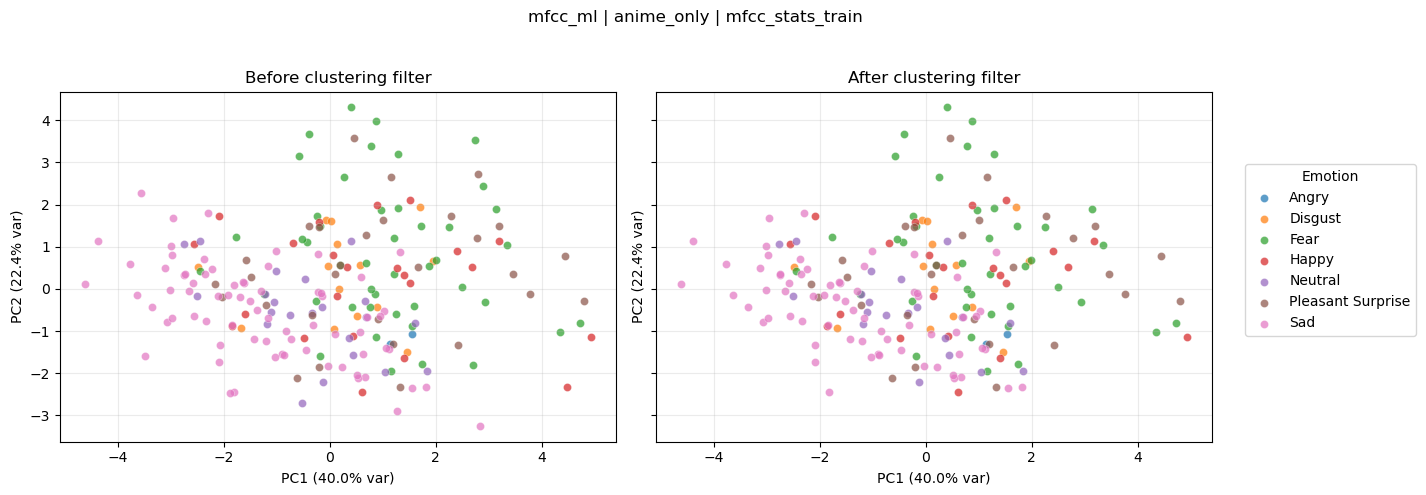

,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
1,mfcc_ml,anime_only,RF,0.471698,0.359376,0.364694,0.354284
2,mfcc_ml,anime_only,k-NN,0.433962,0.386735,0.360479,0.347093
3,mfcc_ml,anime_only,NB,0.433962,0.287698,0.349754,0.305148
4,mfcc_ml,anime_only,SVM,0.396226,0.315816,0.323683,0.299667


In [27]:
# Example:
BRANCH = "mfcc_ml"   # "mfcc_ml", "mel_cnn", "text_only", or "audio_text_fusion"
MODE = "anime_only"  # "anime_only" or "transfer_clean_to_anime" in this derived notebook

single_results_df, single_artifacts = run_experiment(BRANCH, MODE, meta_filtered_df)
display(single_results_df)

## 11. Confusion matrix helper


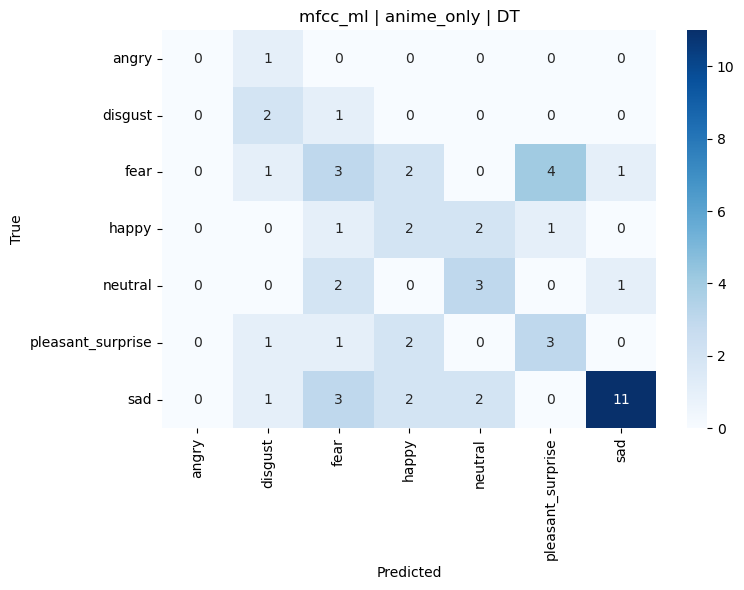

In [28]:
def plot_confusion_from_preds(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(EMOTIONS))))
    cm_df = pd.DataFrame(cm, index=EMOTIONS, columns=EMOTIONS)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

# Example:
best_row = single_results_df.sort_values(["macro_f1", "accuracy"], ascending=False).iloc[0]
best_model_name = best_row["model_name"]
y_true = single_artifacts["y_test"]
y_pred = single_artifacts["predictions"][best_model_name]
plot_confusion_from_preds(y_true, y_pred, f"{BRANCH} | {MODE} | {best_model_name}")


## 12. Run all experiments


Running 10 experiments
Cluster filter mfcc_ml | anime_only | mfcc_stats_train: kept 195/208 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,41,4
3,happy,Happy,23,22,1
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,29,28,1
6,sad,Sad,73,68,5


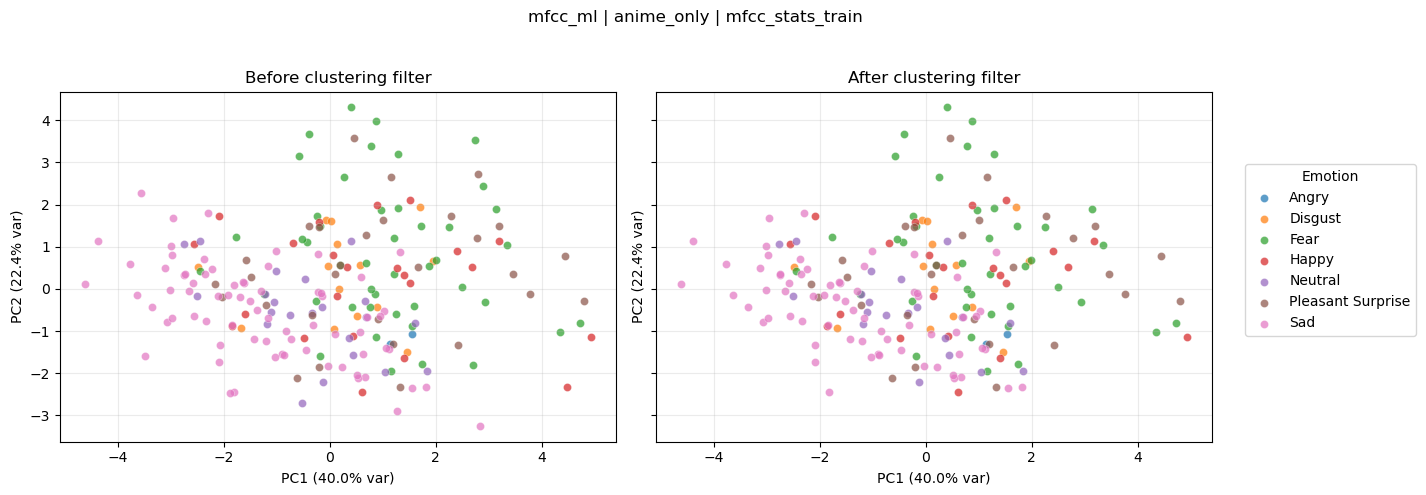

[OK] mfcc_ml | anime_only
Cluster filter mfcc_ml | transfer_clean_to_anime | mfcc_stats_train: kept 2660/2803 (removed 143)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,377,23
1,disgust,Disgust,400,393,7
2,fear,Fear,401,377,24
3,happy,Happy,401,380,21
4,neutral,Neutral,400,369,31
5,pleasant_surprise,Pleasant Surprise,401,382,19
6,sad,Sad,400,382,18


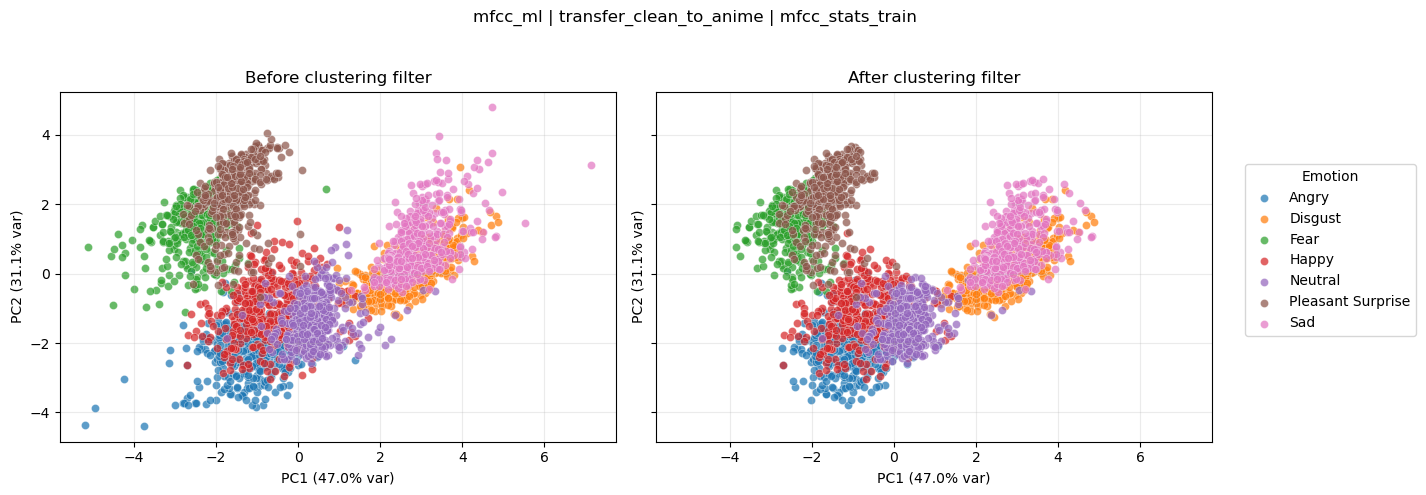

[OK] mfcc_ml | transfer_clean_to_anime
Cluster filter mel_cnn | anime_only | cnn_embedding_train: kept 195/208 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,43,2
3,happy,Happy,23,20,3
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,29,26,3
6,sad,Sad,73,70,3


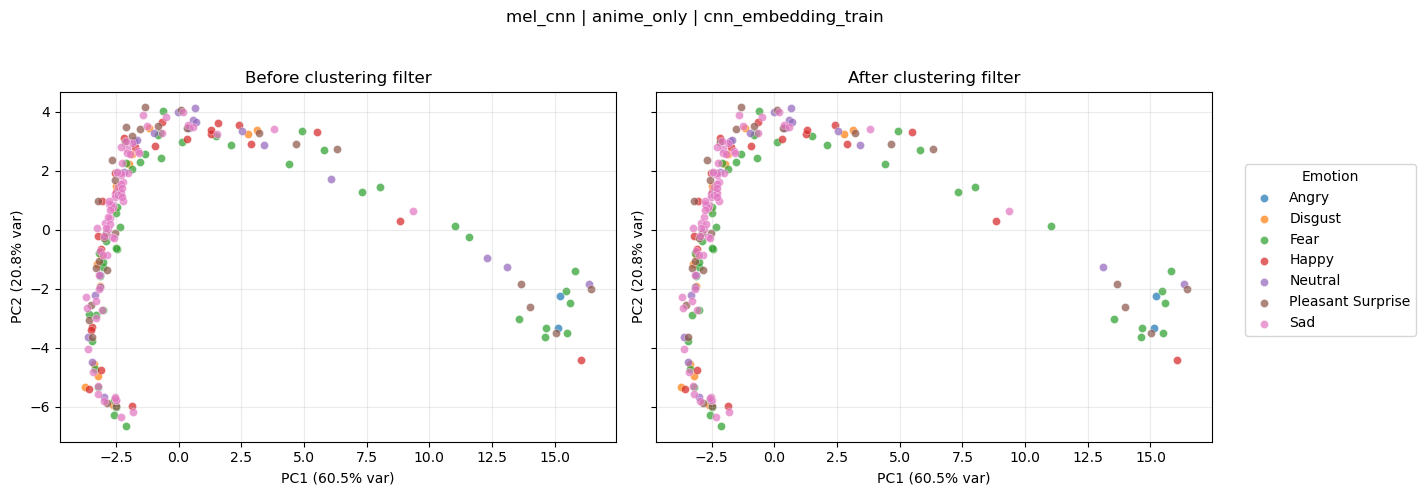

[OK] mel_cnn | anime_only
Cluster filter mel_cnn | transfer_clean_to_anime | source_cnn_embedding_train: kept 2659/2803 (removed 144)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,389,11
1,disgust,Disgust,400,390,10
2,fear,Fear,401,392,9
3,happy,Happy,401,355,46
4,neutral,Neutral,400,378,22
5,pleasant_surprise,Pleasant Surprise,401,387,14
6,sad,Sad,400,368,32


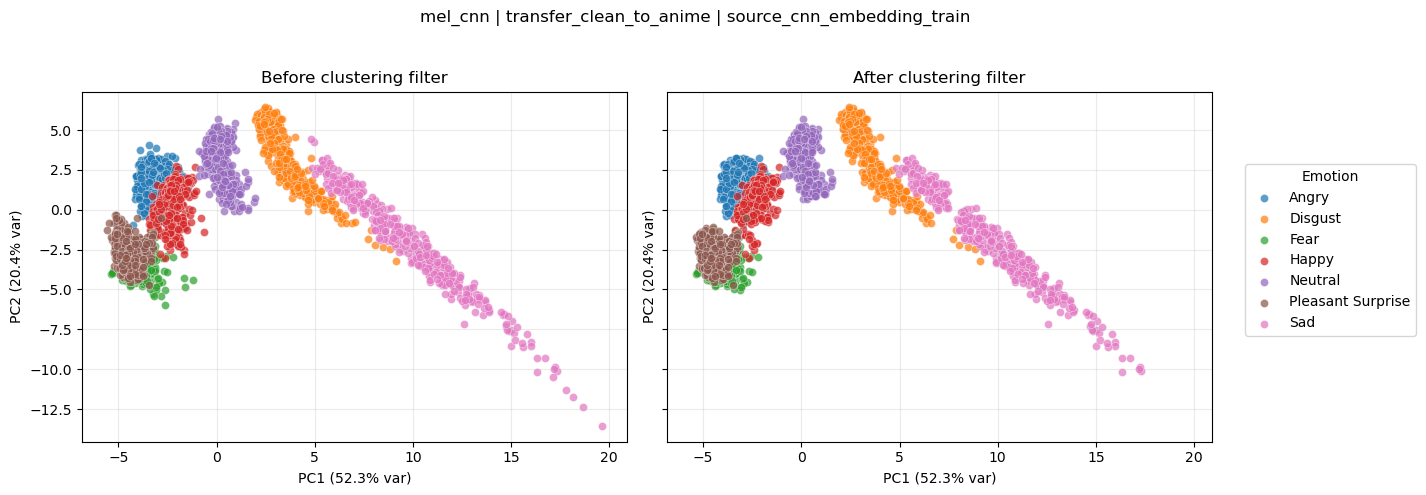

Cluster filter mel_cnn | transfer_clean_to_anime | anime_cnn_embedding_train: kept 194/208 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,41,4
3,happy,Happy,23,21,2
4,neutral,Neutral,22,19,3
5,pleasant_surprise,Pleasant Surprise,29,27,2
6,sad,Sad,73,70,3


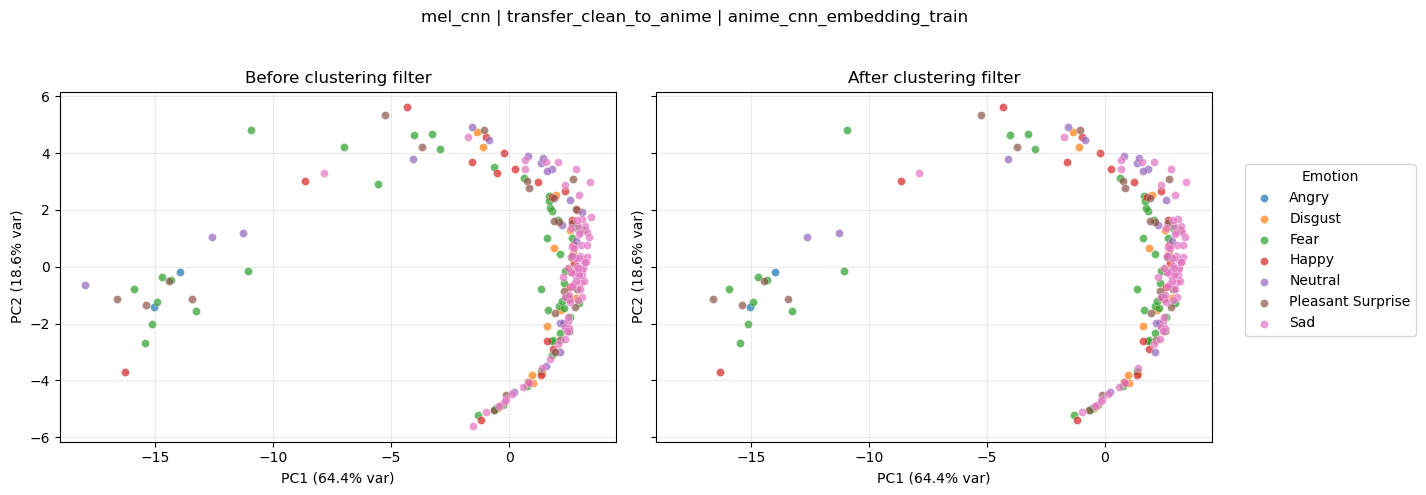

[OK] mel_cnn | transfer_clean_to_anime
Text train split: dropped 208 rows without real matched transcripts.
[FAIL] text_only | anime_only -> Text train split has no rows with real matched transcripts.
Text train split: dropped 2803 rows without real matched transcripts.
[FAIL] text_only | transfer_clean_to_anime -> Text train split has no rows with real matched transcripts.
Cluster filter mel_cnn | anime_only | cnn_embedding_train: kept 194/208 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,43,2
3,happy,Happy,23,18,5
4,neutral,Neutral,22,19,3
5,pleasant_surprise,Pleasant Surprise,29,26,3
6,sad,Sad,73,72,1


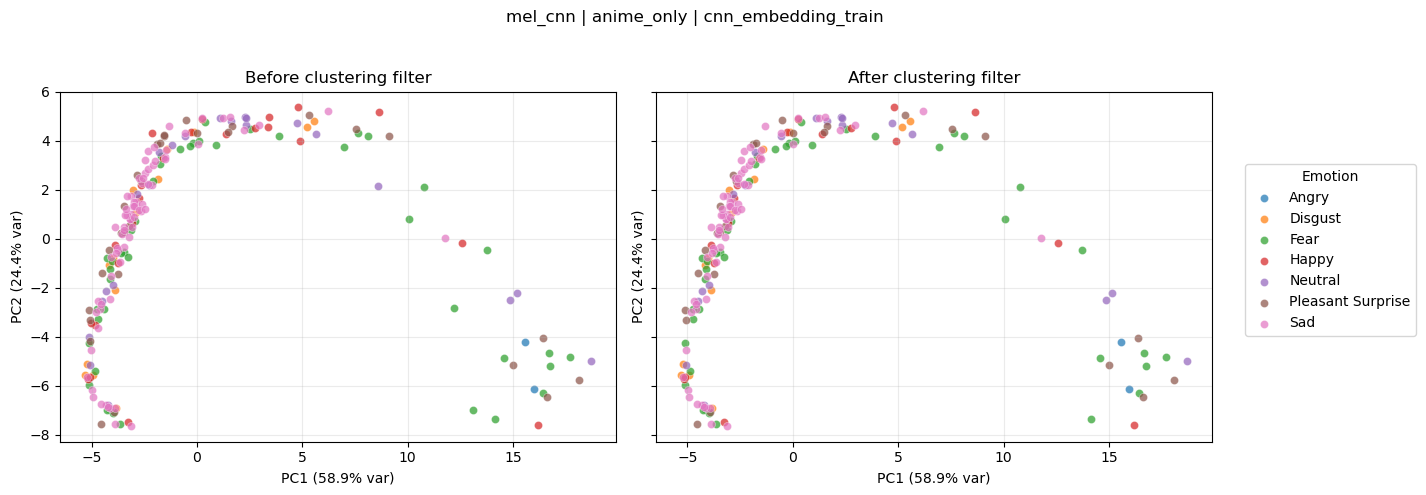

Fusion text train split: dropped 504 rows without real matched transcripts.
[FAIL] audio_text_fusion | anime_only -> Fusion text train split has no rows with real matched transcripts.
Cluster filter mel_cnn | transfer_clean_to_anime | source_cnn_embedding_train: kept 2659/2803 (removed 144)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,395,5
1,disgust,Disgust,400,377,23
2,fear,Fear,401,372,29
3,happy,Happy,401,374,27
4,neutral,Neutral,400,386,14
5,pleasant_surprise,Pleasant Surprise,401,381,20
6,sad,Sad,400,374,26


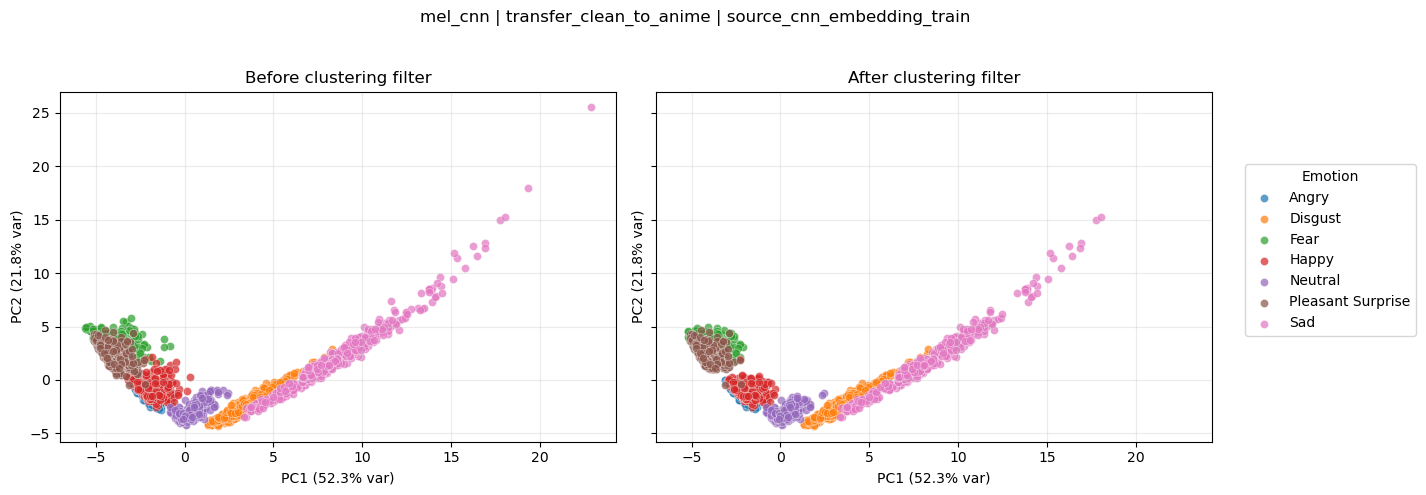

Cluster filter mel_cnn | transfer_clean_to_anime | anime_cnn_embedding_train: kept 195/208 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,42,3
3,happy,Happy,23,23,0
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,29,26,3
6,sad,Sad,73,68,5


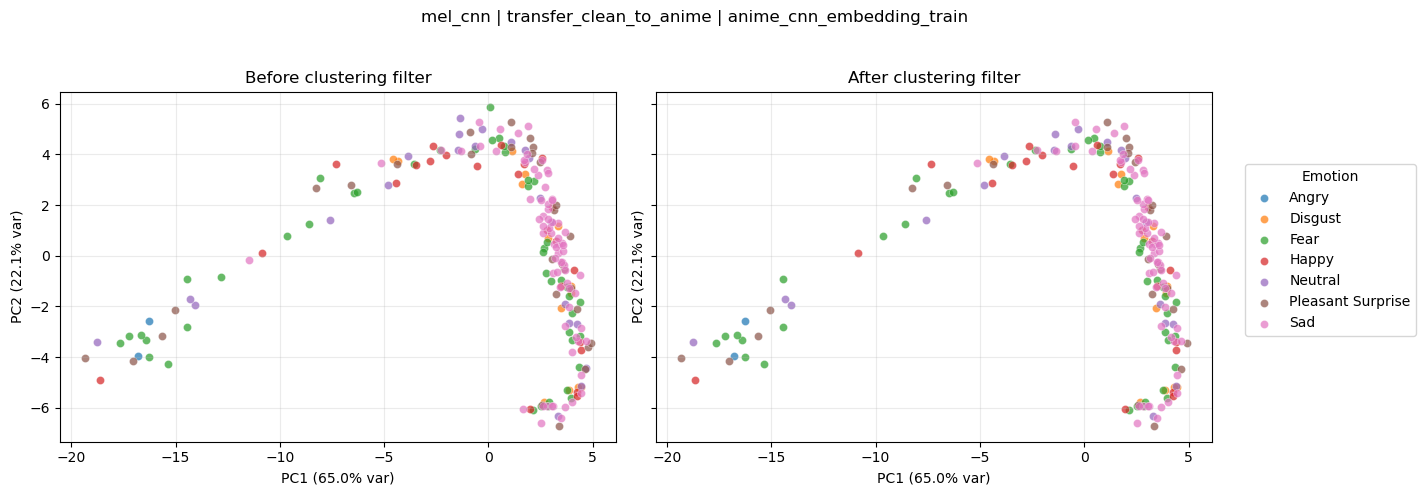

Fusion text train split: dropped 195 rows without real matched transcripts.
[FAIL] audio_text_fusion | transfer_clean_to_anime -> Fusion text train split has no rows with real matched transcripts.
Cluster filter mel_cnn_bilstm | anime_only | bilstm_embedding_train: kept 194/208 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,42,3
3,happy,Happy,23,21,2
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,29,25,4
6,sad,Sad,73,70,3


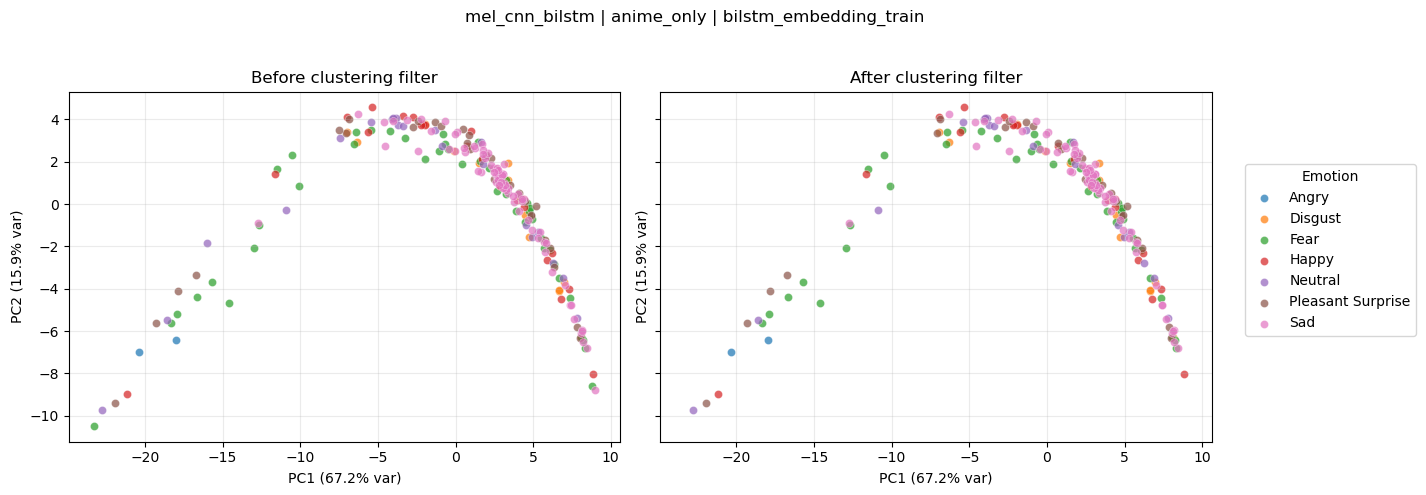

[OK] mel_cnn_bilstm | anime_only
Cluster filter opensmile_xgb | anime_only | opensmile_lld_train: kept 194/208 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,2,2,0
1,disgust,Disgust,14,14,0
2,fear,Fear,45,42,3
3,happy,Happy,23,22,1
4,neutral,Neutral,22,21,1
5,pleasant_surprise,Pleasant Surprise,29,24,5
6,sad,Sad,73,69,4


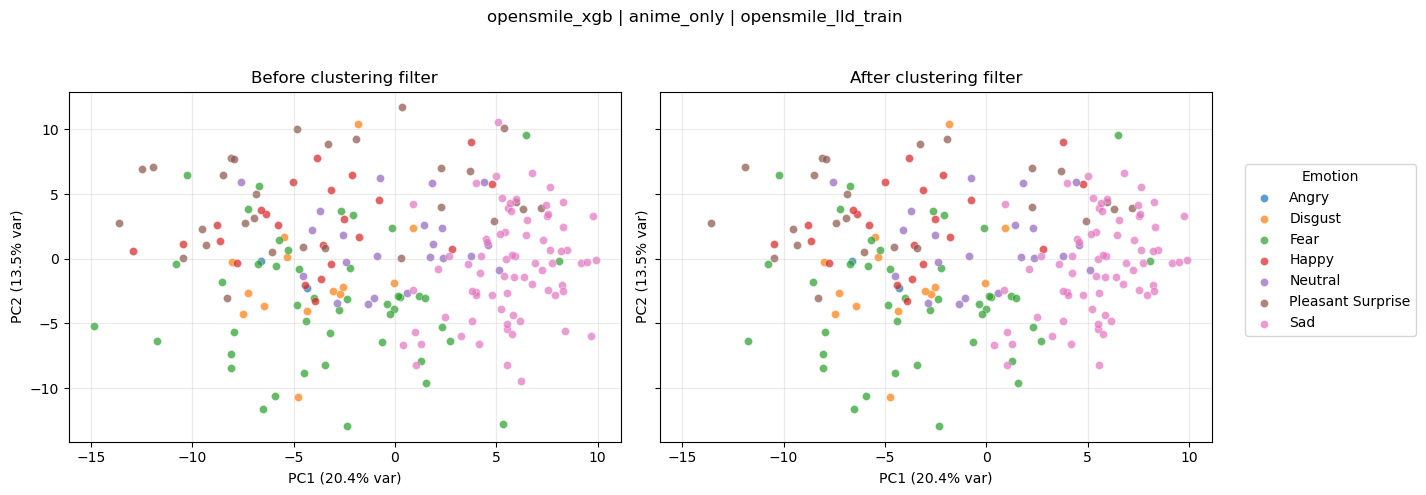

[OK] opensmile_xgb | anime_only


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,mel_cnn,anime_only,SimpleMelCNN,0.452830,0.393103,0.410344,0.393607
2,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
3,mfcc_ml,anime_only,RF,0.471698,0.359376,0.364694,0.354284
4,mfcc_ml,anime_only,k-NN,0.433962,0.386735,0.360479,0.347093
5,mfcc_ml,anime_only,NB,0.433962,0.287698,0.349754,0.305148
6,mfcc_ml,anime_only,SVM,0.396226,0.315816,0.323683,0.299667
7,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.339623,0.272153,0.318214,0.258292
8,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.169811,0.107069,0.393939,0.147733
9,mfcc_ml,transfer_clean_to_anime,DT,0.075472,0.042624,0.214286,0.057563


Best row per branch/mode:


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,mel_cnn,anime_only,SimpleMelCNN,0.452830,0.393103,0.410344,0.393607
2,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
3,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.339623,0.272153,0.318214,0.258292
4,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.169811,0.107069,0.393939,0.147733
5,mfcc_ml,transfer_clean_to_anime,DT,0.075472,0.042624,0.214286,0.057563


Automatic detailed inspection -> opensmile_xgb | anime_only | openSMILE_LLD_XGBoost


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.50941,0.505875,0.502864


Classification report for opensmile_xgb | anime_only | openSMILE_LLD_XGBoost
                   precision    recall  f1-score   support

            angry     0.0000    0.0000    0.0000         1
          disgust     0.5000    0.3333    0.4000         3
             fear     0.7000    0.6364    0.6667        11
            happy     0.4000    0.3333    0.3636         6
          neutral     0.5714    0.6667    0.6154         6
pleasant_surprise     0.4444    0.5714    0.5000         7
              sad     0.9500    1.0000    0.9744        19

         accuracy                         0.6981        53
        macro avg     0.5094    0.5059    0.5029        53
     weighted avg     0.6828    0.6981    0.6872        53



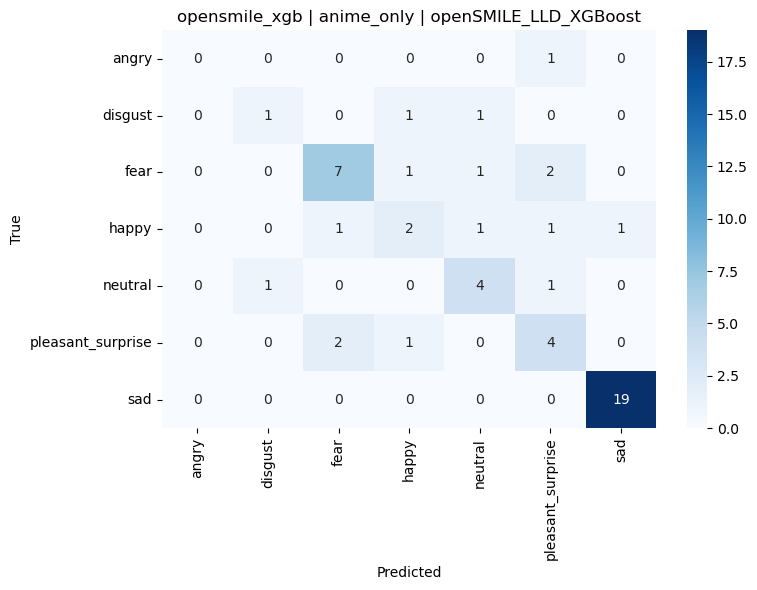

Elapsed: 23.19 min


In [29]:
EXPERIMENTS = FULL_EXPERIMENTS.copy()
print(f"Running {len(EXPERIMENTS)} experiments")

all_results = []
all_artifacts = {}

run_start = time.perf_counter()

for exp in EXPERIMENTS:
    branch = exp["branch"]
    mode = exp["mode"]
    try:
        result_df, artifacts = run_experiment(branch, mode, meta_filtered_df)
        all_results.append(result_df)
        all_artifacts[(branch, mode)] = artifacts
        print(f"[OK] {branch} | {mode}")
    except Exception as e:
        print(f"[FAIL] {branch} | {mode} -> {e}")

if all_results:
    experiment_results_df = pd.concat(all_results, ignore_index=True)
    experiment_results_df = experiment_results_df.sort_values(
        ["macro_f1", "accuracy"], ascending=False
    ).reset_index(drop=True)
    display(experiment_results_df)

    best_by_branch_mode = (
        experiment_results_df.sort_values(["macro_f1", "accuracy"], ascending=False)
        .groupby(["branch", "mode"], as_index=False)
        .first()
        .sort_values(["macro_f1", "accuracy"], ascending=False)
        .reset_index(drop=True)
    )
    print("Best row per branch/mode:")
    display(best_by_branch_mode)

    auto_branch = globals().get("AUTO_INSPECT_BRANCH", None)
    auto_mode = globals().get("AUTO_INSPECT_MODE", None)
    auto_model_name = globals().get("AUTO_INSPECT_MODEL_NAME", None)

    if auto_branch is None or auto_mode is None or (auto_branch, auto_mode) not in all_artifacts:
        auto_branch = experiment_results_df.iloc[0]["branch"]
        auto_mode = experiment_results_df.iloc[0]["mode"]
        auto_model_name = experiment_results_df.iloc[0]["model_name"]
        print(f"Automatic detailed inspection -> {auto_branch} | {auto_mode} | {auto_model_name}")
    else:
        print(f"Automatic detailed inspection override -> {auto_branch} | {auto_mode}")

    inspect_rows = experiment_results_df[
        (experiment_results_df["branch"] == auto_branch) & (experiment_results_df["mode"] == auto_mode)
    ].sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)

    if not inspect_rows.empty:
        display(inspect_rows)

        if auto_model_name is None or auto_model_name not in inspect_rows["model_name"].astype(str).tolist():
            auto_model_name = inspect_rows.iloc[0]["model_name"]

        inspect_artifacts = all_artifacts[(auto_branch, auto_mode)]

        if "predictions" in inspect_artifacts and "y_test" in inspect_artifacts:
            if auto_model_name not in inspect_artifacts["predictions"]:
                auto_model_name = inspect_rows.iloc[0]["model_name"]
            inspect_y_true_ids = np.asarray(inspect_artifacts["y_test"]).astype(int)
            inspect_y_pred_ids = np.asarray(inspect_artifacts["predictions"][auto_model_name]).astype(int)
            inspect_y_true_labels = label_encoder.inverse_transform(inspect_y_true_ids).tolist()
            inspect_y_pred_labels = label_encoder.inverse_transform(inspect_y_pred_ids).tolist()
        elif "y_true" in inspect_artifacts and "y_pred" in inspect_artifacts:
            inspect_y_true_labels = [str(x) for x in inspect_artifacts["y_true"]]
            inspect_y_pred_labels = [str(x) for x in inspect_artifacts["y_pred"]]
        else:
            raise ValueError(
                f"Artifacts for {auto_branch} | {auto_mode} do not include predictions in a supported format."
            )

        print(f"Classification report for {auto_branch} | {auto_mode} | {auto_model_name}")
        print(
            classification_report(
                inspect_y_true_labels,
                inspect_y_pred_labels,
                labels=EMOTIONS,
                target_names=EMOTIONS,
                digits=4,
                zero_division=0,
            )
        )

        if set(inspect_y_true_labels).issubset(set(EMOTIONS)) and set(inspect_y_pred_labels).issubset(set(EMOTIONS)):
            plot_confusion_from_preds(
                [EMOTIONS.index(label) for label in inspect_y_true_labels],
                [EMOTIONS.index(label) for label in inspect_y_pred_labels],
                f"{auto_branch} | {auto_mode} | {auto_model_name}",
            )
        else:
            print("Skipping confusion matrix because labels do not map cleanly to the shared EMOTIONS list.")
else:
    experiment_results_df = pd.DataFrame()

elapsed = time.perf_counter() - run_start
print(f"Elapsed: {elapsed/60:.2f} min")

## 13. Comparison views


## 13.1 Compare before vs filtered input

This section now runs a real comparison between the balanced dataset before audio-quality filtering and the strict filtered dataset after audio-quality filtering.

Running 10 experiments on before_filter (3076 rows)
Cluster filter mfcc_ml | anime_only | mfcc_stats_train: kept 205/218 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,2,1
1,disgust,Disgust,18,18,0
2,fear,Fear,46,43,3
3,happy,Happy,24,22,2
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,31,31,0
6,sad,Sad,74,69,5


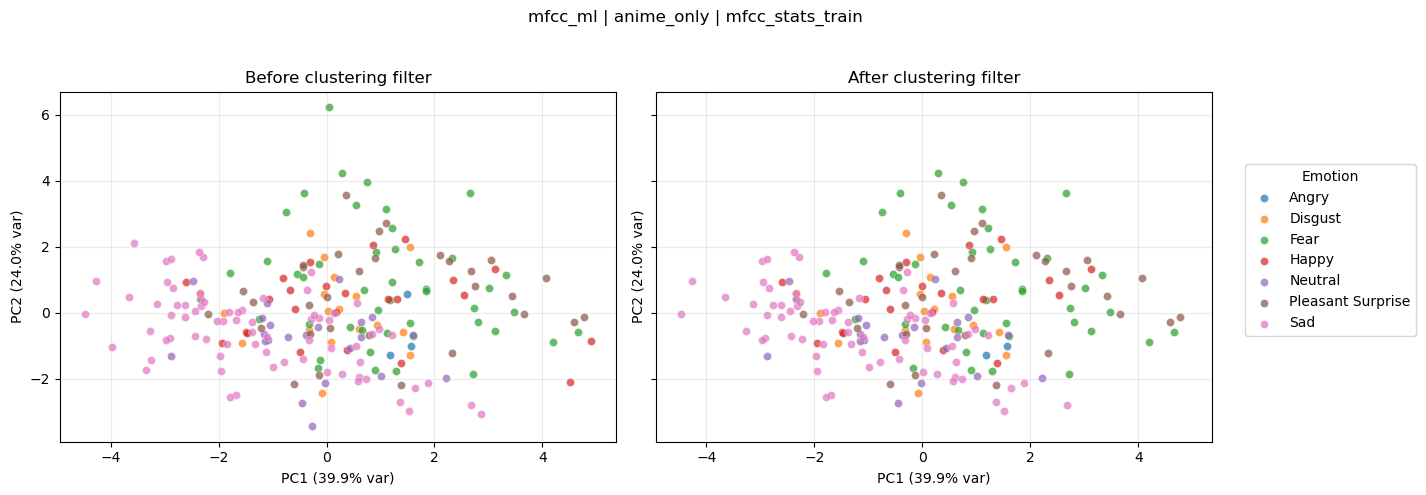

[OK] before_filter -> mfcc_ml | anime_only
Cluster filter mfcc_ml | transfer_clean_to_anime | mfcc_stats_train: kept 2660/2803 (removed 143)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,377,23
1,disgust,Disgust,400,393,7
2,fear,Fear,401,377,24
3,happy,Happy,401,380,21
4,neutral,Neutral,400,369,31
5,pleasant_surprise,Pleasant Surprise,401,382,19
6,sad,Sad,400,382,18


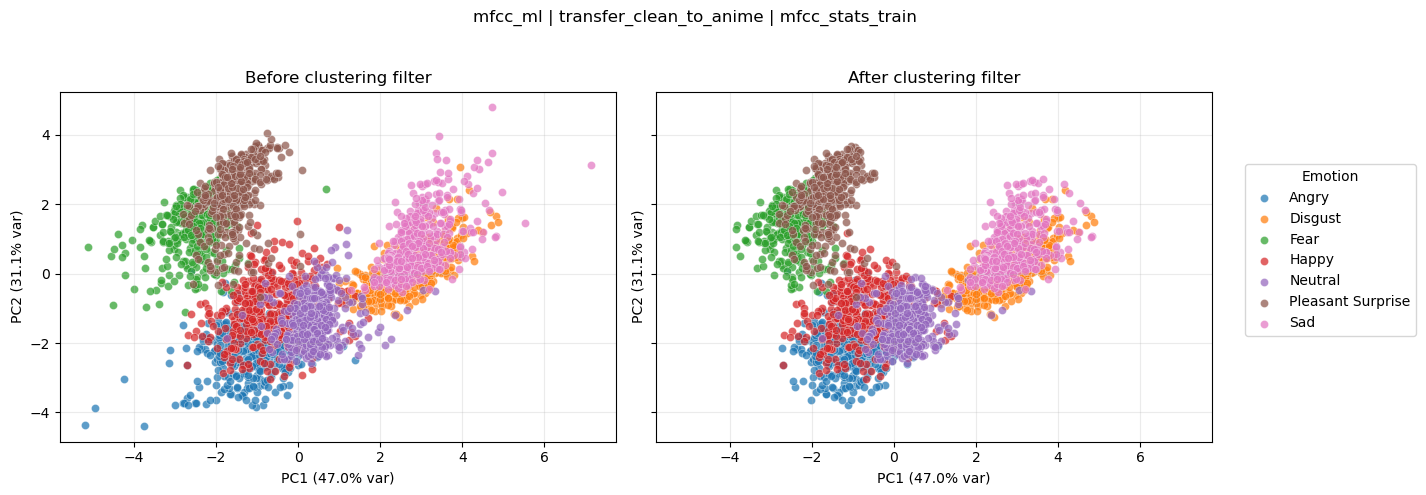

[OK] before_filter -> mfcc_ml | transfer_clean_to_anime
Cluster filter mel_cnn | anime_only | cnn_embedding_train: kept 204/218 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,17,1
2,fear,Fear,46,42,4
3,happy,Happy,24,23,1
4,neutral,Neutral,22,20,2
5,pleasant_surprise,Pleasant Surprise,31,29,2
6,sad,Sad,74,70,4


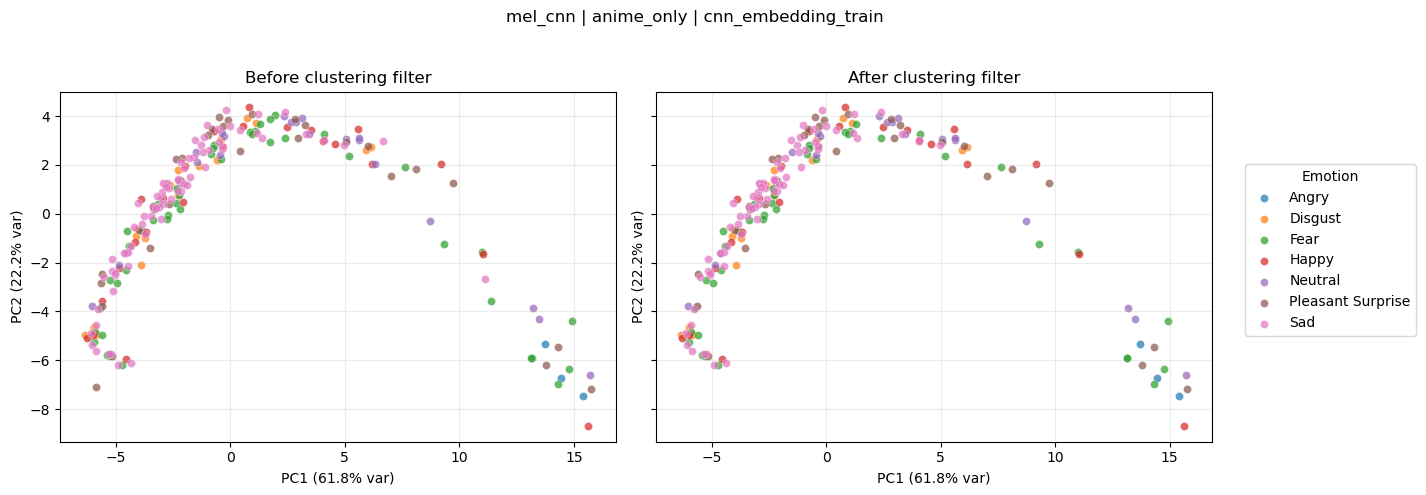

[OK] before_filter -> mel_cnn | anime_only
Cluster filter mel_cnn | transfer_clean_to_anime | source_cnn_embedding_train: kept 2659/2803 (removed 144)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,375,25
1,disgust,Disgust,400,385,15
2,fear,Fear,401,365,36
3,happy,Happy,401,384,17
4,neutral,Neutral,400,381,19
5,pleasant_surprise,Pleasant Surprise,401,396,5
6,sad,Sad,400,373,27


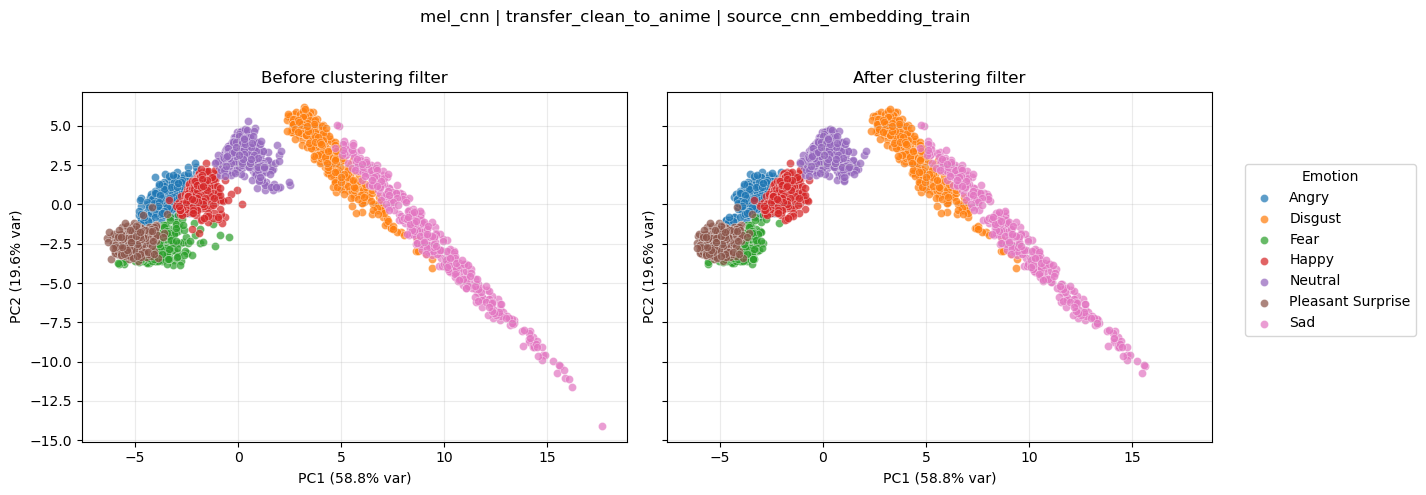

Cluster filter mel_cnn | transfer_clean_to_anime | anime_cnn_embedding_train: kept 204/218 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,18,0
2,fear,Fear,46,44,2
3,happy,Happy,24,23,1
4,neutral,Neutral,22,21,1
5,pleasant_surprise,Pleasant Surprise,31,26,5
6,sad,Sad,74,69,5


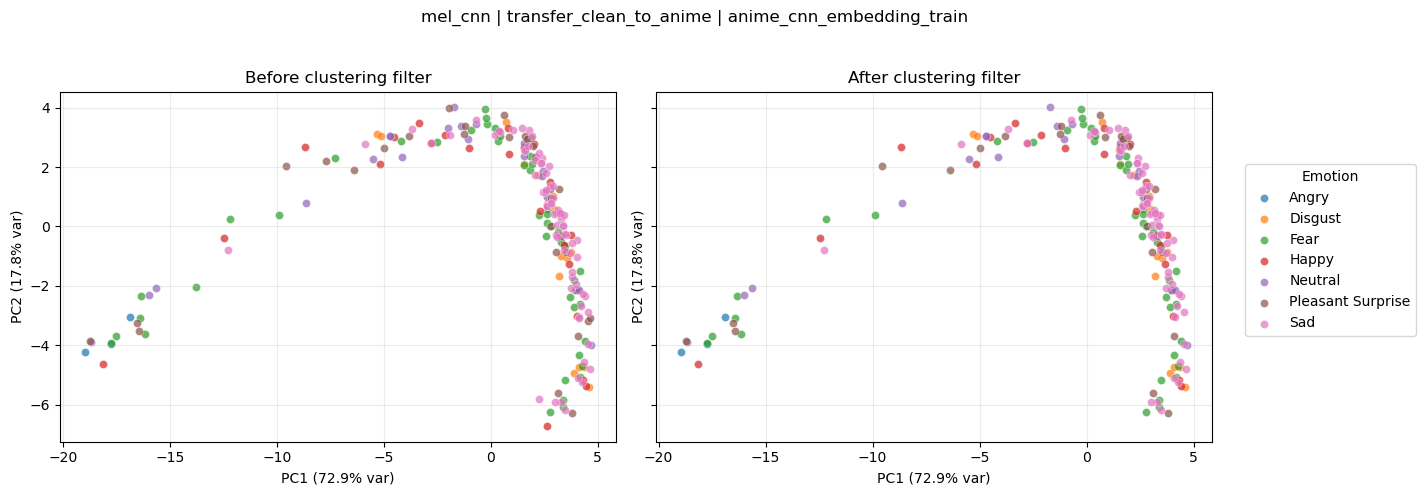

[OK] before_filter -> mel_cnn | transfer_clean_to_anime
Text train split: dropped 218 rows without real matched transcripts.
[FAIL] before_filter -> text_only | anime_only -> Text train split has no rows with real matched transcripts.
Text train split: dropped 2803 rows without real matched transcripts.
[FAIL] before_filter -> text_only | transfer_clean_to_anime -> Text train split has no rows with real matched transcripts.
Cluster filter mel_cnn | anime_only | cnn_embedding_train: kept 204/218 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,17,1
2,fear,Fear,46,44,2
3,happy,Happy,24,21,3
4,neutral,Neutral,22,21,1
5,pleasant_surprise,Pleasant Surprise,31,29,2
6,sad,Sad,74,69,5


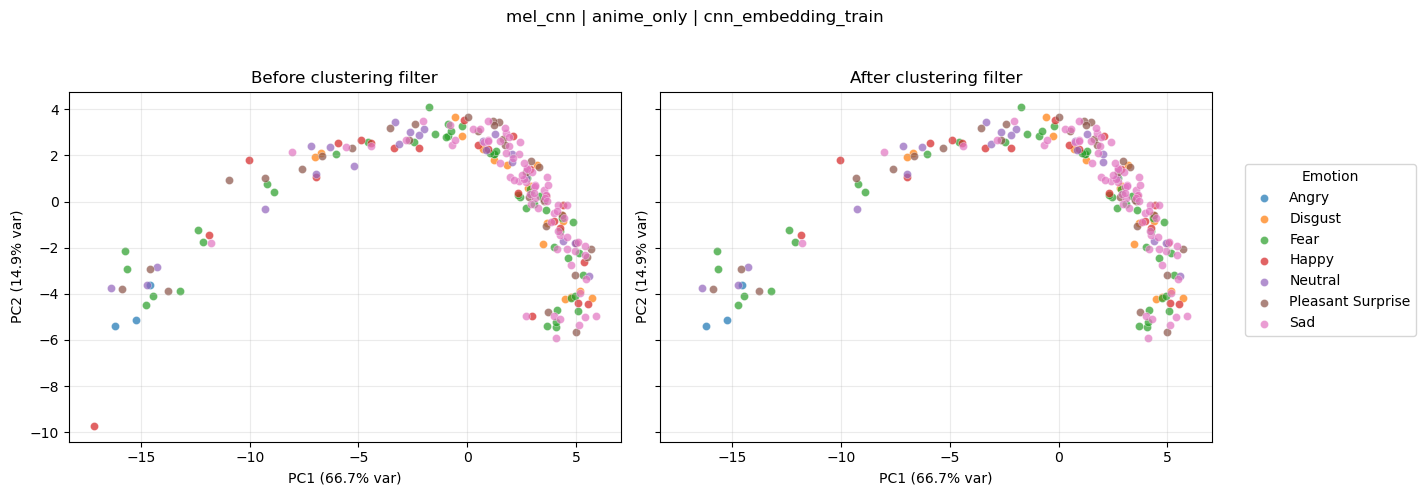

Fusion text train split: dropped 483 rows without real matched transcripts.
[FAIL] before_filter -> audio_text_fusion | anime_only -> Fusion text train split has no rows with real matched transcripts.
Cluster filter mel_cnn | transfer_clean_to_anime | source_cnn_embedding_train: kept 2660/2803 (removed 143)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,400,392,8
1,disgust,Disgust,400,383,17
2,fear,Fear,401,361,40
3,happy,Happy,401,376,25
4,neutral,Neutral,400,379,21
5,pleasant_surprise,Pleasant Surprise,401,393,8
6,sad,Sad,400,376,24


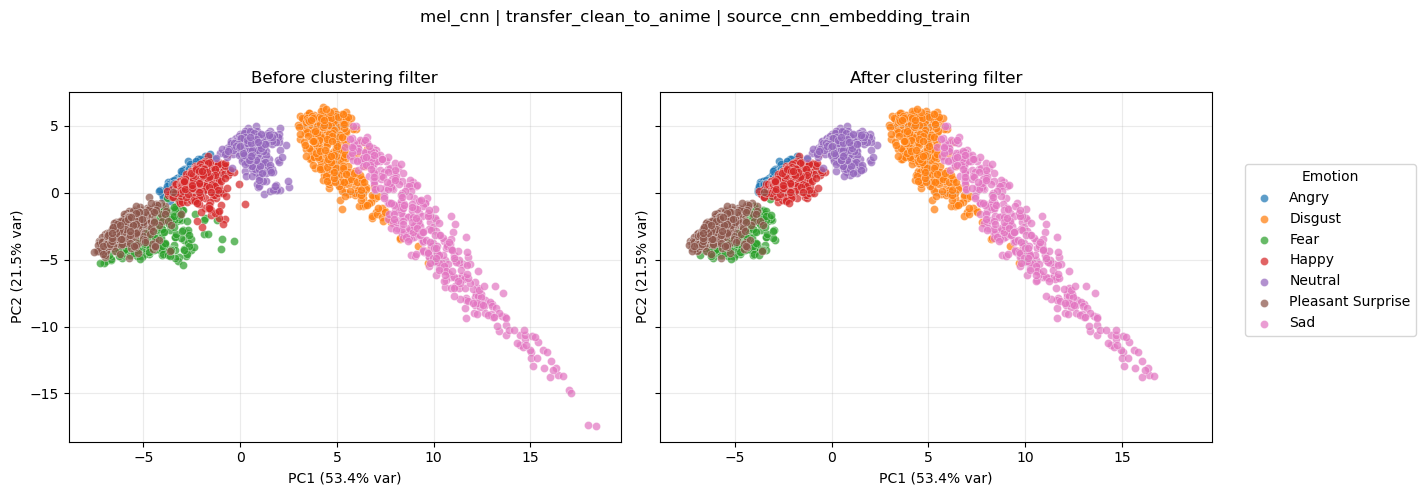

Cluster filter mel_cnn | transfer_clean_to_anime | anime_cnn_embedding_train: kept 205/218 (removed 13)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,18,0
2,fear,Fear,46,42,4
3,happy,Happy,24,21,3
4,neutral,Neutral,22,21,1
5,pleasant_surprise,Pleasant Surprise,31,29,2
6,sad,Sad,74,71,3


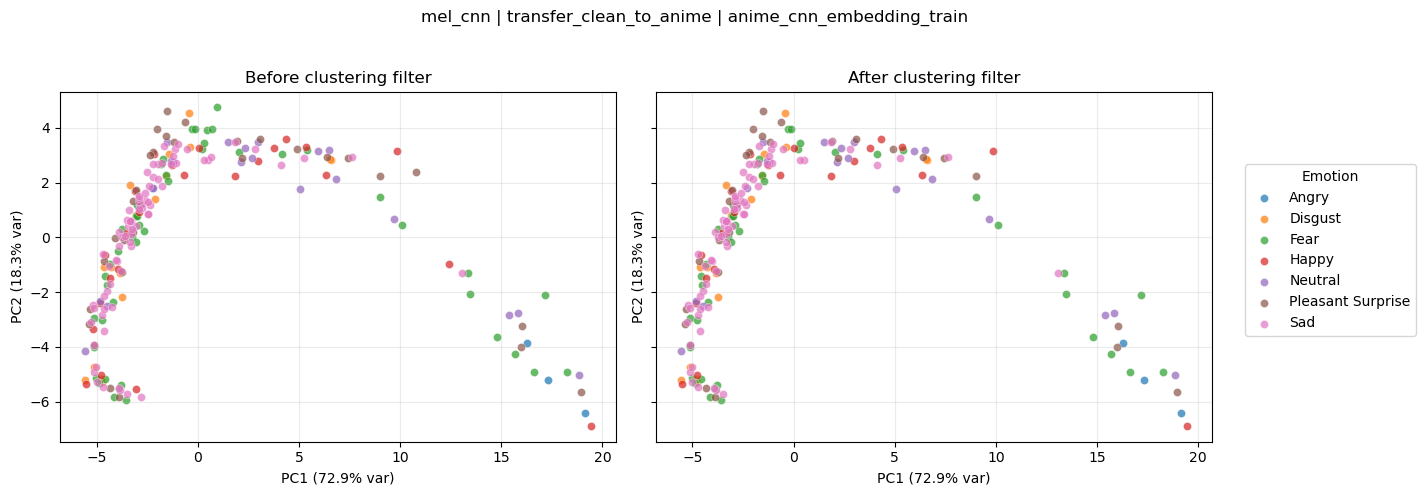

Fusion text train split: dropped 205 rows without real matched transcripts.
[FAIL] before_filter -> audio_text_fusion | transfer_clean_to_anime -> Fusion text train split has no rows with real matched transcripts.
Cluster filter mel_cnn_bilstm | anime_only | bilstm_embedding_train: kept 204/218 (removed 14)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,18,0
2,fear,Fear,46,41,5
3,happy,Happy,24,22,2
4,neutral,Neutral,22,22,0
5,pleasant_surprise,Pleasant Surprise,31,29,2
6,sad,Sad,74,69,5


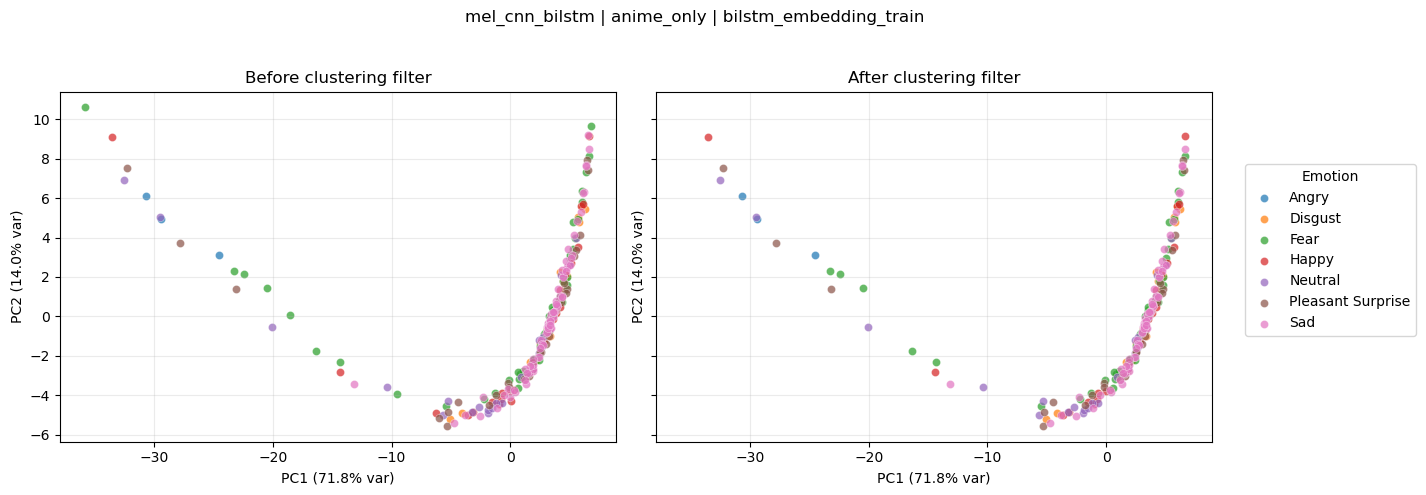

[OK] before_filter -> mel_cnn_bilstm | anime_only
Cluster filter opensmile_xgb | anime_only | opensmile_lld_train: kept 203/218 (removed 15)
Remaining samples per emotion after clustering filter:


,emotion,display_name,before_filter,remain_after_filter,removed_by_clustering
0,angry,Angry,3,3,0
1,disgust,Disgust,18,17,1
2,fear,Fear,46,42,4
3,happy,Happy,24,24,0
4,neutral,Neutral,22,21,1
5,pleasant_surprise,Pleasant Surprise,31,25,6
6,sad,Sad,74,71,3


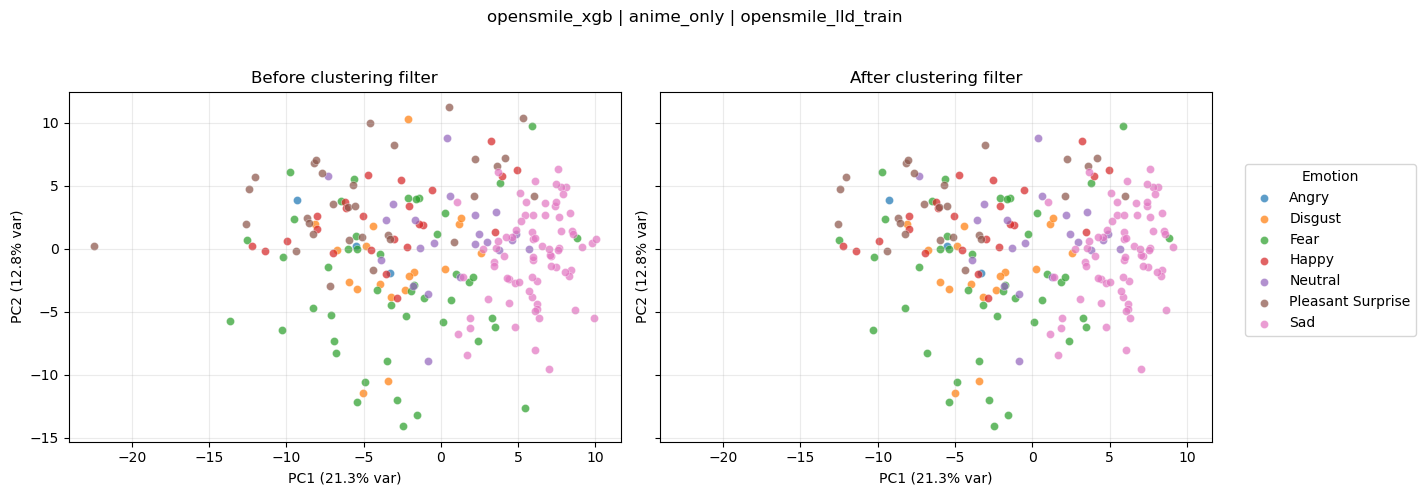

[OK] before_filter -> opensmile_xgb | anime_only
Before-filter experiment results


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.781818,0.651211,0.629386,0.618244
1,mfcc_ml,anime_only,SVM,0.490909,0.393594,0.384712,0.383292
2,mfcc_ml,anime_only,NB,0.454545,0.376638,0.395102,0.375210
3,mfcc_ml,anime_only,RF,0.418182,0.367869,0.337719,0.341742
4,mfcc_ml,anime_only,k-NN,0.418182,0.378355,0.338659,0.322301
5,mel_cnn,anime_only,SimpleMelCNN,0.454545,0.340887,0.342105,0.297109
6,mfcc_ml,anime_only,DT,0.254545,0.197090,0.203947,0.193473
7,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.127273,0.135714,0.136905,0.100994
8,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.327273,0.065934,0.135338,0.088670
9,mfcc_ml,transfer_clean_to_anime,NB,0.036364,0.014286,0.047619,0.021978


After-filter experiment results


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,mel_cnn,anime_only,SimpleMelCNN,0.452830,0.393103,0.410344,0.393607
2,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
3,mfcc_ml,anime_only,RF,0.471698,0.359376,0.364694,0.354284
4,mfcc_ml,anime_only,k-NN,0.433962,0.386735,0.360479,0.347093
5,mfcc_ml,anime_only,NB,0.433962,0.287698,0.349754,0.305148
6,mfcc_ml,anime_only,SVM,0.396226,0.315816,0.323683,0.299667
7,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.339623,0.272153,0.318214,0.258292
8,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.169811,0.107069,0.393939,0.147733
9,mfcc_ml,transfer_clean_to_anime,DT,0.075472,0.042624,0.214286,0.057563


In [30]:
def run_experiment_suite(experiments, meta_df, label):
    if meta_df is None or len(meta_df) == 0:
        raise ValueError(f"{label} metadata is empty.")

    suite_results = []
    suite_artifacts = {}

    print(f"Running {len(experiments)} experiments on {label} ({len(meta_df)} rows)")
    for exp in experiments:
        branch = exp["branch"]
        mode = exp["mode"]
        try:
            result_df, artifacts = run_experiment(branch, mode, meta_df)
            suite_results.append(result_df)
            suite_artifacts[(branch, mode)] = artifacts
            print(f"[OK] {label} -> {branch} | {mode}")
        except Exception as e:
            print(f"[FAIL] {label} -> {branch} | {mode} -> {e}")

    if not suite_results:
        raise ValueError(f"No experiment results were produced for {label}.")

    results_df = pd.concat(suite_results, ignore_index=True)
    results_df = results_df.sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
    return results_df, suite_artifacts


def summarize_best_results(df, title="Results"):
    print(title)
    display(
        df.sort_values(["macro_f1", "accuracy"], ascending=False)
          .reset_index(drop=True)
    )


if "meta_limited_df" not in globals() or meta_limited_df.empty:
    raise ValueError("Run dataset limiting first so the before-filter comparison can use meta_limited_df.")
if "meta_filtered_df" not in globals() or meta_filtered_df.empty:
    raise ValueError("Run metadata filtering first so the after-filter comparison can use meta_filtered_df.")

comparison_experiments = FULL_EXPERIMENTS.copy()
before_filter_results_df, before_filter_artifacts = run_experiment_suite(
    comparison_experiments,
    meta_limited_df,
    "before_filter",
)

filtered_results_for_compare_df = experiment_results_df.copy() if "experiment_results_df" in globals() and len(experiment_results_df) else None
filtered_artifacts_for_compare = all_artifacts.copy() if "all_artifacts" in globals() and len(all_artifacts) else {}

if filtered_results_for_compare_df is None:
    filtered_results_for_compare_df, filtered_artifacts_for_compare = run_experiment_suite(
        comparison_experiments,
        meta_filtered_df,
        "after_filter",
    )

summarize_best_results(before_filter_results_df, "Before-filter experiment results")
summarize_best_results(filtered_results_for_compare_df, "After-filter experiment results")

Before vs after filtering comparison (sorted by final after-filter performance):


,Branch,Mode,Model,Accuracy before,Accuracy after,Delta accuracy,Macro-F1 before,Macro-F1 after,Delta Macro-F1
0,openSMILE,Anime only,LLD XGBoost,0.7818,0.6981,-0.0837,0.6182,0.5029,-0.1154
1,MelCNN,Anime only,SimpleMelCNN,0.4545,0.4528,-0.0017,0.2971,0.3936,0.0965
2,MFCC-ML,Anime only,DT,0.2545,0.4528,0.1983,0.1935,0.3646,0.1711
3,MFCC-ML,Anime only,RF,0.4182,0.4717,0.0535,0.3417,0.3543,0.0125
4,MFCC-ML,Anime only,k-NN,0.4182,0.4340,0.0158,0.3223,0.3471,0.0248
5,MFCC-ML,Anime only,NB,0.4545,0.4340,-0.0206,0.3752,0.3051,-0.0701
6,MFCC-ML,Anime only,SVM,0.4909,0.3962,-0.0947,0.3833,0.2997,-0.0836
7,MelCNN-BiLSTM,Anime only,CNN-BiLSTM,0.3273,0.3396,0.0123,0.0887,0.2583,0.1696
8,MelCNN,Transfer clean->anime,SimpleMelCNN,0.1273,0.1698,0.0425,0.1010,0.1477,0.0467
9,MFCC-ML,Transfer clean->anime,DT,0.0000,0.0755,0.0755,0.0000,0.0576,0.0576


Best after-filter row per branch/mode with before/after deltas:


,Branch,Mode,Best model,Accuracy before,Accuracy after,Delta accuracy,Macro-F1 before,Macro-F1 after,Delta Macro-F1
0,openSMILE,Anime only,LLD XGBoost,0.7818,0.6981,-0.0837,0.6182,0.5029,-0.1154
1,MelCNN,Anime only,SimpleMelCNN,0.4545,0.4528,-0.0017,0.2971,0.3936,0.0965
2,MFCC-ML,Anime only,DT,0.2545,0.4528,0.1983,0.1935,0.3646,0.1711
3,MelCNN-BiLSTM,Anime only,CNN-BiLSTM,0.3273,0.3396,0.0123,0.0887,0.2583,0.1696
4,MelCNN,Transfer clean->anime,SimpleMelCNN,0.1273,0.1698,0.0425,0.1010,0.1477,0.0467
5,MFCC-ML,Transfer clean->anime,DT,0.0000,0.0755,0.0755,0.0000,0.0576,0.0576


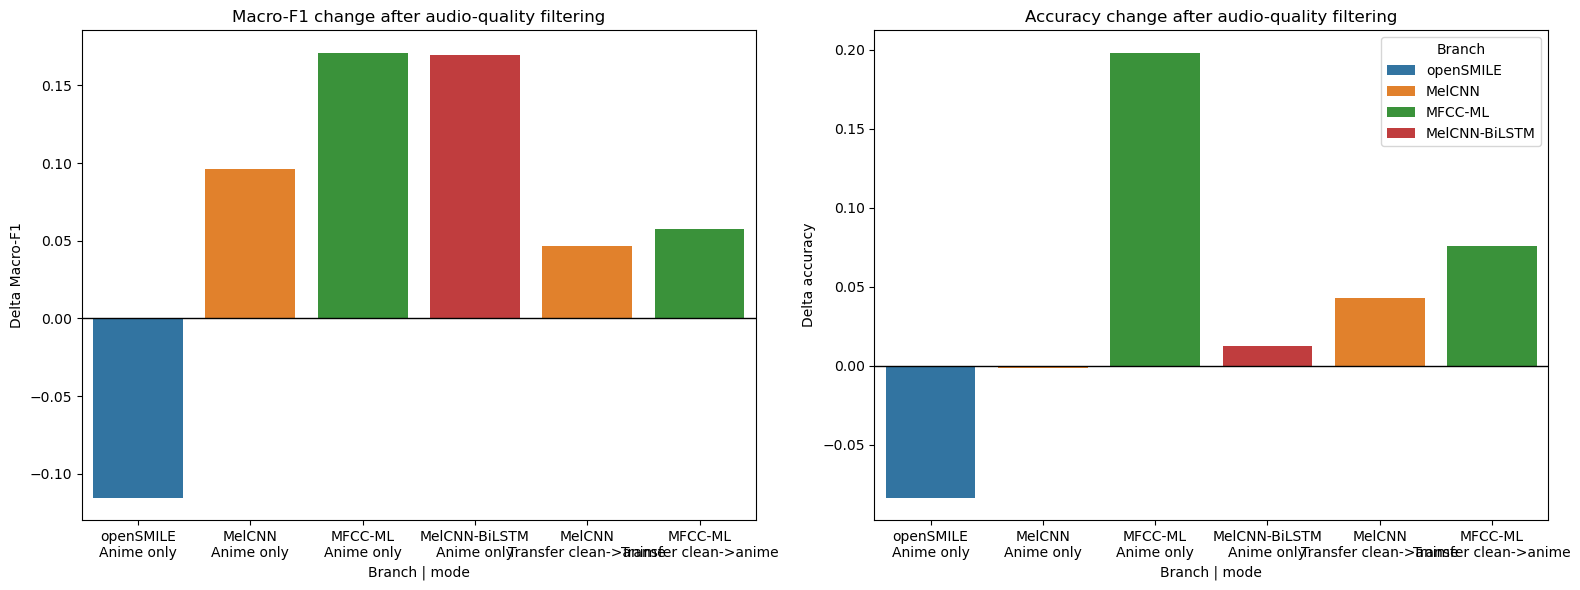

In [31]:
BRANCH_DISPLAY_NAMES = {
    "mfcc_ml": "MFCC-ML",
    "mel_cnn": "MelCNN",
    "text_only": "Text",
    "opensmile_xgb": "openSMILE",
    "mel_cnn_bilstm": "MelCNN-BiLSTM",
    "audio_text_fusion": "Fusion",
}

MODE_DISPLAY_NAMES = {
    "anime_only": "Anime only",
    "transfer_clean_to_anime": "Transfer clean->anime",
}

MODEL_DISPLAY_NAMES = {
    "RF": "RF",
    "SimpleMelCNN": "SimpleMelCNN",
    "TFIDF+LogRegText": "TFIDF+LogReg",
    "openSMILE_LLD_XGBoost": "LLD XGBoost",
    "CNNBiLSTM": "CNN-BiLSTM",
    "SimpleMelCNN+TFIDFLogRegFusion(0.40/0.60)": "Fusion 0.40/0.60",
}


def shorten_model_label(model_name, max_len=28):
    label = MODEL_DISPLAY_NAMES.get(str(model_name), str(model_name))
    if len(label) <= max_len:
        return label
    return label[: max_len - 3] + "..."


def format_branch_mode_label(branch, mode):
    branch_label = BRANCH_DISPLAY_NAMES.get(str(branch), str(branch))
    mode_label = MODE_DISPLAY_NAMES.get(str(mode), str(mode))
    return f"{branch_label}\n{mode_label}"


def format_branch_mode_title(branch, mode):
    branch_label = BRANCH_DISPLAY_NAMES.get(str(branch), str(branch))
    mode_label = MODE_DISPLAY_NAMES.get(str(mode), str(mode))
    return f"{branch_label} | {mode_label}"


comparison_before_after_df = before_filter_results_df.merge(
    filtered_results_for_compare_df,
    on=["branch", "mode", "model_name"],
    suffixes=("_before", "_after"),
)

comparison_before_after_df["delta_accuracy"] = (
    comparison_before_after_df["accuracy_after"] - comparison_before_after_df["accuracy_before"]
)
comparison_before_after_df["delta_macro_f1"] = (
    comparison_before_after_df["macro_f1_after"] - comparison_before_after_df["macro_f1_before"]
)
comparison_before_after_df["branch_label"] = comparison_before_after_df["branch"].map(
    BRANCH_DISPLAY_NAMES
).fillna(comparison_before_after_df["branch"])
comparison_before_after_df["mode_label"] = comparison_before_after_df["mode"].map(
    MODE_DISPLAY_NAMES
).fillna(comparison_before_after_df["mode"])
comparison_before_after_df["model_label"] = comparison_before_after_df["model_name"].apply(
    shorten_model_label
)
comparison_before_after_df["branch_mode_label"] = comparison_before_after_df.apply(
    lambda row: format_branch_mode_label(row["branch"], row["mode"]),
    axis=1,
)
comparison_before_after_df["branch_mode_title"] = comparison_before_after_df.apply(
    lambda row: format_branch_mode_title(row["branch"], row["mode"]),
    axis=1,
)
comparison_before_after_df = comparison_before_after_df.sort_values(
    [
        "macro_f1_after",
        "accuracy_after",
        "delta_macro_f1",
        "delta_accuracy",
        "branch_label",
        "model_label",
    ],
    ascending=[False, False, False, False, True, True],
).reset_index(drop=True)

comparison_best_by_branch_mode_df = (
    comparison_before_after_df.groupby(["branch", "mode"], as_index=False)
    .first()
    .sort_values(
        [
            "macro_f1_after",
            "accuracy_after",
            "delta_macro_f1",
            "delta_accuracy",
            "branch_label",
        ],
        ascending=[False, False, False, False, True],
    )
    .reset_index(drop=True)
)

comparison_display_df = (
    comparison_before_after_df[
        [
            "branch_label",
            "mode_label",
            "model_label",
            "accuracy_before",
            "accuracy_after",
            "delta_accuracy",
            "macro_f1_before",
            "macro_f1_after",
            "delta_macro_f1",
        ]
    ]
    .rename(
        columns={
            "branch_label": "Branch",
            "mode_label": "Mode",
            "model_label": "Model",
            "accuracy_before": "Accuracy before",
            "accuracy_after": "Accuracy after",
            "delta_accuracy": "Delta accuracy",
            "macro_f1_before": "Macro-F1 before",
            "macro_f1_after": "Macro-F1 after",
            "delta_macro_f1": "Delta Macro-F1",
        }
    )
    .round(4)
)

comparison_best_display_df = (
    comparison_best_by_branch_mode_df[
        [
            "branch_label",
            "mode_label",
            "model_label",
            "accuracy_before",
            "accuracy_after",
            "delta_accuracy",
            "macro_f1_before",
            "macro_f1_after",
            "delta_macro_f1",
        ]
    ]
    .rename(
        columns={
            "branch_label": "Branch",
            "mode_label": "Mode",
            "model_label": "Best model",
            "accuracy_before": "Accuracy before",
            "accuracy_after": "Accuracy after",
            "delta_accuracy": "Delta accuracy",
            "macro_f1_before": "Macro-F1 before",
            "macro_f1_after": "Macro-F1 after",
            "delta_macro_f1": "Delta Macro-F1",
        }
    )
    .round(4)
)

print("Before vs after filtering comparison (sorted by final after-filter performance):")
display(comparison_display_df)

print("Best after-filter row per branch/mode with before/after deltas:")
display(comparison_best_display_df)

plot_order = comparison_best_by_branch_mode_df["branch_mode_label"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

sns.barplot(
    data=comparison_best_by_branch_mode_df,
    x="branch_mode_label",
    y="delta_macro_f1",
    hue="branch_label",
    order=plot_order,
    dodge=False,
    ax=axes[0],
)
axes[0].axhline(0.0, color="black", linewidth=1)
axes[0].set_title("Macro-F1 change after audio-quality filtering")
axes[0].set_xlabel("Branch | mode")
axes[0].set_ylabel("Delta Macro-F1")
axes[0].tick_params(axis="x", rotation=0)
if axes[0].legend_ is not None:
    axes[0].legend_.remove()

sns.barplot(
    data=comparison_best_by_branch_mode_df,
    x="branch_mode_label",
    y="delta_accuracy",
    hue="branch_label",
    order=plot_order,
    dodge=False,
    ax=axes[1],
)
axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].set_title("Accuracy change after audio-quality filtering")
axes[1].set_xlabel("Branch | mode")
axes[1].set_ylabel("Delta accuracy")
axes[1].tick_params(axis="x", rotation=0)
handles, labels = axes[1].get_legend_handles_labels()
if handles:
    axes[1].legend(handles, labels, title="Branch", loc="best")

plt.tight_layout()
plt.show()


## 14. Representative waveform and frequency distribution across all sources

This section now uses the strict filtered metadata across every available source instead of fixing the illustration to TESS only.

Waveform and spectrum sources: ['anime', 'tess']


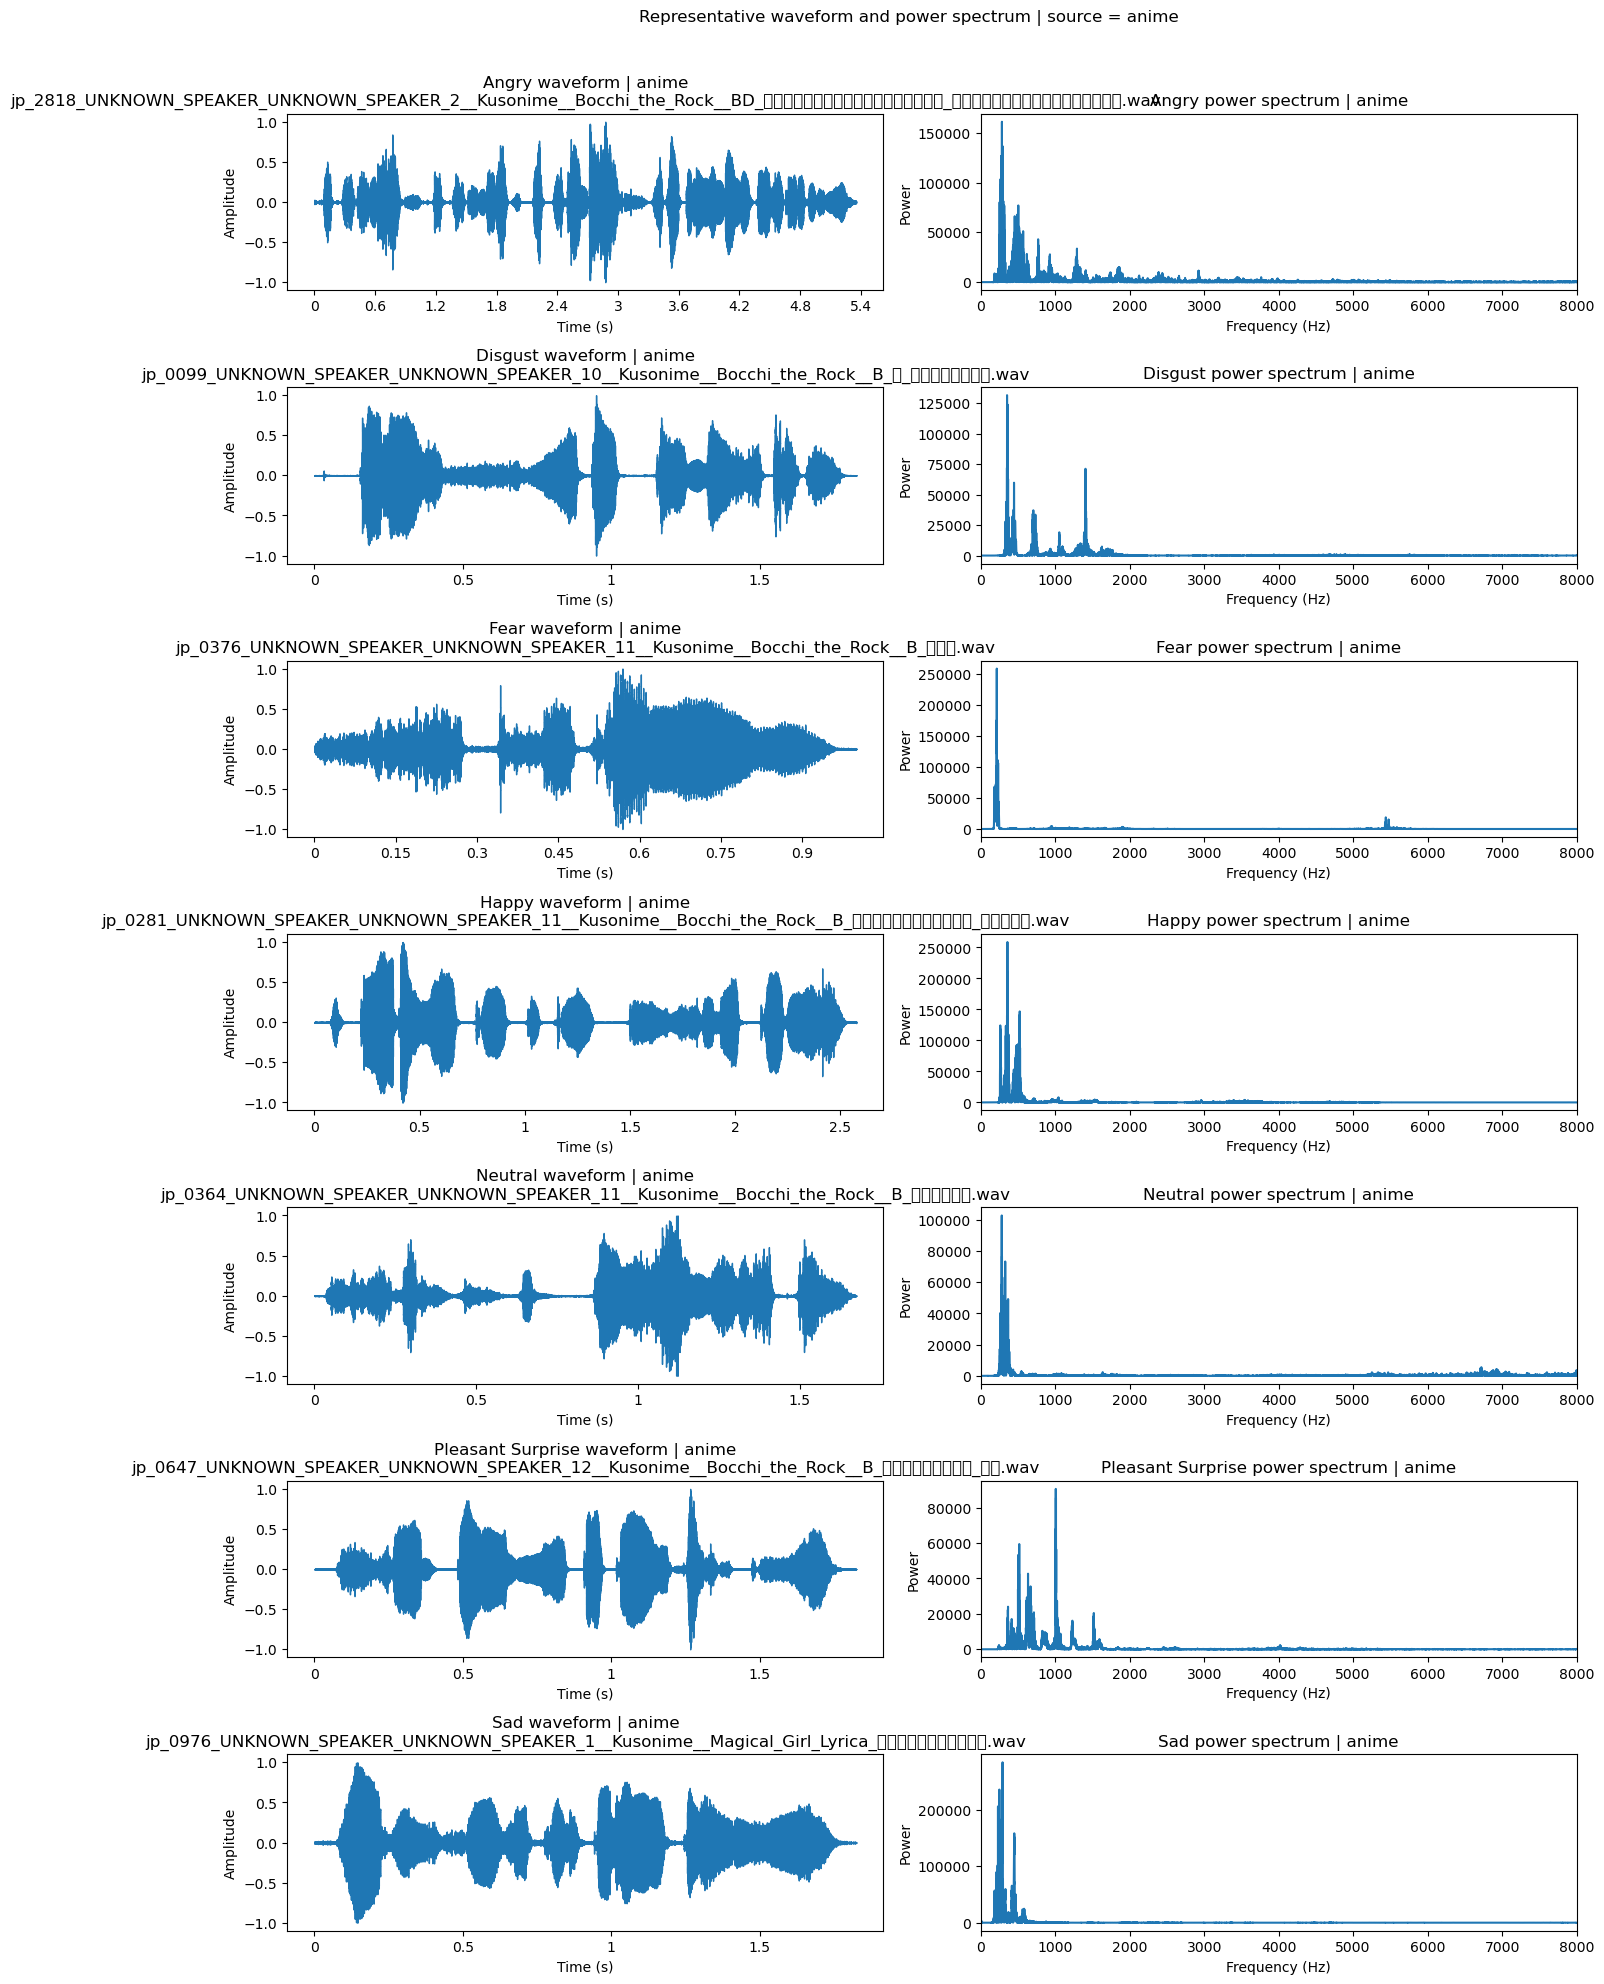

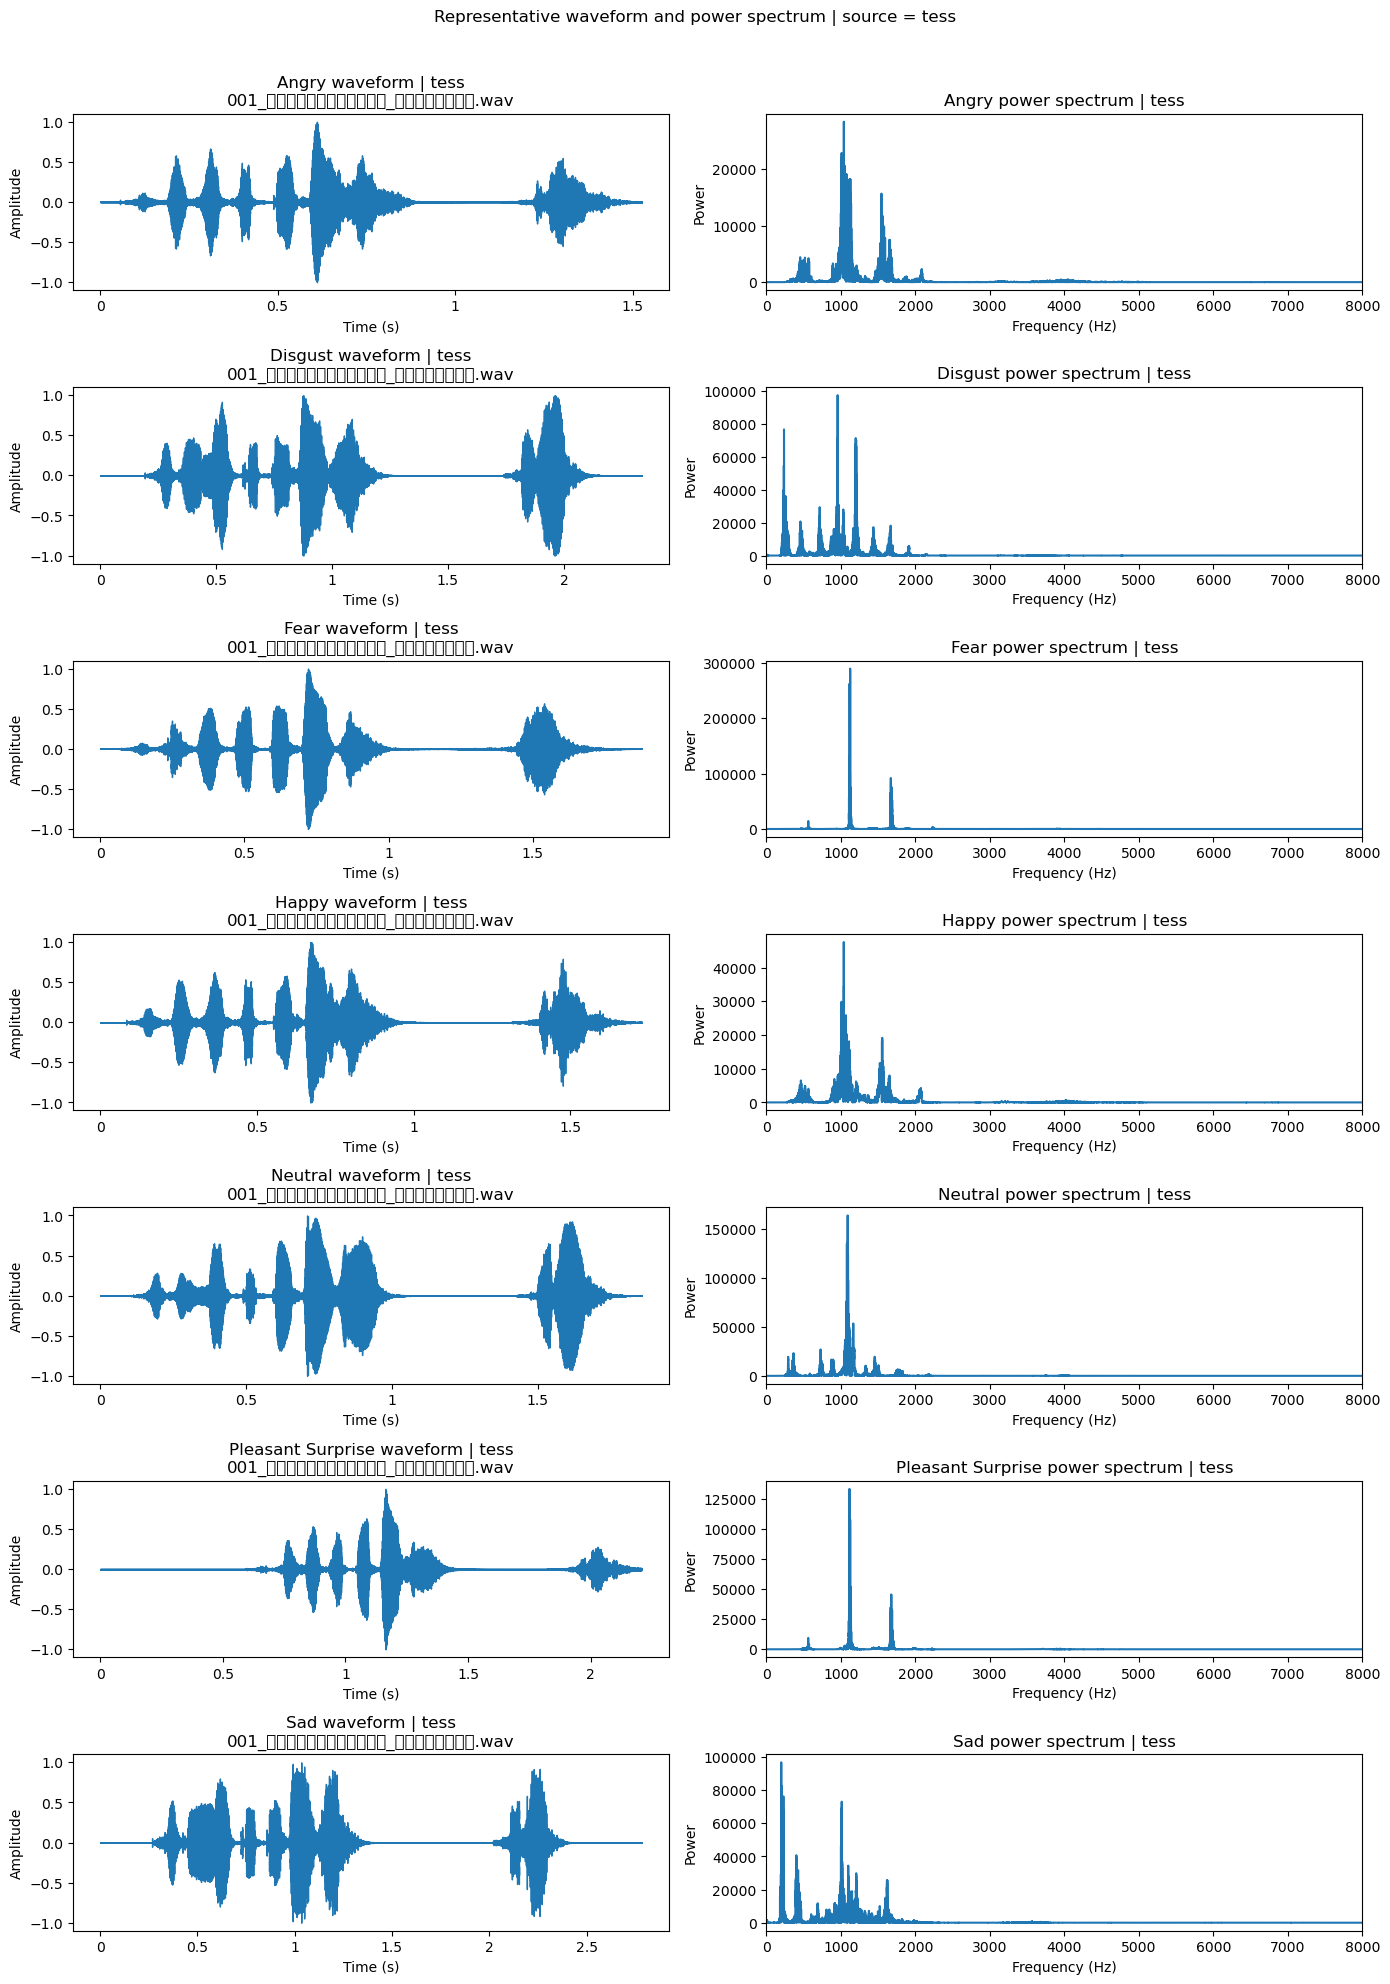

In [32]:
DISPLAY_NAMES = {
    "angry": "Angry",
    "disgust": "Disgust",
    "fear": "Fear",
    "happy": "Happy",
    "neutral": "Neutral",
    "pleasant_surprise": "Pleasant Surprise",
    "sad": "Sad",
}


def pick_representative_audio_from_meta(meta_df, emotion, source_name=None):
    if meta_df is None or len(meta_df) == 0:
        raise ValueError("Representative waveform analysis requires strict filtered metadata.")

    subset = meta_df.copy()
    if "source" in subset.columns and source_name is not None:
        subset = subset[subset["source"].astype(str).str.lower() == str(source_name).lower()].copy()

    subset = subset[subset["emotion"] == emotion].copy()
    source_label = source_name if source_name is not None else "all_sources"
    if subset.empty:
        raise ValueError(f"No filtered sample available for {source_label} | {emotion}.")

    sort_cols = [col for col in ["file_path"] if col in subset.columns]
    if sort_cols:
        subset = subset.sort_values(sort_cols)

    return Path(subset.iloc[0]["file_path"])


if "meta_filtered_df" not in globals() or meta_filtered_df.empty:
    raise ValueError("Run metadata filtering first so waveform analysis uses strict filtered data.")

visual_meta_df = meta_filtered_df.copy()
available_sources = ["all_sources"]
if "source" in visual_meta_df.columns:
    available_sources = (
        visual_meta_df["source"]
        .dropna()
        .astype(str)
        .str.lower()
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

vis_emotions = [emotion for emotion in EMOTIONS if emotion in DISPLAY_NAMES]
print("Waveform and spectrum sources:", available_sources)

for source_name in available_sources:
    fig, axes = plt.subplots(
        nrows=len(vis_emotions),
        ncols=2,
        figsize=(14, 2.8 * len(vis_emotions)),
        squeeze=False,
    )

    for row_idx, emotion in enumerate(vis_emotions):
        fp = pick_representative_audio_from_meta(visual_meta_df, emotion, source_name=source_name)
        ax_wave = axes[row_idx, 0]
        ax_freq = axes[row_idx, 1]

        y, sr = librosa.load(fp, sr=TARGET_SR, mono=True)
        y = peak_normalize(y)

        librosa.display.waveshow(y, sr=sr, ax=ax_wave)
        ax_wave.set_title(f"{DISPLAY_NAMES[emotion]} waveform | {source_name}\n{fp.name}")
        ax_wave.set_xlabel("Time (s)")
        ax_wave.set_ylabel("Amplitude")

        fft = np.fft.rfft(y)
        freqs = np.fft.rfftfreq(len(y), d=1.0 / sr)
        power = np.abs(fft) ** 2

        ax_freq.plot(freqs, power)
        ax_freq.set_title(f"{DISPLAY_NAMES[emotion]} power spectrum | {source_name}")
        ax_freq.set_xlabel("Frequency (Hz)")
        ax_freq.set_ylabel("Power")
        ax_freq.set_xlim(0, min(8000, sr // 2))

    fig.suptitle(f"Representative waveform and power spectrum | source = {source_name}", y=1.01)
    plt.tight_layout()
    plt.show()

## 15. Boxplot of MFCC values across emotion categories for all evaluated MFCC modes

This keeps the paper-style MFCC distribution view, but it now runs across every available MFCC experiment mode instead of only one fixed TESS split.

Paper-style MFCC analysis modes: anime_only, transfer_clean_to_anime


,analysis_mode,train_samples,test_samples,feature_rows,selected_features
0,anime_only,208,53,564,"mean, std, maxv, median, q1, q3"
1,transfer_clean_to_anime,2803,53,2856,"mean, std, maxv, q1"


,analysis_mode,emotion,mean,std,maxv,minv,variance,q1,median,q3,iqr
0,anime_only,disgust,-39.274475,77.401375,92.719765,-460.412811,5990.972656,-44.254005,-19.860529,1.813885,46.067890
1,anime_only,disgust,-35.218281,72.938408,79.953033,-459.021729,5320.011719,-52.072830,-19.719032,3.615833,55.688663
2,anime_only,pleasant_surprise,-41.203003,94.728638,134.970215,-607.759033,8973.514648,-56.815540,-16.296566,4.633326,61.448868
3,anime_only,happy,-39.456738,98.999573,120.541794,-547.293945,9800.916016,-41.704834,-13.106847,3.315279,45.020111
4,anime_only,angry,-39.492714,84.309593,122.450943,-481.183685,7108.106934,-46.584202,-17.731661,2.286497,48.870697


mean              std              maxv           \
                            mean     std     mean     std      mean      std   
analysis_mode                                                                  
anime_only              -36.5507  3.0883  78.8988  6.2700  116.2852  17.9893   
transfer_clean_to_anime -35.8064  1.2119  94.6214  6.9017   99.5762  31.3013   

                             minv            variance                  q1  \
                             mean      std       mean        std     mean   
analysis_mode                                                               
anime_only              -459.1271  49.1925  6264.2613   990.4447 -49.3196   
transfer_clean_to_anime -557.9046  33.4320  9000.8350  1314.4730 -36.4942   

                                  median              q3              iqr  \
                            std     mean     std    mean     std     mean   
analysis_mode                                                               
anime_only               4.4296 -18.8054  2.8575  2.1247  3.4426  51.4442   
transfer_clean_to_anime  4.9546  -8.4137  4.6035  5.1706  4.8799  41.6648   

                                 
                            std  
analysis_mode                    
anime_only               5.4950  
transfer_clean_to_anime  5.6318

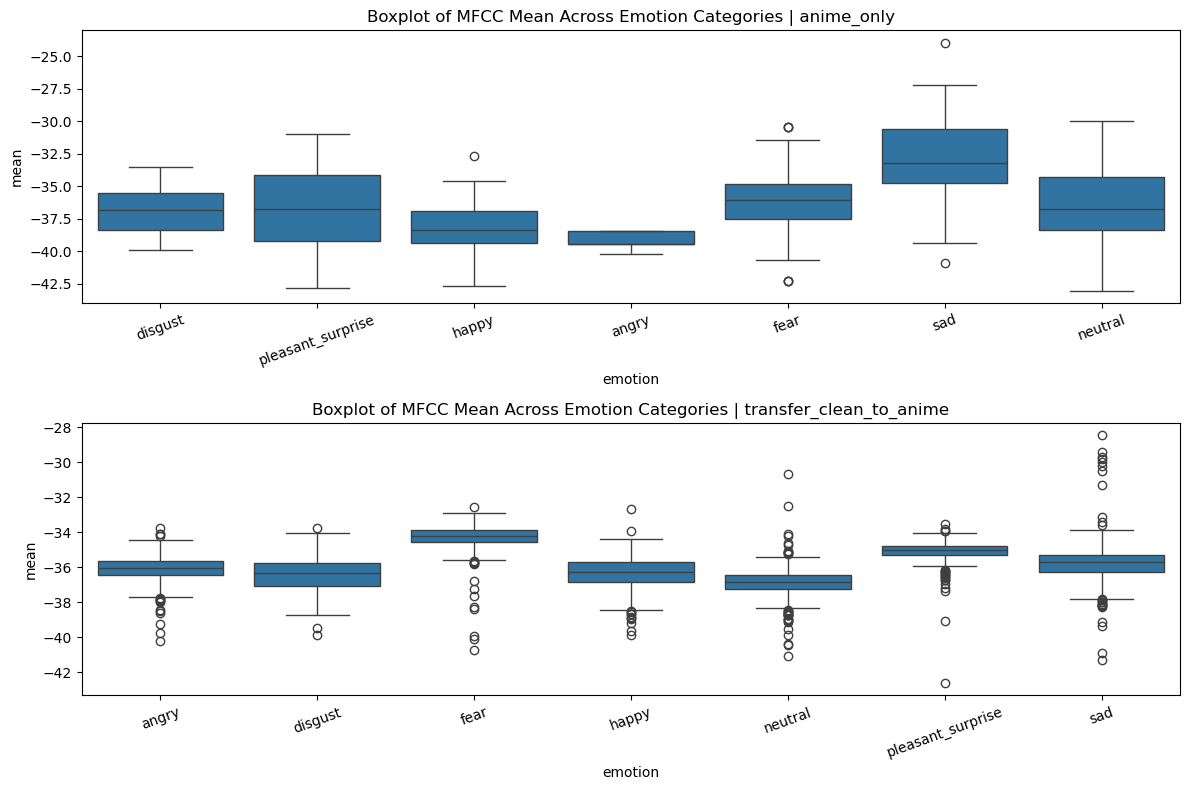

In [33]:
def get_default_analysis_meta_df():
    if "meta_filtered_df" in globals() and len(meta_filtered_df):
        return meta_filtered_df.copy()
    raise ValueError("Run metadata filtering first so the paper analysis uses strict filtered data only.")


def get_available_mfcc_analysis_modes(meta_df=None):
    if meta_df is None:
        meta_df = get_default_analysis_meta_df()

    candidate_modes = []
    if "experiment_results_df" in globals() and len(experiment_results_df):
        candidate_modes = (
            experiment_results_df.loc[experiment_results_df["branch"] == "mfcc_ml", "mode"]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .tolist()
        )

    if not candidate_modes:
        candidate_modes = ["anime_only", "transfer_clean_to_anime"]

    valid_modes = []
    for mode in candidate_modes:
        try:
            train_meta, test_meta = build_split_for_mode(mode, meta_df)
            if len(train_meta) and len(test_meta):
                valid_modes.append(mode)
        except Exception:
            continue

    if not valid_modes:
        raise ValueError("No MFCC analysis modes are available with the current filtered metadata.")

    return valid_modes


def prepare_mfcc_paper_analysis(mode="anime_only", meta_df=None):
    if meta_df is None:
        meta_df = get_default_analysis_meta_df()

    train_meta, test_meta = build_split_for_mode(mode, meta_df)
    train_feat = build_mfcc_feature_df(train_meta)
    test_feat = build_mfcc_feature_df(test_meta)

    if mode in {"anime_only", "combined"}:
        train_feat = oversample_train_df(train_feat, label_col="emotion")

    keep_cols, corr = select_features_by_correlation(train_feat, PAPER_FEATURES_9, CORR_THRESHOLD)
    selected_cols = [col for col in PAPER_SELECTED_6 if col in keep_cols]
    if not selected_cols:
        selected_cols = PAPER_SELECTED_6.copy()

    return {
        "mode": mode,
        "train_meta": train_meta,
        "test_meta": test_meta,
        "train_feat": train_feat,
        "test_feat": test_feat,
        "feature_df": pd.concat([train_feat, test_feat], ignore_index=True),
        "corr_matrix": corr,
        "keep_cols": keep_cols,
        "drop_cols": [col for col in PAPER_FEATURES_9 if col not in keep_cols],
        "selected_cols": selected_cols,
    }


MFCC_ANALYSIS_MODES = get_available_mfcc_analysis_modes()
paper_mfcc_bundles = {
    mode: prepare_mfcc_paper_analysis(mode)
    for mode in MFCC_ANALYSIS_MODES
}
paper_mfcc_bundle = paper_mfcc_bundles[MFCC_ANALYSIS_MODES[0]]
paper_feature_df = pd.concat(
    [
        bundle["feature_df"].assign(analysis_mode=mode)
        for mode, bundle in paper_mfcc_bundles.items()
    ],
    ignore_index=True,
)

paper_mfcc_summary_df = pd.DataFrame(
    [
        {
            "analysis_mode": mode,
            "train_samples": len(bundle["train_meta"]),
            "test_samples": len(bundle["test_meta"]),
            "feature_rows": len(bundle["feature_df"]),
            "selected_features": ", ".join(bundle["selected_cols"]),
        }
        for mode, bundle in paper_mfcc_bundles.items()
    ]
).sort_values("analysis_mode").reset_index(drop=True)

print("Paper-style MFCC analysis modes:", ", ".join(MFCC_ANALYSIS_MODES))
display(paper_mfcc_summary_df)
display(paper_feature_df[["analysis_mode", "emotion"] + PAPER_FEATURES_9].head())
display(
    paper_feature_df.groupby("analysis_mode")[PAPER_FEATURES_9].agg(["mean", "std"]).round(4)
)

fig, axes = plt.subplots(
    nrows=len(MFCC_ANALYSIS_MODES),
    ncols=1,
    figsize=(12, 4 * len(MFCC_ANALYSIS_MODES)),
    squeeze=False,
)

for row_idx, mode in enumerate(MFCC_ANALYSIS_MODES):
    ax = axes[row_idx, 0]
    sns.boxplot(data=paper_mfcc_bundles[mode]["feature_df"], x="emotion", y="mean", ax=ax)
    ax.tick_params(axis="x", rotation=20)
    ax.set_title(f"Boxplot of MFCC Mean Across Emotion Categories | {mode}")

plt.tight_layout()
plt.show()

## 16. Correlation-based MFCC analysis for all evaluated MFCC modes

This reproduces the paper-style correlation filtering summary for every available MFCC mode, not just one fixed split.

Correlation-based feature filtering across MFCC modes


,analysis_mode,correlation_threshold,auto_selected_features,auto_dropped_features,final_features_used
0,anime_only,0.7,"mean, std, maxv, q1, median, q3","minv, variance, iqr","mean, std, maxv, median, q1, q3"
1,transfer_clean_to_anime,0.7,"mean, std, maxv, q1, iqr","minv, variance, median, q3","mean, std, maxv, q1"


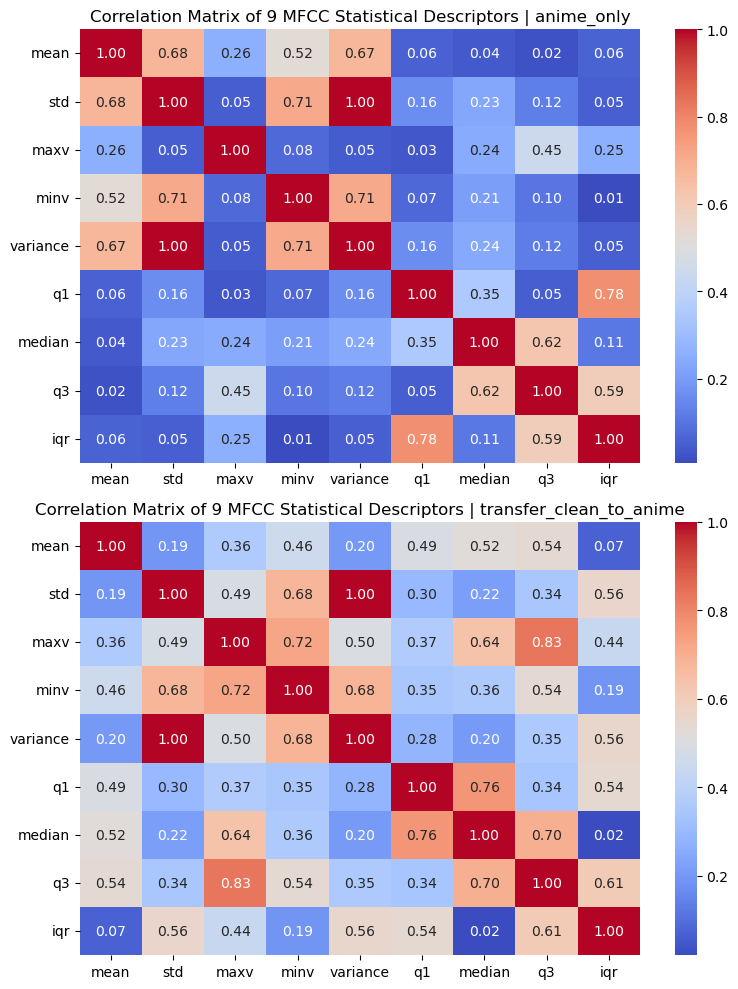

In [34]:
if "paper_mfcc_bundles" not in globals():
    MFCC_ANALYSIS_MODES = get_available_mfcc_analysis_modes()
    paper_mfcc_bundles = {
        mode: prepare_mfcc_paper_analysis(mode)
        for mode in MFCC_ANALYSIS_MODES
    }

corr_summary_rows = []
for mode in MFCC_ANALYSIS_MODES:
    bundle = paper_mfcc_bundles[mode]
    corr_summary_rows.append({
        "analysis_mode": mode,
        "correlation_threshold": CORR_THRESHOLD,
        "auto_selected_features": ", ".join(bundle["keep_cols"]),
        "auto_dropped_features": ", ".join(bundle["drop_cols"]) if bundle["drop_cols"] else "-",
        "final_features_used": ", ".join(bundle["selected_cols"]),
    })

print("Correlation-based feature filtering across MFCC modes")
display(pd.DataFrame(corr_summary_rows))

fig, axes = plt.subplots(
    nrows=len(MFCC_ANALYSIS_MODES),
    ncols=1,
    figsize=(8, 5 * len(MFCC_ANALYSIS_MODES)),
    squeeze=False,
)

for row_idx, mode in enumerate(MFCC_ANALYSIS_MODES):
    corr_matrix = paper_mfcc_bundles[mode]["corr_matrix"]
    ax = axes[row_idx, 0]
    sns.heatmap(
        corr_matrix.loc[PAPER_FEATURES_9, PAPER_FEATURES_9],
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        ax=ax,
    )
    ax.set_title(f"Correlation Matrix of 9 MFCC Statistical Descriptors | {mode}")

plt.tight_layout()
plt.show()

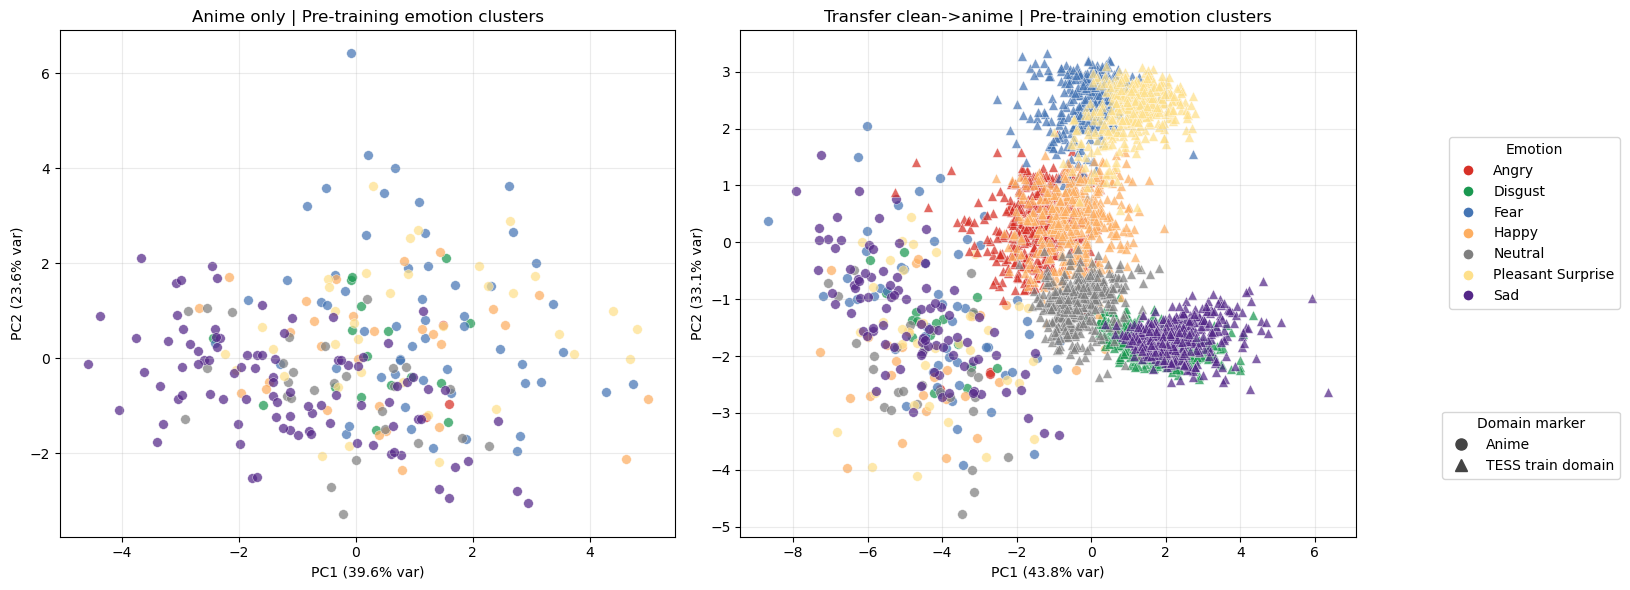

Pre-training cluster diagnostics:


,Mode,Samples,Sources,Emotion silhouette,Domain silhouette,PC1 variance,PC2 variance
0,Anime only,261,Anime,-0.1128,NaN,0.3958,0.2356
1,Transfer clean->anime,3064,"Anime, TESS train domain",0.1305,0.4568,0.4383,0.3309


Interpretation: low emotion silhouette means the 7 classes overlap strongly before training. A high domain silhouette in transfer_clean_to_anime means TESS and anime are separated by source/domain, which usually lowers transfer accuracy.


In [35]:
# Pre-training cluster view to inspect emotion overlap before fitting any model.
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D

PRETRAIN_CLUSTER_FEATURES = PAPER_FEATURES_9.copy()

EMOTION_CLUSTER_COLORS = {
    "angry": "#d73027",
    "disgust": "#1a9850",
    "fear": "#4575b4",
    "happy": "#fdae61",
    "neutral": "#7f7f7f",
    "pleasant_surprise": "#fee08b",
    "sad": "#542788",
}

DOMAIN_MARKERS = {
    "Anime": "o",
    "TESS train domain": "^",
}


def build_pretraining_cluster_meta(mode, meta_df=None):
    if meta_df is None:
        meta_df = get_default_analysis_meta_df()

    if mode == "anime_only":
        anime_df, _, _ = balance_source_dataset(meta_df, "anime")
        cluster_meta = anime_df.copy()
        cluster_meta["domain_label"] = "Anime"
    elif mode == "transfer_clean_to_anime":
        tess_df, _, _ = balance_source_dataset(meta_df, "tess")
        anime_df, _, _ = balance_source_dataset(meta_df, "anime")
        cluster_meta = pd.concat(
            [
                tess_df.copy().assign(domain_label="TESS train domain"),
                anime_df.copy().assign(domain_label="Anime"),
            ],
            ignore_index=True,
        )
    else:
        raise ValueError(f"Unsupported mode for pre-training cluster view: {mode}")

    cluster_meta = cluster_meta[cluster_meta["emotion"].isin(EMOTIONS)].copy()
    cluster_meta["mode_label"] = MODE_DISPLAY_NAMES.get(mode, mode)
    return cluster_meta.sort_values(["domain_label", "emotion", "file_path"]).reset_index(drop=True)


def build_pretraining_cluster_feature_df(mode, meta_df=None):
    cache_key = f"pretrain_cluster::{mode}"
    if meta_df is None and "pretraining_cluster_cache" in globals() and cache_key in pretraining_cluster_cache:
        return pretraining_cluster_cache[cache_key].copy()

    cluster_meta = build_pretraining_cluster_meta(mode, meta_df=meta_df)
    feature_df = build_mfcc_feature_df(cluster_meta)
    feature_df["emotion_label"] = feature_df["emotion"].map(DISPLAY_NAMES).fillna(feature_df["emotion"])

    if meta_df is None:
        if "pretraining_cluster_cache" not in globals():
            pretraining_cluster_cache = {}
        pretraining_cluster_cache[cache_key] = feature_df.copy()

    return feature_df


def safe_silhouette_score(X, labels):
    label_series = pd.Series(labels).astype(str)
    if len(label_series) < 3 or label_series.nunique() < 2:
        return np.nan
    min_count = label_series.value_counts().min()
    if min_count < 2:
        return np.nan
    return float(silhouette_score(X, label_series))


CLUSTER_DIAG_MODES = ["anime_only", "transfer_clean_to_anime"]
available_cluster_modes = [mode for mode in CLUSTER_DIAG_MODES if mode in ["anime_only", "transfer_clean_to_anime"]]

fig, axes = plt.subplots(1, len(available_cluster_modes), figsize=(8 * len(available_cluster_modes), 6), squeeze=False)
summary_rows = []

for plot_idx, mode in enumerate(available_cluster_modes):
    ax = axes[0, plot_idx]
    feature_df = build_pretraining_cluster_feature_df(mode)
    X = feature_df[PRETRAIN_CLUSTER_FEATURES].fillna(0.0).to_numpy()
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2)
    coords = pca.fit_transform(X_scaled)

    plot_df = feature_df.copy()
    plot_df["cluster_x"] = coords[:, 0]
    plot_df["cluster_y"] = coords[:, 1]

    domain_order = [domain for domain in DOMAIN_MARKERS if domain in plot_df["domain_label"].unique()]
    for domain_label in domain_order:
        domain_df = plot_df[plot_df["domain_label"] == domain_label]
        for emotion in EMOTIONS:
            subset = domain_df[domain_df["emotion"] == emotion]
            if subset.empty:
                continue
            ax.scatter(
                subset["cluster_x"],
                subset["cluster_y"],
                s=48,
                alpha=0.72,
                c=EMOTION_CLUSTER_COLORS[emotion],
                marker=DOMAIN_MARKERS[domain_label],
                edgecolors="white",
                linewidths=0.35,
            )

    mode_title = MODE_DISPLAY_NAMES.get(mode, mode)
    ax.set_title(f"{mode_title} | Pre-training emotion clusters")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% var)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% var)")
    ax.grid(True, alpha=0.25)

    summary_rows.append({
        "Mode": mode_title,
        "Samples": len(plot_df),
        "Sources": ", ".join(sorted(plot_df["domain_label"].unique())),
        "Emotion silhouette": safe_silhouette_score(X_scaled, plot_df["emotion"]),
        "Domain silhouette": safe_silhouette_score(X_scaled, plot_df["domain_label"]),
        "PC1 variance": pca.explained_variance_ratio_[0],
        "PC2 variance": pca.explained_variance_ratio_[1],
    })

emotion_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=DISPLAY_NAMES.get(emotion, emotion),
        markerfacecolor=EMOTION_CLUSTER_COLORS[emotion],
        markeredgecolor="white",
        markersize=8,
    )
    for emotion in EMOTIONS
]

domain_handles = [
    Line2D(
        [0],
        [0],
        marker=DOMAIN_MARKERS[domain_label],
        color="#444444",
        label=domain_label,
        linestyle="None",
        markersize=8,
    )
    for domain_label in DOMAIN_MARKERS
]

fig.legend(emotion_handles, [h.get_label() for h in emotion_handles], title="Emotion", loc="center right", bbox_to_anchor=(1.02, 0.62))
fig.legend(domain_handles, [h.get_label() for h in domain_handles], title="Domain marker", loc="center right", bbox_to_anchor=(1.02, 0.25))
plt.tight_layout(rect=(0, 0, 0.86, 1))
plt.show()

cluster_summary_df = pd.DataFrame(summary_rows)
print("Pre-training cluster diagnostics:")
display(cluster_summary_df.round(4))

print(
    "Interpretation: low emotion silhouette means the 7 classes overlap strongly before training. "
    "A high domain silhouette in transfer_clean_to_anime means TESS and anime are separated by source/domain, "
    "which usually lowers transfer accuracy."
)


## 17. Hyperparameter tuning for MFCC classifiers across all evaluated MFCC modes

This section runs a real untuned-vs-tuned MFCC experiment with `GridSearchCV` for every available MFCC mode. It still does not overwrite `MFCC_BASELINE_MODELS` automatically, so the main experiment table stays stable unless you manually copy the tuned parameters back into the MFCC runner.

MFCC tuning modes: anime_only, transfer_clean_to_anime
Baseline before tuning


,mode,model_name,stage,accuracy,macro_precision,macro_recall,macro_f1
0,anime_only,DT,before_tuning,0.433962,0.370683,0.373368,0.362369
1,anime_only,k-NN,before_tuning,0.433962,0.340198,0.353058,0.333234
2,anime_only,RF,before_tuning,0.452830,0.316790,0.300784,0.302885
3,anime_only,SVM,before_tuning,0.452830,0.303316,0.304300,0.299297
4,anime_only,NB,before_tuning,0.377358,0.261706,0.276161,0.257584
5,transfer_clean_to_anime,SVM,before_tuning,0.207547,0.189683,0.266917,0.154610
6,transfer_clean_to_anime,DT,before_tuning,0.075472,0.075092,0.214286,0.078571
7,transfer_clean_to_anime,RF,before_tuning,0.056604,0.039286,0.190476,0.047785
8,transfer_clean_to_anime,k-NN,before_tuning,0.018868,0.002915,0.142857,0.005714
9,transfer_clean_to_anime,NB,before_tuning,0.000000,0.000000,0.000000,0.000000


Tuning mode: anime_only
Tuning anime_only | SVM...
Fitting 5 folds for each of 400 candidates, totalling 2000 fits
Tuning anime_only | k-NN...
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Tuning anime_only | DT...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Tuning anime_only | RF...
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Tuning anime_only | NB...
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Tuning mode: transfer_clean_to_anime
Tuning transfer_clean_to_anime | SVM...
Fitting 5 folds for each of 400 candidates, totalling 2000 fits
Tuning transfer_clean_to_anime | k-NN...
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Tuning transfer_clean_to_anime | DT...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Tuning transfer_clean_to_anime | RF...
Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Tuning transfer_clean_to_anime | NB...
Fitting 5 folds for each of 100 candi

,mode,model_name,best_score_cv_macro_f1,best_params,best_params_clean
0,anime_only,RF,0.913271,"{'bootstrap': False, 'max_depth': None, 'max_f...","{'bootstrap': False, 'max_depth': None, 'max_f..."
1,anime_only,SVM,0.910058,"{'clf__C': 4.281332398719396, 'clf__gamma': 1....","{'C': 4.281332398719396, 'gamma': 1.6237767391..."
2,anime_only,DT,0.908836,"{'criterion': 'entropy', 'max_depth': None, 'm...","{'criterion': 'entropy', 'max_depth': None, 'm..."
3,anime_only,k-NN,0.895426,"{'clf__metric': 'minkowski', 'clf__n_neighbors...","{'metric': 'minkowski', 'n_neighbors': 3, 'p':..."
4,anime_only,NB,0.565380,{'var_smoothing': 0.0005336699231206312},{'var_smoothing': 0.0005336699231206312}
5,transfer_clean_to_anime,SVM,0.871296,"{'clf__C': 1438.44988828766, 'clf__gamma': 0.0...","{'C': 1438.44988828766, 'gamma': 0.01274274985..."
6,transfer_clean_to_anime,k-NN,0.865442,"{'clf__metric': 'minkowski', 'clf__n_neighbors...","{'metric': 'minkowski', 'n_neighbors': 15, 'p'..."
7,transfer_clean_to_anime,RF,0.854616,"{'bootstrap': True, 'max_depth': 20, 'max_feat...","{'bootstrap': True, 'max_depth': 20, 'max_feat..."
8,transfer_clean_to_anime,DT,0.813533,"{'criterion': 'entropy', 'max_depth': 10, 'max...","{'criterion': 'entropy', 'max_depth': 10, 'max..."
9,transfer_clean_to_anime,NB,0.812212,{'var_smoothing': 8.111308307896873e-06},{'var_smoothing': 8.111308307896873e-06}


Evaluation after tuning


,mode,model_name,stage,accuracy,macro_precision,macro_recall,macro_f1
0,anime_only,DT,after_tuning,0.377358,0.319949,0.370504,0.331138
1,anime_only,RF,after_tuning,0.452830,0.306803,0.300784,0.299940
2,anime_only,k-NN,after_tuning,0.396226,0.273076,0.286984,0.275227
3,anime_only,NB,after_tuning,0.396226,0.265266,0.283680,0.263934
4,anime_only,SVM,after_tuning,0.415094,0.360566,0.260082,0.262949
5,transfer_clean_to_anime,SVM,after_tuning,0.094340,0.029351,0.238095,0.049289
6,transfer_clean_to_anime,RF,after_tuning,0.056604,0.039116,0.190476,0.047461
7,transfer_clean_to_anime,DT,after_tuning,0.018868,0.003401,0.142857,0.006645
8,transfer_clean_to_anime,k-NN,after_tuning,0.018868,0.003106,0.142857,0.006079
9,transfer_clean_to_anime,NB,after_tuning,0.000000,0.000000,0.000000,0.000000


Before vs after tuning


,mode,model_name,accuracy_before,accuracy_after,macro_f1_before,macro_f1_after,delta_accuracy,delta_macro_f1
0,anime_only,RF,0.452830,0.452830,0.302885,0.299940,0.000000,-0.002945
1,anime_only,SVM,0.452830,0.415094,0.299297,0.262949,-0.037736,-0.036348
2,anime_only,k-NN,0.433962,0.396226,0.333234,0.275227,-0.037736,-0.058007
3,anime_only,NB,0.377358,0.396226,0.257584,0.263934,0.018868,0.006349
4,anime_only,DT,0.433962,0.377358,0.362369,0.331138,-0.056604,-0.031231
5,transfer_clean_to_anime,SVM,0.207547,0.094340,0.154610,0.049289,-0.113208,-0.105321
6,transfer_clean_to_anime,RF,0.056604,0.056604,0.047785,0.047461,0.000000,-0.000324
7,transfer_clean_to_anime,DT,0.075472,0.018868,0.078571,0.006645,-0.056604,-0.071927
8,transfer_clean_to_anime,k-NN,0.018868,0.018868,0.005714,0.006079,0.000000,0.000365
9,transfer_clean_to_anime,NB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


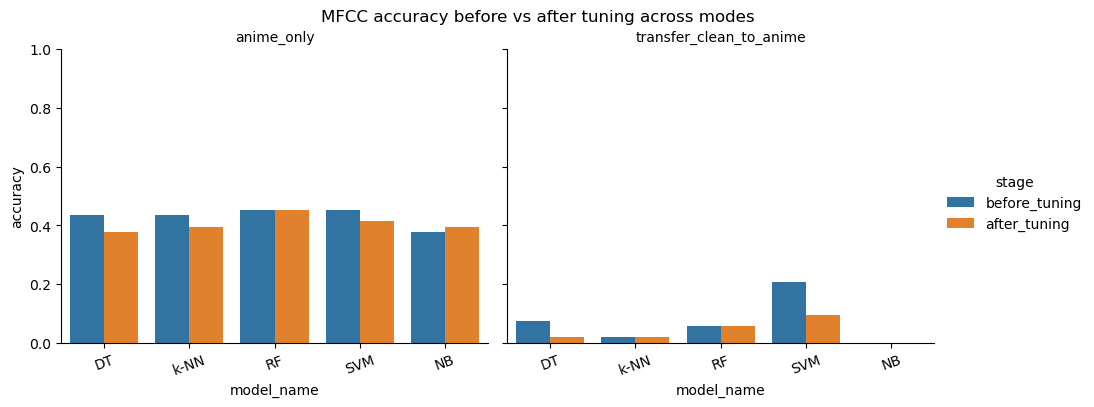

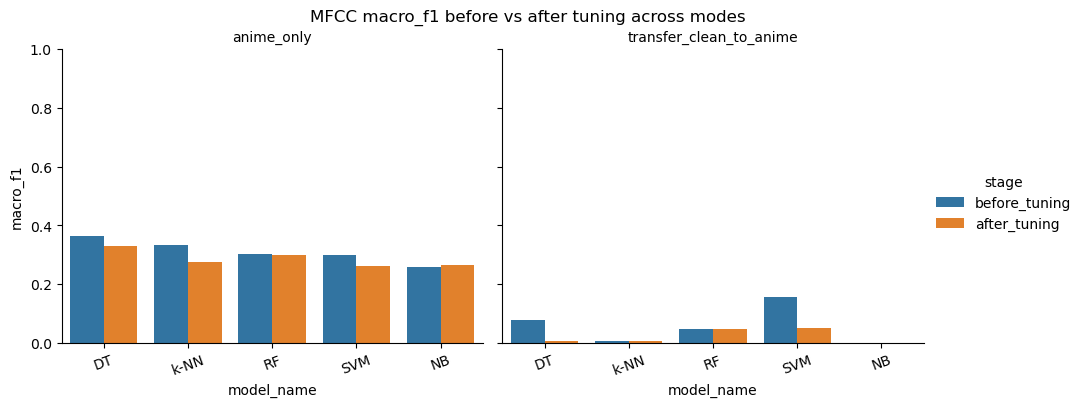

In [36]:
MFCC_MODEL_ORDER = ["SVM", "k-NN", "DT", "RF", "NB"]

MFCC_SEARCH_SPACE_TEXT = {
    "SVM": {
        "C": "np.logspace(-4, 4, 20)",
        "gamma": "np.logspace(-4, 4, 20)",
        "kernel": "['rbf']",
    },
    "k-NN": {
        "n_neighbors": "[3, 5, 7, 10, 15]",
        "weights": "['uniform', 'distance']",
        "metric": "['minkowski', 'euclidean', 'manhattan']",
        "p": "[1, 2]",
    },
    "DT": {
        "criterion": "['gini', 'entropy']",
        "max_depth": "[None, 10, 20, 30]",
        "min_samples_split": "[2, 5, 10]",
        "min_samples_leaf": "[1, 2, 4]",
        "max_features": "[None, 'sqrt', 'log2']",
    },
    "RF": {
        "n_estimators": "[50, 100, 200]",
        "max_depth": "[None, 10, 20, 30]",
        "min_samples_split": "[2, 5, 10]",
        "min_samples_leaf": "[1, 2, 4]",
        "max_features": "['sqrt', 'log2', None]",
        "bootstrap": "[True, False]",
    },
    "NB": {
        "var_smoothing": "np.logspace(-9, 0, 100)",
    },
}

MFCC_PARAM_GRIDS = {
    "SVM": {
        "clf__C": np.logspace(-4, 4, 20),
        "clf__gamma": np.logspace(-4, 4, 20),
        "clf__kernel": ["rbf"],
    },
    "k-NN": {
        "clf__n_neighbors": [3, 5, 7, 10, 15],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["minkowski", "euclidean", "manhattan"],
        "clf__p": [1, 2],
    },
    "DT": {
        "criterion": ["gini", "entropy"],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": [None, "sqrt", "log2"],
    },
    "RF": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2", None],
        "bootstrap": [True, False],
    },
    "NB": {
        "var_smoothing": np.logspace(-9, 0, 100),
    },
}


def build_mfcc_search_models():
    return {
        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(class_weight="balanced")),
        ]),
        "k-NN": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier()),
        ]),
        "DT": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "RF": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "NB": GaussianNB(),
    }


RUN_MFCC_TUNING = True
TUNING_MODES = list(MFCC_ANALYSIS_MODES)
TUNING_CV_SPLITS = 5
TUNING_SCORING = "f1_macro"

mfcc_baseline_rows = []
mfcc_baseline_predictions = {}
mfcc_tuned_models = {}
mfcc_tuned_predictions = {}
mfcc_best_params_lookup = {}
mfcc_selected_params_source = "current_notebook_parameters"

for tuning_mode in TUNING_MODES:
    paper_bundle = paper_mfcc_bundles[tuning_mode]
    X_train = paper_bundle["train_feat"][paper_bundle["selected_cols"]].copy()
    y_train = paper_bundle["train_feat"]["label_id"].to_numpy(dtype=int)
    X_test = paper_bundle["test_feat"][paper_bundle["selected_cols"]].copy()
    y_test = paper_bundle["test_feat"]["label_id"].to_numpy(dtype=int)

    search_models = build_mfcc_search_models()
    for model_name in MFCC_MODEL_ORDER:
        baseline_model = search_models[model_name]
        baseline_model.fit(X_train, y_train)
        y_pred = baseline_model.predict(X_test)
        mfcc_baseline_predictions[(tuning_mode, model_name)] = y_pred
        mfcc_baseline_rows.append({
            "mode": tuning_mode,
            "model_name": model_name,
            "stage": "before_tuning",
            **evaluate_predictions(y_test, y_pred),
        })

mfcc_baseline_before_tuning_df = pd.DataFrame(mfcc_baseline_rows).sort_values(
    ["mode", "macro_f1", "accuracy"], ascending=[True, False, False]
).reset_index(drop=True)

print("MFCC tuning modes:", ", ".join(TUNING_MODES))
print("Baseline before tuning")
display(mfcc_baseline_before_tuning_df)

mfcc_tuning_summary_df = pd.DataFrame()
mfcc_tuned_results_df = pd.DataFrame()
mfcc_tuning_comparison_df = pd.DataFrame()

if RUN_MFCC_TUNING:
    cv = StratifiedKFold(n_splits=TUNING_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    tuning_summary = []
    tuned_eval_rows = []

    for tuning_mode in TUNING_MODES:
        print(f"Tuning mode: {tuning_mode}")
        paper_bundle = paper_mfcc_bundles[tuning_mode]
        X_train = paper_bundle["train_feat"][paper_bundle["selected_cols"]].copy()
        y_train = paper_bundle["train_feat"]["label_id"].to_numpy(dtype=int)
        X_test = paper_bundle["test_feat"][paper_bundle["selected_cols"]].copy()
        y_test = paper_bundle["test_feat"]["label_id"].to_numpy(dtype=int)
        search_models = build_mfcc_search_models()

        for model_name in MFCC_MODEL_ORDER:
            print(f"Tuning {tuning_mode} | {model_name}...")
            grid = GridSearchCV(
                estimator=search_models[model_name],
                param_grid=MFCC_PARAM_GRIDS[model_name],
                scoring=TUNING_SCORING,
                cv=cv,
                n_jobs=SAFE_PARALLEL_JOBS,
                verbose=1,
            )
            grid.fit(X_train, y_train)

            best_params_clean = {
                str(k).replace("clf__", ""): v for k, v in grid.best_params_.items()
            }
            mfcc_best_params_lookup[(tuning_mode, model_name)] = best_params_clean
            mfcc_tuned_models[(tuning_mode, model_name)] = grid.best_estimator_
            tuning_summary.append({
                "mode": tuning_mode,
                "model_name": model_name,
                "best_score_cv_macro_f1": float(grid.best_score_),
                "best_params": grid.best_params_,
                "best_params_clean": best_params_clean,
            })

            y_pred = grid.best_estimator_.predict(X_test)
            mfcc_tuned_predictions[(tuning_mode, model_name)] = y_pred
            tuned_eval_rows.append({
                "mode": tuning_mode,
                "model_name": model_name,
                "stage": "after_tuning",
                **evaluate_predictions(y_test, y_pred),
            })

    mfcc_tuning_summary_df = pd.DataFrame(tuning_summary).sort_values(
        ["mode", "best_score_cv_macro_f1", "model_name"], ascending=[True, False, True]
    ).reset_index(drop=True)
    mfcc_tuned_results_df = pd.DataFrame(tuned_eval_rows).sort_values(
        ["mode", "macro_f1", "accuracy"], ascending=[True, False, False]
    ).reset_index(drop=True)
    mfcc_selected_params_source = "grid_search_best_params"

    mfcc_tuning_comparison_df = mfcc_baseline_before_tuning_df.merge(
        mfcc_tuned_results_df,
        on=["mode", "model_name"],
        suffixes=("_before", "_after"),
    )
    mfcc_tuning_comparison_df["delta_accuracy"] = (
        mfcc_tuning_comparison_df["accuracy_after"] - mfcc_tuning_comparison_df["accuracy_before"]
    )
    mfcc_tuning_comparison_df["delta_macro_f1"] = (
        mfcc_tuning_comparison_df["macro_f1_after"] - mfcc_tuning_comparison_df["macro_f1_before"]
    )
    mfcc_tuning_comparison_df = mfcc_tuning_comparison_df[[
        "mode",
        "model_name",
        "accuracy_before",
        "accuracy_after",
        "macro_f1_before",
        "macro_f1_after",
        "delta_accuracy",
        "delta_macro_f1",
    ]].sort_values(["mode", "accuracy_after", "macro_f1_after"], ascending=[True, False, False]).reset_index(drop=True)

    print("GridSearchCV summary")
    display(mfcc_tuning_summary_df)
    print("Evaluation after tuning")
    display(mfcc_tuned_results_df)
    print("Before vs after tuning")
    display(mfcc_tuning_comparison_df)

    mfcc_tuning_plot_df = pd.concat(
        [mfcc_baseline_before_tuning_df, mfcc_tuned_results_df],
        ignore_index=True,
    )

    for metric in ["accuracy", "macro_f1"]:
        g = sns.catplot(
            data=mfcc_tuning_plot_df,
            kind="bar",
            x="model_name",
            y=metric,
            hue="stage",
            col="mode",
            col_wrap=2,
            sharey=True,
            height=4,
            aspect=1.2,
        )
        g.set_titles("{col_name}")
        for ax in g.axes.flatten():
            ax.set_ylim(0, 1)
            ax.tick_params(axis="x", rotation=20)
        g.fig.subplots_adjust(top=0.88)
        g.fig.suptitle(f"MFCC {metric} before vs after tuning across modes")
        plt.show()
else:
    print("Set RUN_MFCC_TUNING = True to execute GridSearchCV after the untuned baseline has been shown.")


## 18. Hyperparameter Search Space and Selected Parameters for every tuned MFCC mode

This table requires the real `GridSearchCV` `best_params_` produced by Section 17 and now reports the selected parameters for every tuned MFCC mode.

In [37]:
def parse_best_params(value):
    if isinstance(value, dict):
        return {str(k).replace("clf__", ""): v for k, v in value.items()}
    return None


if not (("mfcc_best_params_lookup" in globals() and len(mfcc_best_params_lookup)) or ("mfcc_tuning_summary_df" in globals() and len(mfcc_tuning_summary_df))):
    raise ValueError("Run Section 17 first so this table uses real GridSearchCV best_params_.")

selected_params_lookup = {}
selected_params_source_label = "GridSearchCV best_params_ from Section 17"

if "mfcc_best_params_lookup" in globals() and len(mfcc_best_params_lookup):
    for key, best_params in mfcc_best_params_lookup.items():
        if best_params:
            selected_params_lookup[key] = best_params
else:
    for _, row in mfcc_tuning_summary_df.iterrows():
        parsed = row.get("best_params_clean")
        if not isinstance(parsed, dict):
            parsed = parse_best_params(row.get("best_params"))
        if parsed:
            selected_params_lookup[(row["mode"], row["model_name"])] = parsed

available_modes = (
    mfcc_tuning_summary_df["mode"].dropna().astype(str).drop_duplicates().tolist()
    if "mfcc_tuning_summary_df" in globals() and len(mfcc_tuning_summary_df)
    else sorted({mode for mode, _ in selected_params_lookup.keys()})
)

rows = []
for mode in available_modes:
    for model_name in MFCC_MODEL_ORDER:
        key = (mode, model_name)
        if key not in selected_params_lookup:
            continue

        search_space_text = "\n".join(
            [f"{param_name} = {param_value}" for param_name, param_value in MFCC_SEARCH_SPACE_TEXT[model_name].items()]
        )
        selected_text = "\n".join(
            [f"{param_name} = {param_value}" for param_name, param_value in selected_params_lookup[key].items()]
        )
        rows.append({
            "Mode": mode,
            "Method": model_name,
            "Search Space (Available Parameters)": search_space_text,
            "Selected Parameters": selected_text,
        })

mfcc_hyperparameter_table_df = pd.DataFrame(rows).sort_values(["Mode", "Method"]).reset_index(drop=True)

print("Selected parameter source:", selected_params_source_label)
print("Table. Hyperparameter Search Space and Selected Parameters")
display(
    mfcc_hyperparameter_table_df.style.set_properties(**{
        "text-align": "left",
        "white-space": "pre-wrap",
    }).set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("vertical-align", "top")]},
    ])
)


Selected parameter source: GridSearchCV best_params_ from Section 17
Table. Hyperparameter Search Space and Selected Parameters


,Mode,Method,Search Space (Available Parameters),Selected Parameters
0,anime_only,DT,"criterion = ['gini', 'entropy'] max_depth = [None, 10, 20, 30] min_samples_split = [2, 5, 10] min_samples_leaf = [1, 2, 4] max_features = [None, 'sqrt', 'log2']",criterion = entropy max_depth = None max_features = None min_samples_leaf = 1 min_samples_split = 2
1,anime_only,NB,"var_smoothing = np.logspace(-9, 0, 100)",var_smoothing = 0.0005336699231206312
2,anime_only,RF,"n_estimators = [50, 100, 200] max_depth = [None, 10, 20, 30] min_samples_split = [2, 5, 10] min_samples_leaf = [1, 2, 4] max_features = ['sqrt', 'log2', None] bootstrap = [True, False]",bootstrap = False max_depth = None max_features = sqrt min_samples_leaf = 1 min_samples_split = 2 n_estimators = 100
3,anime_only,SVM,"C = np.logspace(-4, 4, 20) gamma = np.logspace(-4, 4, 20) kernel = ['rbf']",C = 4.281332398719396 gamma = 1.623776739188721 kernel = rbf
4,anime_only,k-NN,"n_neighbors = [3, 5, 7, 10, 15] weights = ['uniform', 'distance'] metric = ['minkowski', 'euclidean', 'manhattan'] p = [1, 2]",metric = minkowski n_neighbors = 3 p = 1 weights = distance
5,transfer_clean_to_anime,DT,"criterion = ['gini', 'entropy'] max_depth = [None, 10, 20, 30] min_samples_split = [2, 5, 10] min_samples_leaf = [1, 2, 4] max_features = [None, 'sqrt', 'log2']",criterion = entropy max_depth = 10 max_features = sqrt min_samples_leaf = 4 min_samples_split = 10
6,transfer_clean_to_anime,NB,"var_smoothing = np.logspace(-9, 0, 100)",var_smoothing = 8.111308307896873e-06
7,transfer_clean_to_anime,RF,"n_estimators = [50, 100, 200] max_depth = [None, 10, 20, 30] min_samples_split = [2, 5, 10] min_samples_leaf = [1, 2, 4] max_features = ['sqrt', 'log2', None] bootstrap = [True, False]",bootstrap = True max_depth = 20 max_features = sqrt min_samples_leaf = 1 min_samples_split = 2 n_estimators = 200
8,transfer_clean_to_anime,SVM,"C = np.logspace(-4, 4, 20) gamma = np.logspace(-4, 4, 20) kernel = ['rbf']",C = 1438.44988828766 gamma = 0.012742749857031334 kernel = rbf
9,transfer_clean_to_anime,k-NN,"n_neighbors = [3, 5, 7, 10, 15] weights = ['uniform', 'distance'] metric = ['minkowski', 'euclidean', 'manhattan'] p = [1, 2]",metric = minkowski n_neighbors = 15 p = 2 weights = distance


### 18.1 Real tuning for non-MFCC branches

This section adds real before-vs-after tuning for the other evaluated branches and then builds one combined tuning summary across all methods.

Fast non-MFCC tuning mode is enabled: mel_cnn configs=1, bilstm configs=1, fusion weights=1
Tuning mel_cnn | anime_only
Tuning mel_cnn | transfer_clean_to_anime
Tuning mel_cnn_bilstm | anime_only
Tuning text_only | anime_only
Text tuning train split | anime_only: dropped 208 rows without real matched transcripts.
[SKIP] text_only | anime_only -> Text tuning train split | anime_only has no rows with real matched transcripts.
Tuning text_only | transfer_clean_to_anime
Text tuning train split | transfer_clean_to_anime: dropped 2803 rows without real matched transcripts.
[SKIP] text_only | transfer_clean_to_anime -> Text tuning train split | transfer_clean_to_anime has no rows with real matched transcripts.
Tuning audio_text_fusion | anime_only
Fusion train split | anime_only: dropped 511 rows without real matched transcripts.
[SKIP] audio_text_fusion | anime_only -> Fusion train split | anime_only has no rows with real matched transcripts.
Tuning audio_text_fusion | transfer_clean_to_anim

,branch,mode,model_name,reason
0,text_only,anime_only,TFIDF+LogRegText,Text tuning train split | anime_only has no ro...
1,text_only,transfer_clean_to_anime,TFIDF+LogRegText,Text tuning train split | transfer_clean_to_an...
2,audio_text_fusion,anime_only,SimpleMelCNN+TFIDFLogRegFusion,Fusion train split | anime_only has no rows wi...
3,audio_text_fusion,transfer_clean_to_anime,SimpleMelCNN+TFIDFLogRegFusion,Fusion train split | transfer_clean_to_anime h...


Evaluation after tuning for non-MFCC branches


,branch,mode,model_name,stage,accuracy,macro_precision,macro_recall,macro_f1
0,mel_cnn,anime_only,SimpleMelCNN,after_tuning,0.415094,0.478836,0.416951,0.394801
2,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,after_tuning,0.283019,0.222325,0.345865,0.188624
4,mel_cnn_bilstm,anime_only,CNNBiLSTM,after_tuning,0.075472,0.151429,0.285714,0.159030
6,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,after_tuning,0.641509,0.379401,0.414038,0.392008


Before vs after tuning for non-MFCC branches


,branch,mode,model_name,accuracy_before,accuracy_after,macro_f1_before,macro_f1_after,delta_accuracy,delta_macro_f1
0,mel_cnn,anime_only,SimpleMelCNN,0.415094,0.415094,0.394801,0.394801,0.000000,0.000000
1,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.283019,0.283019,0.188624,0.188624,0.000000,0.000000
2,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.075472,0.075472,0.159030,0.159030,0.000000,0.000000
3,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.660377,0.641509,0.403323,0.392008,-0.018868,-0.011315


Selected tuning parameters for non-MFCC branches


,branch,mode,model_name,selected_params,selection_basis
0,mel_cnn,anime_only,SimpleMelCNN,batch_size = 32 epochs = 15 base_lr = 0.001 hidden_dim = 128 dropout = 0.3,validation macro_f1 = 0.3885
1,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,batch_size = 32 epochs = 15 base_lr = 0.001 hidden_dim = 128 dropout = 0.3,validation macro_f1 = 0.2470
2,mel_cnn_bilstm,anime_only,CNNBiLSTM,batch_size = 32 epochs = 15 base_lr = 0.001 hidden_size = 64 num_layers = 1 dropout = 0.3,validation macro_f1 = 0.1688
3,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,learning_rate = 0.05 max_depth = 4 n_estimators = 200 subsample = 0.9,GridSearchCV best_params_


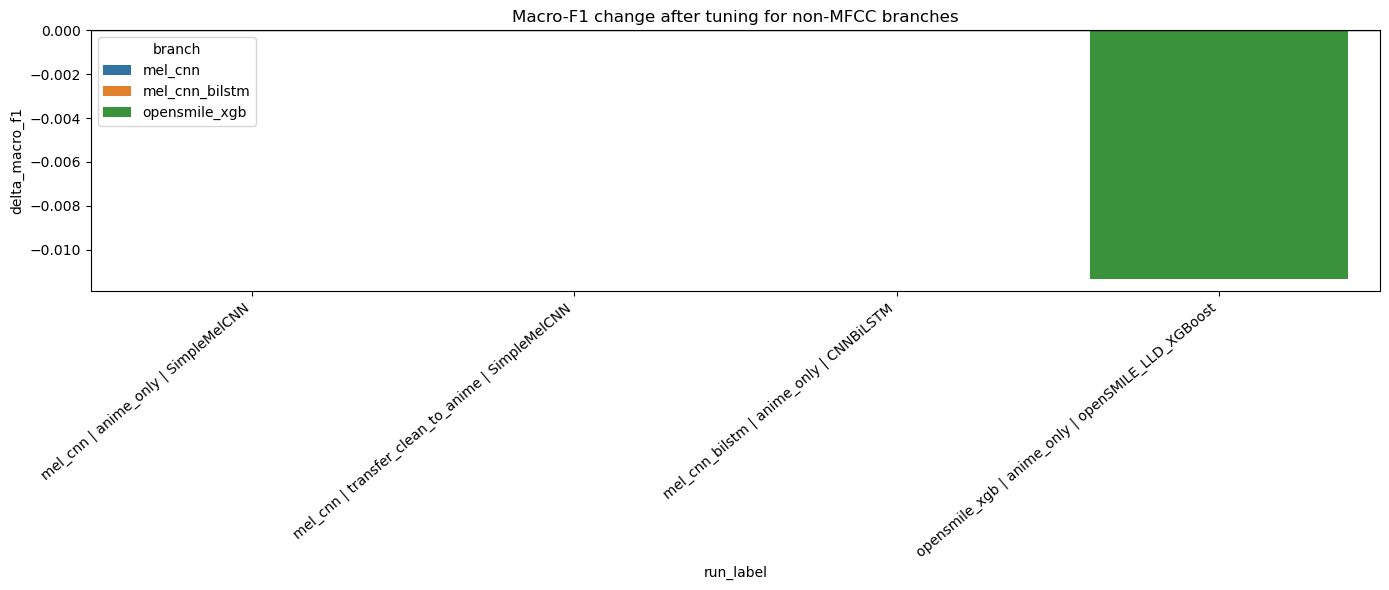

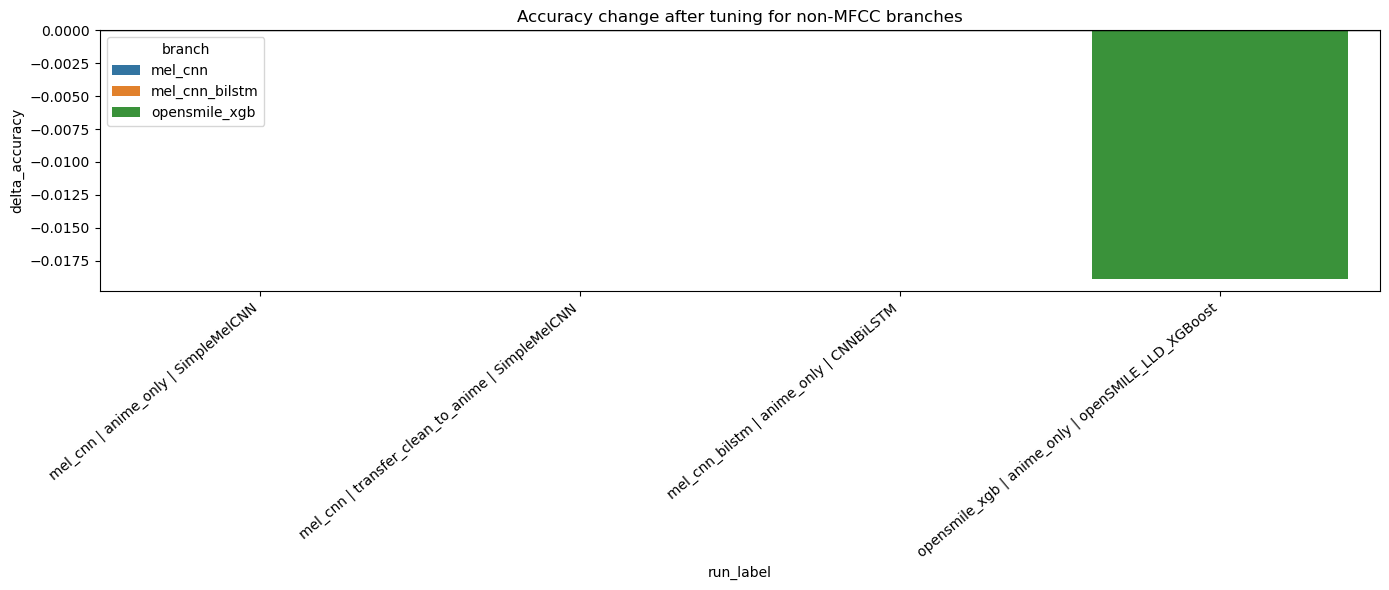

Evaluation after tuning across all branches


,mode,model_name,stage,accuracy,macro_precision,macro_recall,macro_f1,branch
0,anime_only,SimpleMelCNN,after_tuning,0.415094,0.478836,0.416951,0.394801,mel_cnn
2,transfer_clean_to_anime,SimpleMelCNN,after_tuning,0.283019,0.222325,0.345865,0.188624,mel_cnn
4,anime_only,CNNBiLSTM,after_tuning,0.075472,0.151429,0.285714,0.159030,mel_cnn_bilstm
6,anime_only,DT,after_tuning,0.377358,0.319949,0.370504,0.331138,mfcc_ml
7,anime_only,RF,after_tuning,0.452830,0.306803,0.300784,0.299940,mfcc_ml
8,anime_only,k-NN,after_tuning,0.396226,0.273076,0.286984,0.275227,mfcc_ml
9,anime_only,NB,after_tuning,0.396226,0.265266,0.283680,0.263934,mfcc_ml
10,anime_only,SVM,after_tuning,0.415094,0.360566,0.260082,0.262949,mfcc_ml
16,transfer_clean_to_anime,SVM,after_tuning,0.094340,0.029351,0.238095,0.049289,mfcc_ml
17,transfer_clean_to_anime,RF,after_tuning,0.056604,0.039116,0.190476,0.047461,mfcc_ml


Before vs after tuning across all branches


,mode,model_name,accuracy_before,accuracy_after,macro_f1_before,macro_f1_after,delta_accuracy,delta_macro_f1,branch
0,anime_only,NB,0.377358,0.396226,0.257584,0.263934,0.018868,0.006349,mfcc_ml
1,transfer_clean_to_anime,k-NN,0.018868,0.018868,0.005714,0.006079,0.000000,0.000365,mfcc_ml
2,anime_only,SimpleMelCNN,0.415094,0.415094,0.394801,0.394801,0.000000,0.000000,mel_cnn
3,transfer_clean_to_anime,SimpleMelCNN,0.283019,0.283019,0.188624,0.188624,0.000000,0.000000,mel_cnn
4,anime_only,CNNBiLSTM,0.075472,0.075472,0.159030,0.159030,0.000000,0.000000,mel_cnn_bilstm
5,transfer_clean_to_anime,NB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,mfcc_ml
6,transfer_clean_to_anime,RF,0.056604,0.056604,0.047785,0.047461,0.000000,-0.000324,mfcc_ml
7,anime_only,RF,0.452830,0.452830,0.302885,0.299940,0.000000,-0.002945,mfcc_ml
8,anime_only,openSMILE_LLD_XGBoost,0.660377,0.641509,0.403323,0.392008,-0.018868,-0.011315,opensmile_xgb
9,anime_only,DT,0.433962,0.377358,0.362369,0.331138,-0.056604,-0.031231,mfcc_ml


In [38]:
NON_MFCC_TUNING_SCORING = "f1_macro"
NON_MFCC_TUNING_CV_MAX_SPLITS = 3
FAST_NON_MFCC_TUNING = True
MAX_MEL_CNN_TUNING_CONFIGS = 1 if FAST_NON_MFCC_TUNING else None
MAX_BILSTM_TUNING_CONFIGS = 1 if FAST_NON_MFCC_TUNING else None

MEL_CNN_TUNING_CONFIGS = [
    {
        "config_name": "baseline",
        "batch_size": BATCH_SIZE,
        "epochs": CNN_EPOCHS,
        "base_lr": CNN_LR,
        "model_kwargs": {"hidden_dim": 128, "dropout": 0.30},
    },
    {
        "config_name": "dropout_0.40_lr_5e-4",
        "batch_size": BATCH_SIZE,
        "epochs": CNN_EPOCHS + 5,
        "base_lr": 5e-4,
        "model_kwargs": {"hidden_dim": 128, "dropout": 0.40},
    },
    {
        "config_name": "hidden_256_batch_32",
        "batch_size": 32,
        "epochs": CNN_EPOCHS,
        "base_lr": CNN_LR,
        "model_kwargs": {"hidden_dim": 256, "dropout": 0.30},
    },
]

BILSTM_TUNING_CONFIGS = [
    {
        "config_name": "baseline",
        "batch_size": BATCH_SIZE,
        "epochs": CNN_EPOCHS,
        "base_lr": CNN_LR,
        "model_kwargs": {"hidden_size": BILSTM_HIDDEN_SIZE, "num_layers": BILSTM_NUM_LAYERS, "dropout": BILSTM_DROPOUT},
    },
    {
        "config_name": "hidden_128_dropout_0.40",
        "batch_size": BATCH_SIZE,
        "epochs": CNN_EPOCHS + 5,
        "base_lr": 5e-4,
        "model_kwargs": {"hidden_size": 128, "num_layers": 1, "dropout": 0.40},
    },
    {
        "config_name": "hidden_64_layers_2",
        "batch_size": 32,
        "epochs": CNN_EPOCHS,
        "base_lr": CNN_LR,
        "model_kwargs": {"hidden_size": 64, "num_layers": 2, "dropout": 0.30},
    },
]

TEXT_TUNING_PARAM_GRID = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "clf__C": [0.5, 1.0, 2.0],
}

FUSION_WEIGHT_GRID = [
    (0.20, 0.80),
    (0.30, 0.70),
    (0.40, 0.60),
    (0.50, 0.50),
    (0.60, 0.40),
]

OPENSMILE_XGB_PARAM_GRID = {
    "n_estimators": [200, 300],
    "max_depth": [3, 4],
    "learning_rate": [0.03, 0.05],
    "subsample": [0.8, 0.9],
}


def select_active_tuning_configs(configs, max_configs=None):
    configs = list(configs)
    if max_configs is None or max_configs >= len(configs):
        return configs
    return configs[:max_configs]


ACTIVE_MEL_CNN_TUNING_CONFIGS = select_active_tuning_configs(
    MEL_CNN_TUNING_CONFIGS,
    max_configs=MAX_MEL_CNN_TUNING_CONFIGS,
)
ACTIVE_BILSTM_TUNING_CONFIGS = select_active_tuning_configs(
    BILSTM_TUNING_CONFIGS,
    max_configs=MAX_BILSTM_TUNING_CONFIGS,
)
ACTIVE_FUSION_WEIGHT_GRID = (
    [(TEXT_FUSION_AUDIO_WEIGHT, TEXT_FUSION_TEXT_WEIGHT)]
    if FAST_NON_MFCC_TUNING
    else FUSION_WEIGHT_GRID
)


def get_experiment_modes_for_branch(branch_name):
    modes = []
    seen = set()
    for exp in FULL_EXPERIMENTS:
        if exp["branch"] != branch_name:
            continue
        mode = exp["mode"]
        if mode not in seen:
            seen.add(mode)
            modes.append(mode)
    return modes


def format_param_text(params):
    if not params:
        return "-"
    lines = []
    for key, value in params.items():
        lines.append(f"{key} = {value}")
    return "\n".join(lines)


def build_cv_splits_from_labels(labels, max_splits=NON_MFCC_TUNING_CV_MAX_SPLITS):
    label_counts = pd.Series(labels).value_counts()
    if label_counts.empty:
        return None
    min_count = int(label_counts.min())
    if min_count < 2:
        return None
    return max(2, min(max_splits, min_count))


def build_text_grid_base_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])


def evaluate_text_model_on_df(text_model, df):
    texts = df["transcript"].astype(str).tolist()
    y_true_labels = df["emotion"].astype(str).tolist()
    y_pred_labels = text_model.predict(texts).tolist()
    prob_matrix = text_model.predict_proba(texts)
    text_scores = probabilities_to_emotion_dicts(
        prob_matrix,
        text_model.named_steps["clf"].classes_,
    )
    metrics = evaluate_label_predictions(y_true_labels, y_pred_labels)
    return {
        "y_true": y_true_labels,
        "y_pred": y_pred_labels,
        "text_scores": text_scores,
        "metrics": metrics,
    }


def fit_text_model_with_optional_grid(strict_train_df, tuned=False):
    train_texts = strict_train_df["transcript"].astype(str).tolist()
    train_labels = strict_train_df["emotion"].astype(str).tolist()

    if not tuned:
        model = build_text_emotion_model()
        model.fit(train_texts, train_labels)
        return model, {}

    cv_splits = build_cv_splits_from_labels(train_labels)
    if cv_splits is None:
        model = build_text_emotion_model()
        model.fit(train_texts, train_labels)
        return model, {"fallback": "insufficient_class_counts_for_grid_search"}

    grid = GridSearchCV(
        estimator=build_text_grid_base_model(),
        param_grid=TEXT_TUNING_PARAM_GRID,
        scoring=NON_MFCC_TUNING_SCORING,
        cv=StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=SAFE_PARALLEL_JOBS,
        verbose=1,
    )
    grid.fit(train_texts, train_labels)
    return grid.best_estimator_, grid.best_params_


def build_base_opensmile_xgb_model():
    _, XGBClassifier = load_opensmile_and_xgboost()
    return XGBClassifier(
        objective="multi:softprob",
        num_class=len(EMOTIONS),
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=SAFE_PARALLEL_JOBS,
    )


def run_cnn_config_eval(
    train_df,
    test_df,
    model_cls,
    model_name,
    model_kwargs=None,
    batch_size=BATCH_SIZE,
    epochs=CNN_EPOCHS,
    base_lr=CNN_LR,
    transfer_init_state=None,
    fine_tune=False,
):
    model_kwargs = dict(model_kwargs or {})
    train_fit_df, val_df = split_cnn_train_val(train_df)

    train_dataset = SERMelDataset(train_fit_df)
    val_dataset = SERMelDataset(val_df)
    test_dataset = SERMelDataset(test_df)

    sampler = build_weighted_sampler(train_fit_df)
    loader_kwargs = {
        "batch_size": batch_size,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    train_loader = DataLoader(train_dataset, sampler=sampler, **loader_kwargs)
    val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

    model = model_cls(n_classes=len(EMOTIONS), **model_kwargs).to(DEVICE)
    if transfer_init_state is not None:
        model.load_state_dict(transfer_init_state)

    class_weight_dict = build_class_weights(train_fit_df["label_id"].to_numpy())
    class_weights = build_class_weight_tensor(train_fit_df["label_id"].to_numpy())
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    lr = base_lr * (0.2 if fine_tune else 1.0)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=LR_REDUCE_FACTOR,
        patience=LR_REDUCE_PATIENCE,
    )

    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best_val_loss = float("inf")
    epochs_without_improvement = 0
    history = []

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler=scaler)
        val_loss = evaluate_cnn_loss(model, val_loader, criterion)
        scheduler.step(val_loss)

        history.append({
            "epoch": epoch + 1,
            "model_name": model_name,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < (best_val_loss - MIN_DELTA):
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                break

    model.load_state_dict(best_state)

    y_val_true, y_val_pred, val_probs = predict_cnn(model, val_loader)
    y_true, y_pred, probs_test = predict_cnn(model, test_loader)

    val_metrics = evaluate_predictions(y_val_true, y_val_pred) if len(y_val_true) else {
        "accuracy": 0.0,
        "macro_precision": 0.0,
        "macro_recall": 0.0,
        "macro_f1": 0.0,
    }
    metrics = evaluate_predictions(y_true, y_pred)

    return {
        "model": model,
        "history": history,
        "best_val_loss": float(best_val_loss),
        "train_meta": train_df.copy(),
        "train_fit_meta": train_fit_df.copy(),
        "val_df": val_df.copy(),
        "test_df": test_df.copy(),
        "class_weights": class_weight_dict,
        "val_true": y_val_true,
        "val_pred": y_val_pred,
        "val_probs": val_probs,
        "val_metrics": val_metrics,
        "test_true": y_true,
        "test_pred": y_pred,
        "test_probs": probs_test,
        "test_metrics": metrics,
    }


def run_mel_family_config(mode, meta_df, model_cls, model_name, config, transfer_family=False):
    batch_size = config["batch_size"]
    epochs = config["epochs"]
    base_lr = config["base_lr"]
    model_kwargs = config.get("model_kwargs", {})

    if transfer_family and mode in {"transfer_clean_to_anime", "tess_then_anime"}:
        source_train, _, _ = balance_source_dataset(meta_df, "tess")
        anime_train, anime_test = split_anime_train_test(meta_df)
        source_eval = source_train.sample(min(len(source_train), 64), random_state=RANDOM_STATE).reset_index(drop=True)

        source_run = run_cnn_config_eval(
            source_train,
            source_eval,
            model_cls=model_cls,
            model_name=model_name,
            model_kwargs=model_kwargs,
            batch_size=batch_size,
            epochs=epochs,
            base_lr=base_lr,
        )
        source_state = {k: v.cpu() for k, v in source_run["model"].state_dict().items()}

        stage2_train = anime_train.copy()
        if mode == "tess_then_anime":
            stage2_train = oversample_train_df(stage2_train, label_col="emotion")

        stage2_run = run_cnn_config_eval(
            stage2_train,
            anime_test,
            model_cls=model_cls,
            model_name=model_name,
            model_kwargs=model_kwargs,
            batch_size=batch_size,
            epochs=epochs,
            base_lr=base_lr,
            transfer_init_state=source_state,
            fine_tune=True,
        )
        stage2_run["source_run"] = source_run
        return stage2_run

    train_meta, test_meta = build_split_for_mode(mode, meta_df)
    if mode in {"anime_only", "combined"}:
        train_meta = oversample_train_df(train_meta, label_col="emotion")

    return run_cnn_config_eval(
        train_meta,
        test_meta,
        model_cls=model_cls,
        model_name=model_name,
        model_kwargs=model_kwargs,
        batch_size=batch_size,
        epochs=epochs,
        base_lr=base_lr,
    )


def select_best_cnn_run(runs):
    ranked = sorted(
        runs,
        key=lambda item: (
            item["val_metrics"]["macro_f1"],
            item["val_metrics"]["accuracy"],
            -item["best_val_loss"],
        ),
        reverse=True,
    )
    return ranked[0]


def evaluate_fusion_predictions(audio_prob_matrix, text_score_list, y_true_labels, w_audio, w_text):
    fused_preds = []
    fused_scores_all = []

    for i, text_scores in enumerate(text_score_list):
        audio_scores = {emotion: float(audio_prob_matrix[i][j]) for j, emotion in enumerate(EMOTIONS)}
        fused_scores = weighted_fusion(audio_scores, text_scores, w_audio=w_audio, w_text=w_text)
        fused_preds.append(scores_to_label(fused_scores))
        fused_scores_all.append(fused_scores)

    metrics = evaluate_label_predictions(y_true_labels, fused_preds)
    return fused_preds, fused_scores_all, metrics


def run_text_tuning_suite(mode, meta_df):
    train_df, test_df = build_split_for_mode(mode, meta_df)
    strict_train_df, _ = filter_rows_with_real_transcripts(train_df, f"Text tuning train split | {mode}")
    strict_test_df, _ = filter_rows_with_real_transcripts(test_df, f"Text tuning test split | {mode}")

    baseline_model, _ = fit_text_model_with_optional_grid(strict_train_df, tuned=False)
    baseline_eval = evaluate_text_model_on_df(baseline_model, strict_test_df)

    tuned_model, best_params = fit_text_model_with_optional_grid(strict_train_df, tuned=True)
    tuned_eval = evaluate_text_model_on_df(tuned_model, strict_test_df)

    return {
        "baseline_model": baseline_model,
        "tuned_model": tuned_model,
        "best_params": best_params,
        "baseline_eval": baseline_eval,
        "tuned_eval": tuned_eval,
        "train_meta": strict_train_df,
        "test_meta": strict_test_df,
    }


def select_best_fusion_weights(audio_prob_matrix, text_score_list, y_true_labels, weight_grid, default_pair):
    best_choice = {
        "w_audio": default_pair[0],
        "w_text": default_pair[1],
        "metrics": {"accuracy": 0.0, "macro_precision": 0.0, "macro_recall": 0.0, "macro_f1": -1.0},
    }

    for w_audio, w_text in weight_grid:
        fused_preds, fused_scores_all, metrics = evaluate_fusion_predictions(
            audio_prob_matrix,
            text_score_list,
            y_true_labels,
            w_audio=w_audio,
            w_text=w_text,
        )
        candidate = {
            "w_audio": w_audio,
            "w_text": w_text,
            "metrics": metrics,
            "y_pred": fused_preds,
            "fused_scores": fused_scores_all,
        }
        if (
            candidate["metrics"]["macro_f1"] > best_choice["metrics"]["macro_f1"]
            or (
                candidate["metrics"]["macro_f1"] == best_choice["metrics"]["macro_f1"]
                and candidate["metrics"]["accuracy"] > best_choice["metrics"]["accuracy"]
            )
        ):
            best_choice = candidate

    return best_choice


def run_fusion_tuning_suite(mode, baseline_audio_run, tuned_audio_run):
    baseline_train_df = baseline_audio_run["train_meta"].copy()
    baseline_test_df = baseline_audio_run["test_df"].copy()
    strict_train_df, _ = filter_rows_with_real_transcripts(baseline_train_df, f"Fusion train split | {mode}")
    strict_test_df, test_mask = filter_rows_with_real_transcripts(baseline_test_df, f"Fusion test split | {mode}")

    baseline_text_model, _ = fit_text_model_with_optional_grid(strict_train_df, tuned=False)
    baseline_text_eval = evaluate_text_model_on_df(baseline_text_model, strict_test_df)
    baseline_audio_probs = np.asarray(baseline_audio_run["test_probs"])[test_mask]
    baseline_preds, baseline_scores, baseline_metrics = evaluate_fusion_predictions(
        baseline_audio_probs,
        baseline_text_eval["text_scores"],
        strict_test_df["emotion"].astype(str).tolist(),
        w_audio=TEXT_FUSION_AUDIO_WEIGHT,
        w_text=TEXT_FUSION_TEXT_WEIGHT,
    )

    tuned_train_df = tuned_audio_run["train_meta"].copy()
    tuned_val_df = tuned_audio_run["val_df"].copy()
    tuned_test_df = tuned_audio_run["test_df"].copy()
    strict_train_tuned_df, _ = filter_rows_with_real_transcripts(tuned_train_df, f"Fusion tuned train split | {mode}")

    tuned_text_model, tuned_text_best_params = fit_text_model_with_optional_grid(strict_train_tuned_df, tuned=True)

    try:
        strict_val_df, val_mask = filter_rows_with_real_transcripts(tuned_val_df, f"Fusion validation split | {mode}")
        tuned_val_text_eval = evaluate_text_model_on_df(tuned_text_model, strict_val_df)
        tuned_val_audio_probs = np.asarray(tuned_audio_run["val_probs"])[val_mask]
        best_weight_choice = select_best_fusion_weights(
            tuned_val_audio_probs,
            tuned_val_text_eval["text_scores"],
            strict_val_df["emotion"].astype(str).tolist(),
            ACTIVE_FUSION_WEIGHT_GRID,
            default_pair=(TEXT_FUSION_AUDIO_WEIGHT, TEXT_FUSION_TEXT_WEIGHT),
        )
    except Exception:
        best_weight_choice = {
            "w_audio": TEXT_FUSION_AUDIO_WEIGHT,
            "w_text": TEXT_FUSION_TEXT_WEIGHT,
            "metrics": {"accuracy": np.nan, "macro_precision": np.nan, "macro_recall": np.nan, "macro_f1": np.nan},
        }

    strict_test_tuned_df, tuned_test_mask = filter_rows_with_real_transcripts(tuned_test_df, f"Fusion tuned test split | {mode}")
    tuned_test_text_eval = evaluate_text_model_on_df(tuned_text_model, strict_test_tuned_df)
    tuned_test_audio_probs = np.asarray(tuned_audio_run["test_probs"])[tuned_test_mask]
    tuned_preds, tuned_scores, tuned_metrics = evaluate_fusion_predictions(
        tuned_test_audio_probs,
        tuned_test_text_eval["text_scores"],
        strict_test_tuned_df["emotion"].astype(str).tolist(),
        w_audio=best_weight_choice["w_audio"],
        w_text=best_weight_choice["w_text"],
    )

    return {
        "baseline_metrics": baseline_metrics,
        "tuned_metrics": tuned_metrics,
        "baseline_model_name": "SimpleMelCNN+TFIDFLogRegFusion",
        "tuned_model_name": "SimpleMelCNN+TFIDFLogRegFusion",
        "baseline_params": {
            "audio_config": baseline_audio_run["config_name"],
            "text_model": "baseline",
            "w_audio": TEXT_FUSION_AUDIO_WEIGHT,
            "w_text": TEXT_FUSION_TEXT_WEIGHT,
        },
        "tuned_params": {
            "audio_config": tuned_audio_run["config_name"],
            "text_model_params": tuned_text_best_params,
            "w_audio": best_weight_choice["w_audio"],
            "w_text": best_weight_choice["w_text"],
            "validation_macro_f1": best_weight_choice["metrics"]["macro_f1"],
        },
        "baseline_artifacts": {
            "y_true": strict_test_df["emotion"].astype(str).tolist(),
            "y_pred": baseline_preds,
            "fused_scores": baseline_scores,
            "text_model": baseline_text_model,
        },
        "tuned_artifacts": {
            "y_true": strict_test_tuned_df["emotion"].astype(str).tolist(),
            "y_pred": tuned_preds,
            "fused_scores": tuned_scores,
            "text_model": tuned_text_model,
        },
    }


def run_opensmile_tuning_suite(mode, meta_df):
    _, XGBClassifier = load_opensmile_and_xgboost()
    train_meta, test_meta = build_split_for_mode(mode, meta_df)
    if mode in {"anime_only", "combined"}:
        train_meta = oversample_train_df(train_meta, label_col="emotion")

    smile = make_opensmile_lld_extractor()
    train_feat = build_opensmile_feature_df(train_meta, smile=smile)
    test_feat = build_opensmile_feature_df(test_meta, smile=smile)
    feature_cols = [col for col in train_feat.columns if col not in {"emotion", "label_id", "file_path"}]

    X_train = train_feat[feature_cols].copy()
    y_train = train_feat["label_id"].to_numpy(dtype=int)
    X_test = test_feat.reindex(columns=feature_cols, fill_value=0.0).copy()
    y_test = test_feat["label_id"].to_numpy(dtype=int)

    baseline_model = build_base_opensmile_xgb_model()
    baseline_model.fit(X_train, y_train)
    baseline_pred = baseline_model.predict(X_test).astype(int)
    baseline_metrics = evaluate_predictions(y_test, baseline_pred)

    cv_splits = build_cv_splits_from_labels(y_train)
    if cv_splits is None:
        tuned_model = baseline_model
        tuned_pred = baseline_pred
        tuned_metrics = baseline_metrics
        best_params = {"fallback": "insufficient_class_counts_for_grid_search"}
    else:
        grid = GridSearchCV(
            estimator=build_base_opensmile_xgb_model(),
            param_grid=OPENSMILE_XGB_PARAM_GRID,
            scoring=NON_MFCC_TUNING_SCORING,
            cv=StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE),
            n_jobs=SAFE_PARALLEL_JOBS,
            verbose=1,
        )
        grid.fit(X_train, y_train)
        tuned_model = grid.best_estimator_
        tuned_pred = tuned_model.predict(X_test).astype(int)
        tuned_metrics = evaluate_predictions(y_test, tuned_pred)
        best_params = grid.best_params_

    return {
        "baseline_metrics": baseline_metrics,
        "tuned_metrics": tuned_metrics,
        "best_params": best_params,
        "baseline_pred": baseline_pred,
        "tuned_pred": tuned_pred,
    }


non_mfcc_tuning_rows = []
non_mfcc_tuning_comparison_rows = []
non_mfcc_selected_params_rows = []
non_mfcc_skipped_tuning_rows = []

if FAST_NON_MFCC_TUNING:
    print(
        "Fast non-MFCC tuning mode is enabled: "
        f"mel_cnn configs={len(ACTIVE_MEL_CNN_TUNING_CONFIGS)}, "
        f"bilstm configs={len(ACTIVE_BILSTM_TUNING_CONFIGS)}, "
        f"fusion weights={len(ACTIVE_FUSION_WEIGHT_GRID)}"
    )

mel_cnn_tuning_runs = {}
for mode in get_experiment_modes_for_branch("mel_cnn"):
    print(f"Tuning mel_cnn | {mode}")
    mel_cnn_runs = []
    for config in ACTIVE_MEL_CNN_TUNING_CONFIGS:
        run = run_mel_family_config(
            mode,
            meta_filtered_df,
            model_cls=SimpleMelCNN,
            model_name="SimpleMelCNN",
            config=config,
            transfer_family=True,
        )
        run["config_name"] = config["config_name"]
        run["selected_params"] = {
            "batch_size": config["batch_size"],
            "epochs": config["epochs"],
            "base_lr": config["base_lr"],
            **config.get("model_kwargs", {}),
        }
        mel_cnn_runs.append(run)

    baseline_run = mel_cnn_runs[0]
    tuned_run = select_best_cnn_run(mel_cnn_runs)
    mel_cnn_tuning_runs[mode] = {"baseline": baseline_run, "tuned": tuned_run}

    non_mfcc_tuning_rows.extend([
        {"branch": "mel_cnn", "mode": mode, "model_name": "SimpleMelCNN", "stage": "before_tuning", **baseline_run["test_metrics"]},
        {"branch": "mel_cnn", "mode": mode, "model_name": "SimpleMelCNN", "stage": "after_tuning", **tuned_run["test_metrics"]},
    ])
    non_mfcc_tuning_comparison_rows.append({
        "branch": "mel_cnn",
        "mode": mode,
        "model_name": "SimpleMelCNN",
        "accuracy_before": baseline_run["test_metrics"]["accuracy"],
        "accuracy_after": tuned_run["test_metrics"]["accuracy"],
        "macro_f1_before": baseline_run["test_metrics"]["macro_f1"],
        "macro_f1_after": tuned_run["test_metrics"]["macro_f1"],
        "delta_accuracy": tuned_run["test_metrics"]["accuracy"] - baseline_run["test_metrics"]["accuracy"],
        "delta_macro_f1": tuned_run["test_metrics"]["macro_f1"] - baseline_run["test_metrics"]["macro_f1"],
    })
    non_mfcc_selected_params_rows.append({
        "branch": "mel_cnn",
        "mode": mode,
        "model_name": "SimpleMelCNN",
        "selected_params": format_param_text(tuned_run["selected_params"]),
        "selection_basis": f"validation macro_f1 = {tuned_run['val_metrics']['macro_f1']:.4f}",
    })


mel_cnn_bilstm_tuning_runs = {}
for mode in get_experiment_modes_for_branch("mel_cnn_bilstm"):
    print(f"Tuning mel_cnn_bilstm | {mode}")
    bilstm_runs = []
    for config in ACTIVE_BILSTM_TUNING_CONFIGS:
        run = run_mel_family_config(
            mode,
            meta_filtered_df,
            model_cls=MelCNNBiLSTM,
            model_name="CNNBiLSTM",
            config=config,
            transfer_family=True,
        )
        run["config_name"] = config["config_name"]
        run["selected_params"] = {
            "batch_size": config["batch_size"],
            "epochs": config["epochs"],
            "base_lr": config["base_lr"],
            **config.get("model_kwargs", {}),
        }
        bilstm_runs.append(run)

    baseline_run = bilstm_runs[0]
    tuned_run = select_best_cnn_run(bilstm_runs)
    mel_cnn_bilstm_tuning_runs[mode] = {"baseline": baseline_run, "tuned": tuned_run}

    non_mfcc_tuning_rows.extend([
        {"branch": "mel_cnn_bilstm", "mode": mode, "model_name": "CNNBiLSTM", "stage": "before_tuning", **baseline_run["test_metrics"]},
        {"branch": "mel_cnn_bilstm", "mode": mode, "model_name": "CNNBiLSTM", "stage": "after_tuning", **tuned_run["test_metrics"]},
    ])
    non_mfcc_tuning_comparison_rows.append({
        "branch": "mel_cnn_bilstm",
        "mode": mode,
        "model_name": "CNNBiLSTM",
        "accuracy_before": baseline_run["test_metrics"]["accuracy"],
        "accuracy_after": tuned_run["test_metrics"]["accuracy"],
        "macro_f1_before": baseline_run["test_metrics"]["macro_f1"],
        "macro_f1_after": tuned_run["test_metrics"]["macro_f1"],
        "delta_accuracy": tuned_run["test_metrics"]["accuracy"] - baseline_run["test_metrics"]["accuracy"],
        "delta_macro_f1": tuned_run["test_metrics"]["macro_f1"] - baseline_run["test_metrics"]["macro_f1"],
    })
    non_mfcc_selected_params_rows.append({
        "branch": "mel_cnn_bilstm",
        "mode": mode,
        "model_name": "CNNBiLSTM",
        "selected_params": format_param_text(tuned_run["selected_params"]),
        "selection_basis": f"validation macro_f1 = {tuned_run['val_metrics']['macro_f1']:.4f}",
    })


text_tuning_runs = {}
for mode in get_experiment_modes_for_branch("text_only"):
    print(f"Tuning text_only | {mode}")
    try:
        suite = run_text_tuning_suite(mode, meta_filtered_df)
    except ValueError as exc:
        print(f"[SKIP] text_only | {mode} -> {exc}")
        non_mfcc_skipped_tuning_rows.append({
            "branch": "text_only",
            "mode": mode,
            "model_name": "TFIDF+LogRegText",
            "reason": str(exc),
        })
        continue

    text_tuning_runs[mode] = suite
    non_mfcc_tuning_rows.extend([
        {"branch": "text_only", "mode": mode, "model_name": "TFIDF+LogRegText", "stage": "before_tuning", **suite["baseline_eval"]["metrics"]},
        {"branch": "text_only", "mode": mode, "model_name": "TFIDF+LogRegText", "stage": "after_tuning", **suite["tuned_eval"]["metrics"]},
    ])
    non_mfcc_tuning_comparison_rows.append({
        "branch": "text_only",
        "mode": mode,
        "model_name": "TFIDF+LogRegText",
        "accuracy_before": suite["baseline_eval"]["metrics"]["accuracy"],
        "accuracy_after": suite["tuned_eval"]["metrics"]["accuracy"],
        "macro_f1_before": suite["baseline_eval"]["metrics"]["macro_f1"],
        "macro_f1_after": suite["tuned_eval"]["metrics"]["macro_f1"],
        "delta_accuracy": suite["tuned_eval"]["metrics"]["accuracy"] - suite["baseline_eval"]["metrics"]["accuracy"],
        "delta_macro_f1": suite["tuned_eval"]["metrics"]["macro_f1"] - suite["baseline_eval"]["metrics"]["macro_f1"],
    })
    non_mfcc_selected_params_rows.append({
        "branch": "text_only",
        "mode": mode,
        "model_name": "TFIDF+LogRegText",
        "selected_params": format_param_text(suite["best_params"]),
        "selection_basis": "GridSearchCV best_params_",
    })


fusion_tuning_runs = {}
for mode in get_experiment_modes_for_branch("audio_text_fusion"):
    print(f"Tuning audio_text_fusion | {mode}")
    if mode not in mel_cnn_tuning_runs:
        reason = "matching mel_cnn tuning run is unavailable"
        print(f"[SKIP] audio_text_fusion | {mode} -> {reason}")
        non_mfcc_skipped_tuning_rows.append({
            "branch": "audio_text_fusion",
            "mode": mode,
            "model_name": "SimpleMelCNN+TFIDFLogRegFusion",
            "reason": reason,
        })
        continue

    try:
        suite = run_fusion_tuning_suite(
            mode,
            mel_cnn_tuning_runs[mode]["baseline"],
            mel_cnn_tuning_runs[mode]["tuned"],
        )
    except ValueError as exc:
        print(f"[SKIP] audio_text_fusion | {mode} -> {exc}")
        non_mfcc_skipped_tuning_rows.append({
            "branch": "audio_text_fusion",
            "mode": mode,
            "model_name": "SimpleMelCNN+TFIDFLogRegFusion",
            "reason": str(exc),
        })
        continue

    fusion_tuning_runs[mode] = suite
    non_mfcc_tuning_rows.extend([
        {"branch": "audio_text_fusion", "mode": mode, "model_name": "SimpleMelCNN+TFIDFLogRegFusion", "stage": "before_tuning", **suite["baseline_metrics"]},
        {"branch": "audio_text_fusion", "mode": mode, "model_name": "SimpleMelCNN+TFIDFLogRegFusion", "stage": "after_tuning", **suite["tuned_metrics"]},
    ])
    non_mfcc_tuning_comparison_rows.append({
        "branch": "audio_text_fusion",
        "mode": mode,
        "model_name": "SimpleMelCNN+TFIDFLogRegFusion",
        "accuracy_before": suite["baseline_metrics"]["accuracy"],
        "accuracy_after": suite["tuned_metrics"]["accuracy"],
        "macro_f1_before": suite["baseline_metrics"]["macro_f1"],
        "macro_f1_after": suite["tuned_metrics"]["macro_f1"],
        "delta_accuracy": suite["tuned_metrics"]["accuracy"] - suite["baseline_metrics"]["accuracy"],
        "delta_macro_f1": suite["tuned_metrics"]["macro_f1"] - suite["baseline_metrics"]["macro_f1"],
    })
    non_mfcc_selected_params_rows.append({
        "branch": "audio_text_fusion",
        "mode": mode,
        "model_name": "SimpleMelCNN+TFIDFLogRegFusion",
        "selected_params": format_param_text(suite["tuned_params"]),
        "selection_basis": "validation macro_f1 on fusion weights",
    })


opensmile_tuning_runs = {}
for mode in get_experiment_modes_for_branch("opensmile_xgb"):
    print(f"Tuning opensmile_xgb | {mode}")
    suite = run_opensmile_tuning_suite(mode, meta_filtered_df)
    opensmile_tuning_runs[mode] = suite
    non_mfcc_tuning_rows.extend([
        {"branch": "opensmile_xgb", "mode": mode, "model_name": "openSMILE_LLD_XGBoost", "stage": "before_tuning", **suite["baseline_metrics"]},
        {"branch": "opensmile_xgb", "mode": mode, "model_name": "openSMILE_LLD_XGBoost", "stage": "after_tuning", **suite["tuned_metrics"]},
    ])
    non_mfcc_tuning_comparison_rows.append({
        "branch": "opensmile_xgb",
        "mode": mode,
        "model_name": "openSMILE_LLD_XGBoost",
        "accuracy_before": suite["baseline_metrics"]["accuracy"],
        "accuracy_after": suite["tuned_metrics"]["accuracy"],
        "macro_f1_before": suite["baseline_metrics"]["macro_f1"],
        "macro_f1_after": suite["tuned_metrics"]["macro_f1"],
        "delta_accuracy": suite["tuned_metrics"]["accuracy"] - suite["baseline_metrics"]["accuracy"],
        "delta_macro_f1": suite["tuned_metrics"]["macro_f1"] - suite["baseline_metrics"]["macro_f1"],
    })
    non_mfcc_selected_params_rows.append({
        "branch": "opensmile_xgb",
        "mode": mode,
        "model_name": "openSMILE_LLD_XGBoost",
        "selected_params": format_param_text(suite["best_params"]),
        "selection_basis": "GridSearchCV best_params_",
    })


non_mfcc_tuning_results_df = pd.DataFrame(non_mfcc_tuning_rows).sort_values(
    ["branch", "mode", "stage", "macro_f1", "accuracy"],
    ascending=[True, True, True, False, False],
).reset_index(drop=True)
non_mfcc_tuning_comparison_df = pd.DataFrame(non_mfcc_tuning_comparison_rows).sort_values(
    ["delta_macro_f1", "delta_accuracy", "branch", "mode"],
    ascending=[False, False, True, True],
).reset_index(drop=True)
non_mfcc_selected_params_df = pd.DataFrame(non_mfcc_selected_params_rows).sort_values(
    ["branch", "mode", "model_name"]
).reset_index(drop=True)

if non_mfcc_skipped_tuning_rows:
    non_mfcc_skipped_tuning_df = pd.DataFrame(non_mfcc_skipped_tuning_rows)
    print("Skipped non-MFCC tuning branches")
    display(non_mfcc_skipped_tuning_df)

print("Evaluation after tuning for non-MFCC branches")
display(non_mfcc_tuning_results_df[non_mfcc_tuning_results_df["stage"] == "after_tuning"])
print("Before vs after tuning for non-MFCC branches")
display(non_mfcc_tuning_comparison_df)
print("Selected tuning parameters for non-MFCC branches")
display(
    non_mfcc_selected_params_df.style.set_properties(**{
        "text-align": "left",
        "white-space": "pre-wrap",
    }).set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("vertical-align", "top")]},
    ])
)

plt.figure(figsize=(14, 6))
plot_non_mfcc_df = non_mfcc_tuning_comparison_df.copy()
plot_non_mfcc_df["run_label"] = plot_non_mfcc_df[["branch", "mode", "model_name"]].astype(str).agg(" | ".join, axis=1)
sns.barplot(data=plot_non_mfcc_df, x="run_label", y="delta_macro_f1", hue="branch", dodge=False)
plt.axhline(0.0, color="black", linewidth=1)
plt.title("Macro-F1 change after tuning for non-MFCC branches")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_non_mfcc_df, x="run_label", y="delta_accuracy", hue="branch", dodge=False)
plt.axhline(0.0, color="black", linewidth=1)
plt.title("Accuracy change after tuning for non-MFCC branches")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

all_branch_tuning_results_df = non_mfcc_tuning_results_df.copy()
all_branch_tuning_comparison_df = non_mfcc_tuning_comparison_df.copy()

if "mfcc_baseline_before_tuning_df" in globals() and len(mfcc_baseline_before_tuning_df):
    mfcc_before_all = mfcc_baseline_before_tuning_df.copy()
    mfcc_before_all["branch"] = "mfcc_ml"
    mfcc_after_all = mfcc_tuned_results_df.copy() if "mfcc_tuned_results_df" in globals() and len(mfcc_tuned_results_df) else pd.DataFrame()
    if len(mfcc_after_all):
        mfcc_after_all["branch"] = "mfcc_ml"
        mfcc_all_results = pd.concat([mfcc_before_all, mfcc_after_all], ignore_index=True)
        all_branch_tuning_results_df = pd.concat([mfcc_all_results, non_mfcc_tuning_results_df], ignore_index=True)

    if "mfcc_tuning_comparison_df" in globals() and len(mfcc_tuning_comparison_df):
        mfcc_all_compare = mfcc_tuning_comparison_df.copy()
        mfcc_all_compare["branch"] = "mfcc_ml"
        all_branch_tuning_comparison_df = pd.concat([mfcc_all_compare, non_mfcc_tuning_comparison_df], ignore_index=True)

all_branch_tuning_results_df = all_branch_tuning_results_df.sort_values(
    ["branch", "mode", "stage", "macro_f1", "accuracy"],
    ascending=[True, True, True, False, False],
).reset_index(drop=True)
all_branch_tuning_comparison_df = all_branch_tuning_comparison_df.sort_values(
    ["delta_macro_f1", "delta_accuracy", "branch", "mode"],
    ascending=[False, False, True, True],
).reset_index(drop=True)

print("Evaluation after tuning across all branches")
display(all_branch_tuning_results_df[all_branch_tuning_results_df["stage"] == "after_tuning"])
print("Before vs after tuning across all branches")
display(all_branch_tuning_comparison_df)




## 19. Detailed branch inspection across all calculated methods and modes

Use this section to inspect the best result from every calculated `branch + mode` combination with the same kind of detailed output used in the paper notebook: classification report, confusion matrix, and per-model metric bar charts.

Detailed inspection targets:


,Branch,Mode,Requested model
0,openSMILE,Anime only,openSMILE_LLD_XGBoost
1,MelCNN,Anime only,SimpleMelCNN
2,MFCC-ML,Anime only,DT
3,MelCNN-BiLSTM,Anime only,CNNBiLSTM
4,MelCNN,Transfer clean->anime,SimpleMelCNN
5,MFCC-ML,Transfer clean->anime,DT


Model ranking for openSMILE | Anime only:


,Model,Accuracy,Macro-F1
0,LLD XGBoost,0.6981,0.5029


Classification report for openSMILE | Anime only | LLD XGBoost
                   precision    recall  f1-score   support

            angry     0.0000    0.0000    0.0000         1
          disgust     0.5000    0.3333    0.4000         3
             fear     0.7000    0.6364    0.6667        11
            happy     0.4000    0.3333    0.3636         6
          neutral     0.5714    0.6667    0.6154         6
pleasant_surprise     0.4444    0.5714    0.5000         7
              sad     0.9500    1.0000    0.9744        19

         accuracy                         0.6981        53
        macro avg     0.5094    0.5059    0.5029        53
     weighted avg     0.6828    0.6981    0.6872        53



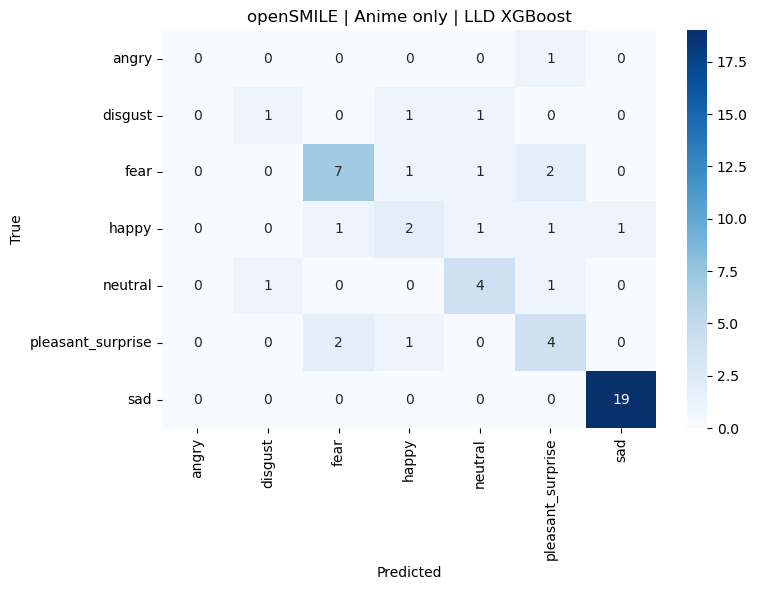

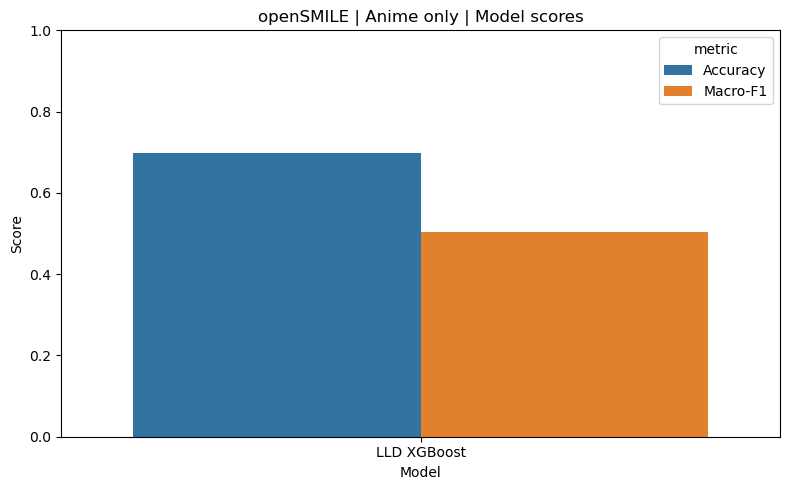

Model ranking for MelCNN | Anime only:


,Model,Accuracy,Macro-F1
0,SimpleMelCNN,0.4528,0.3936


Classification report for MelCNN | Anime only | SimpleMelCNN
                   precision    recall  f1-score   support

            angry     1.0000    1.0000    1.0000         1
          disgust     0.2500    0.3333    0.2857         3
             fear     0.5000    0.3636    0.4211        11
            happy     0.2000    0.1667    0.1818         6
          neutral     0.2500    0.1667    0.2000         6
pleasant_surprise     0.0000    0.0000    0.0000         7
              sad     0.5517    0.8421    0.6667        19

         accuracy                         0.4528        53
        macro avg     0.3931    0.4103    0.3936        53
     weighted avg     0.3855    0.4528    0.4046        53



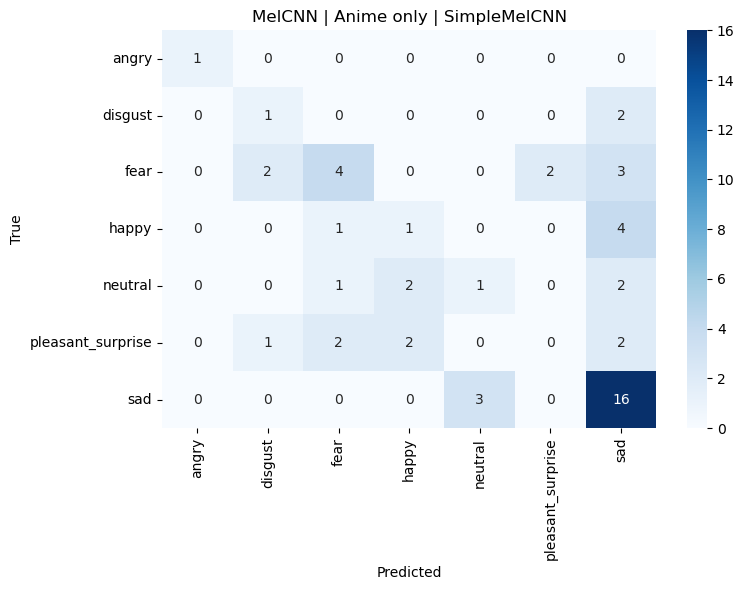

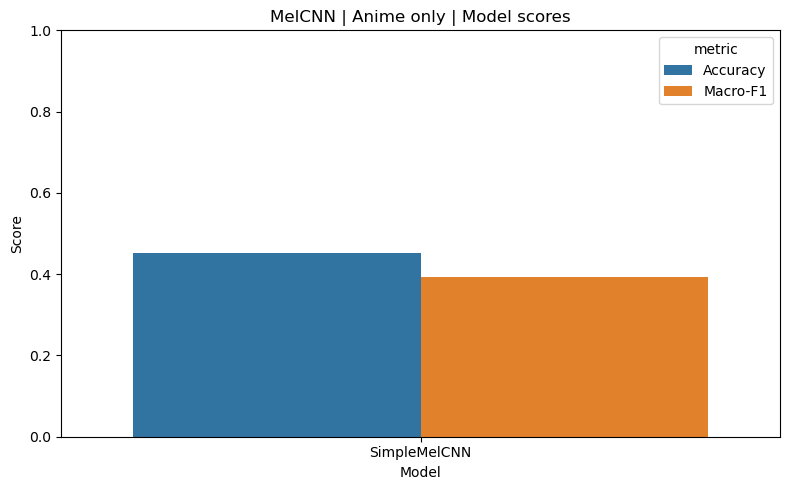

Model ranking for MFCC-ML | Anime only:


,Model,Accuracy,Macro-F1
0,DT,0.4528,0.3646
1,RF,0.4717,0.3543
2,k-NN,0.4340,0.3471
3,NB,0.4340,0.3051
4,SVM,0.3962,0.2997


Classification report for MFCC-ML | Anime only | DT
                   precision    recall  f1-score   support

            angry     0.0000    0.0000    0.0000         1
          disgust     0.3333    0.6667    0.4444         3
             fear     0.2727    0.2727    0.2727        11
            happy     0.2500    0.3333    0.2857         6
          neutral     0.4286    0.5000    0.4615         6
pleasant_surprise     0.3750    0.4286    0.4000         7
              sad     0.8462    0.5789    0.6875        19

         accuracy                         0.4528        53
        macro avg     0.3580    0.3972    0.3646        53
     weighted avg     0.5052    0.4528    0.4656        53



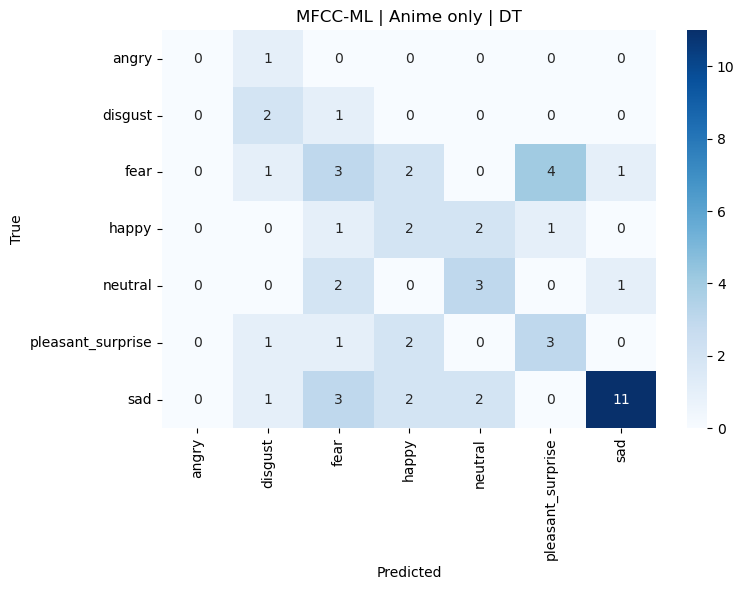

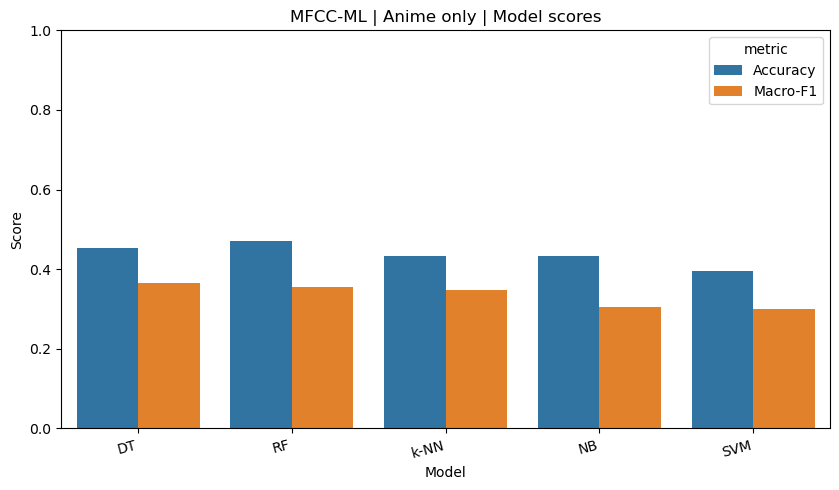

Model ranking for MelCNN-BiLSTM | Anime only:


,Model,Accuracy,Macro-F1
0,CNN-BiLSTM,0.3396,0.2583


Classification report for MelCNN-BiLSTM | Anime only | CNN-BiLSTM
                   precision    recall  f1-score   support

            angry     0.5000    1.0000    0.6667         1
          disgust     0.0000    0.0000    0.0000         3
             fear     0.5000    0.0909    0.1538        11
            happy     0.0000    0.0000    0.0000         6
          neutral     0.2000    0.1667    0.1818         6
pleasant_surprise     0.2857    0.2857    0.2857         7
              sad     0.4194    0.6842    0.5200        19

         accuracy                         0.3396        53
        macro avg     0.2722    0.3182    0.2583        53
     weighted avg     0.3239    0.3396    0.2892        53



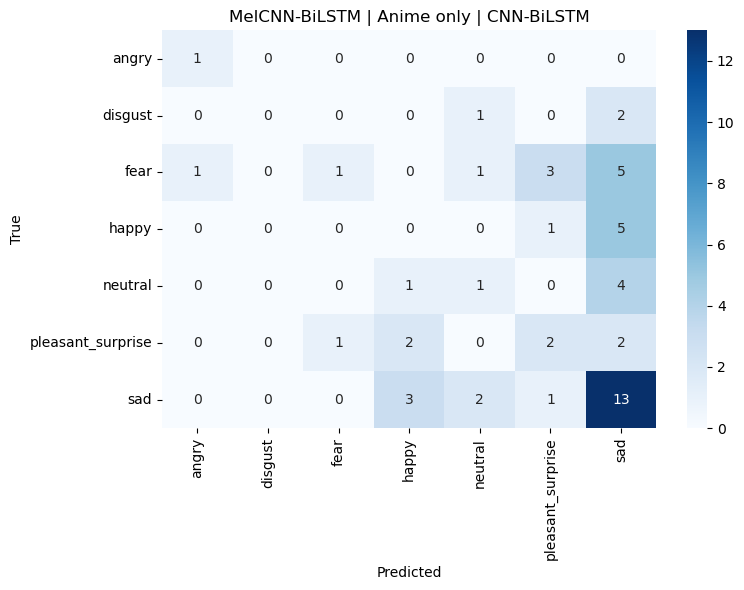

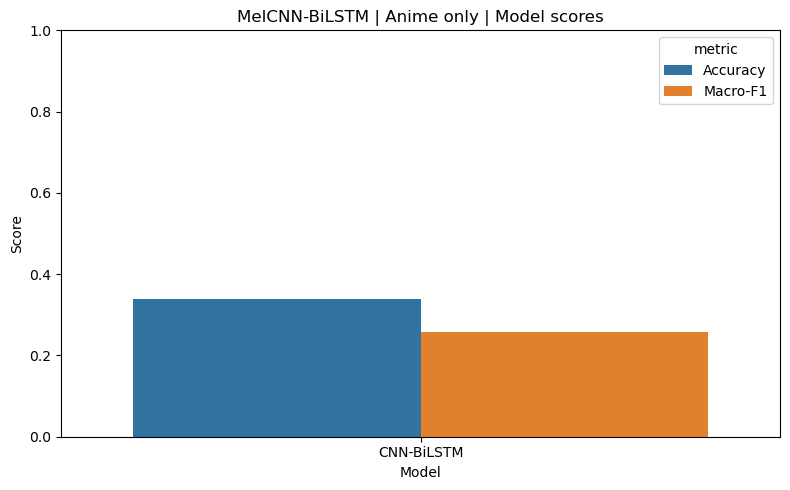

Model ranking for MelCNN | Transfer clean->anime:


,Model,Accuracy,Macro-F1
0,SimpleMelCNN,0.1698,0.1477


Classification report for MelCNN | Transfer clean->anime | SimpleMelCNN
                   precision    recall  f1-score   support

            angry     0.1667    1.0000    0.2857         1
          disgust     0.1304    1.0000    0.2308         3
             fear     0.1667    0.0909    0.1176        11
            happy     0.0000    0.0000    0.0000         6
          neutral     0.2857    0.6667    0.4000         6
pleasant_surprise     0.0000    0.0000    0.0000         7
              sad     0.0000    0.0000    0.0000        19

         accuracy                         0.1698        53
        macro avg     0.1071    0.3939    0.1477        53
     weighted avg     0.0775    0.1698    0.0882        53



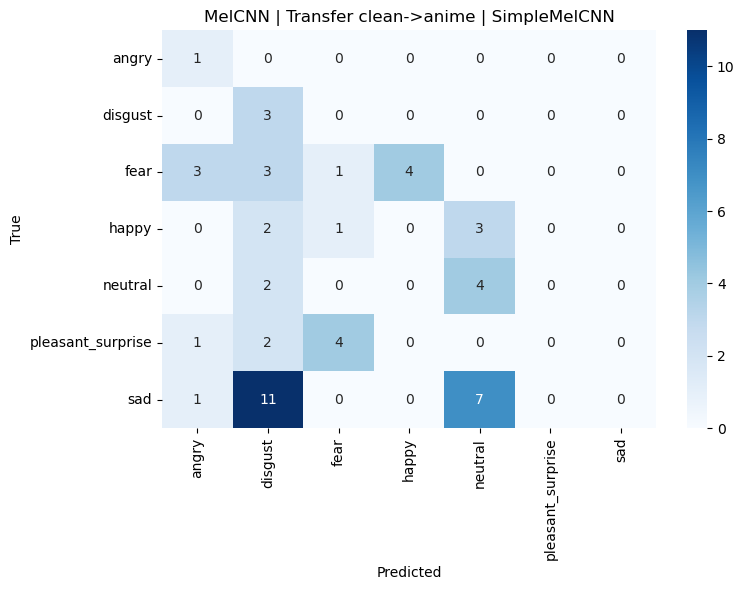

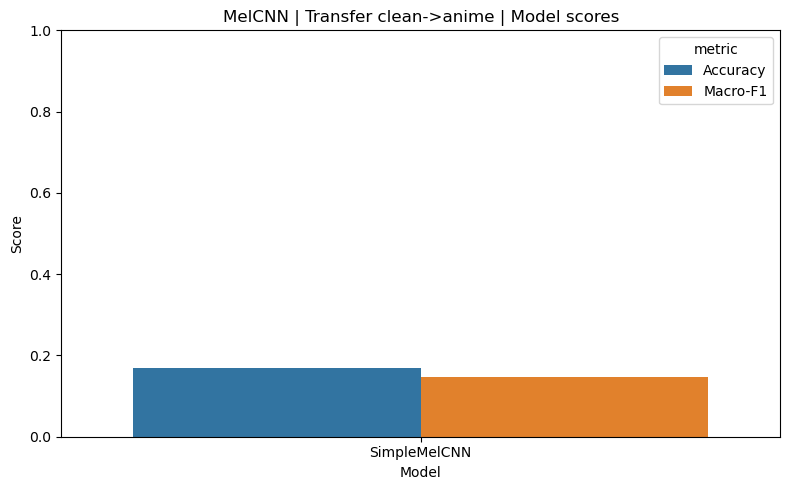

Model ranking for MFCC-ML | Transfer clean->anime:


,Model,Accuracy,Macro-F1
0,DT,0.0755,0.0576
1,RF,0.0755,0.0572
2,SVM,0.0189,0.0062
3,k-NN,0.0189,0.0058
4,NB,0.0000,0.0000


Classification report for MFCC-ML | Transfer clean->anime | DT
                   precision    recall  f1-score   support

            angry     0.0256    1.0000    0.0500         1
          disgust     0.0000    0.0000    0.0000         3
             fear     0.0000    0.0000    0.0000        11
            happy     0.0000    0.0000    0.0000         6
          neutral     0.2727    0.5000    0.3529         6
pleasant_surprise     0.0000    0.0000    0.0000         7
              sad     0.0000    0.0000    0.0000        19

         accuracy                         0.0755        53
        macro avg     0.0426    0.2143    0.0576        53
     weighted avg     0.0314    0.0755    0.0409        53



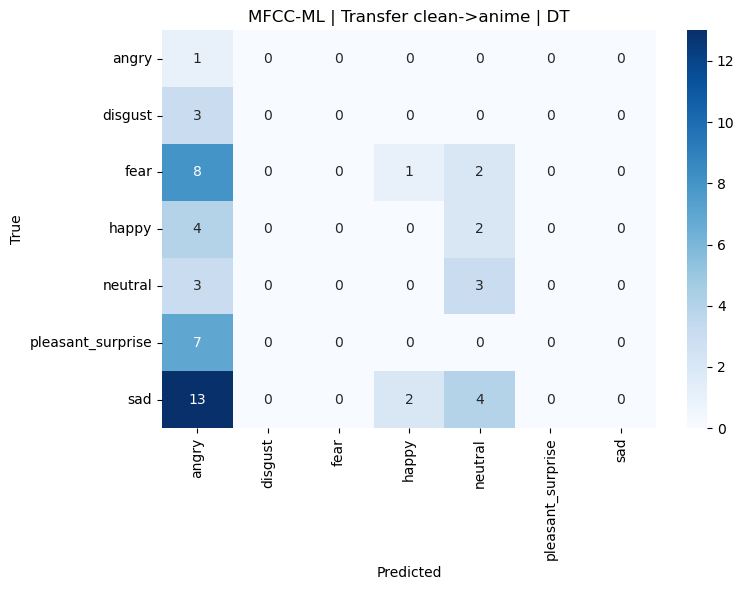

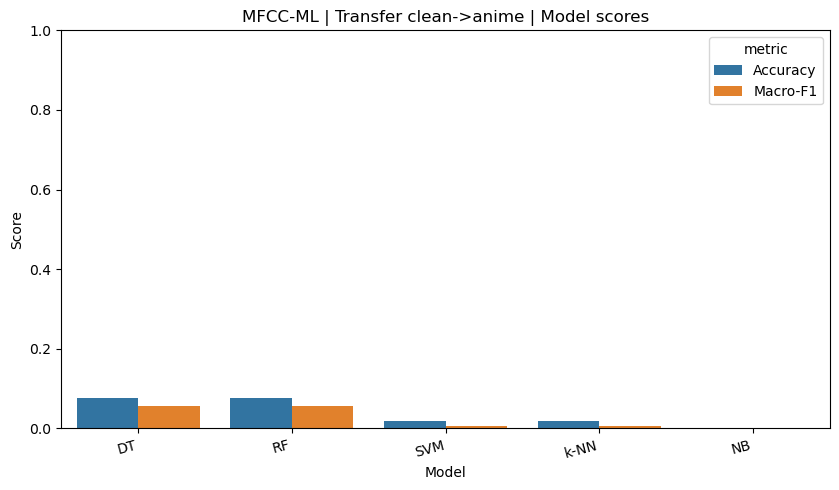

In [39]:
def get_branch_mode_predictions(branch, mode, model_name=None):
    if "all_artifacts" not in globals() or "experiment_results_df" not in globals():
        raise ValueError("Run all experiments first.")

    key = (branch, mode)
    if key not in all_artifacts:
        raise KeyError(f"No artifacts found for {branch} | {mode}")

    result_rows = experiment_results_df[
        (experiment_results_df["branch"] == branch) & (experiment_results_df["mode"] == mode)
    ].sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
    if result_rows.empty:
        raise ValueError(f"No result rows found for {branch} | {mode}")

    if model_name is None:
        model_name = result_rows.iloc[0]["model_name"]

    artifacts = all_artifacts[key]
    if "predictions" in artifacts and "y_test" in artifacts:
        if model_name not in artifacts["predictions"]:
            model_name = result_rows.iloc[0]["model_name"]
        y_true = np.asarray(artifacts["y_test"]).astype(int)
        y_pred = np.asarray(artifacts["predictions"][model_name]).astype(int)
        y_true_labels = label_encoder.inverse_transform(y_true).tolist()
        y_pred_labels = label_encoder.inverse_transform(y_pred).tolist()
    elif "y_true" in artifacts and "y_pred" in artifacts:
        y_true_labels = [str(x) for x in artifacts["y_true"]]
        y_pred_labels = [str(x) for x in artifacts["y_pred"]]
    else:
        raise ValueError(
            f"Artifacts for {branch} | {mode} do not include predictions in a supported format."
        )

    return result_rows, model_name, y_true_labels, y_pred_labels


def get_best_branch_mode_rows():
    if "experiment_results_df" not in globals() or experiment_results_df.empty:
        raise ValueError("Run all experiments first.")

    return (
        experiment_results_df.sort_values(["macro_f1", "accuracy"], ascending=False)
        .groupby(["branch", "mode"], as_index=False)
        .first()
        .sort_values(["macro_f1", "accuracy"], ascending=False)
        .reset_index(drop=True)
    )


if "BRANCH_DISPLAY_NAMES" not in globals():
    BRANCH_DISPLAY_NAMES = {
        "mfcc_ml": "MFCC-ML",
        "mel_cnn": "MelCNN",
        "text_only": "Text",
        "opensmile_xgb": "openSMILE",
        "mel_cnn_bilstm": "MelCNN-BiLSTM",
        "audio_text_fusion": "Fusion",
    }

if "MODE_DISPLAY_NAMES" not in globals():
    MODE_DISPLAY_NAMES = {
        "anime_only": "Anime only",
        "transfer_clean_to_anime": "Transfer clean->anime",
    }

if "MODEL_DISPLAY_NAMES" not in globals():
    MODEL_DISPLAY_NAMES = {
        "RF": "RF",
        "SimpleMelCNN": "SimpleMelCNN",
        "TFIDF+LogRegText": "TFIDF+LogReg",
        "openSMILE_LLD_XGBoost": "LLD XGBoost",
        "CNNBiLSTM": "CNN-BiLSTM",
        "SimpleMelCNN+TFIDFLogRegFusion(0.40/0.60)": "Fusion 0.40/0.60",
    }

if "shorten_model_label" not in globals():
    def shorten_model_label(model_name, max_len=28):
        label = MODEL_DISPLAY_NAMES.get(str(model_name), str(model_name))
        if len(label) <= max_len:
            return label
        return label[: max_len - 3] + "..."

if "format_branch_mode_title" not in globals():
    def format_branch_mode_title(branch, mode):
        branch_label = BRANCH_DISPLAY_NAMES.get(str(branch), str(branch))
        mode_label = MODE_DISPLAY_NAMES.get(str(mode), str(mode))
        return f"{branch_label} | {mode_label}"


INSPECT_TARGETS = None
INSPECT_MAX_CASES = None
SHOW_BRANCH_LEVEL_BAR_CHARTS = True

if INSPECT_TARGETS is None:
    inspection_targets_df = get_best_branch_mode_rows()
else:
    normalized_targets = []
    for item in INSPECT_TARGETS:
        if isinstance(item, dict):
            normalized_targets.append(item)
        elif isinstance(item, (tuple, list)) and len(item) >= 2:
            target = {"branch": item[0], "mode": item[1]}
            if len(item) >= 3:
                target["model_name"] = item[2]
            normalized_targets.append(target)
        else:
            raise ValueError("Each INSPECT_TARGETS entry must be a dict or a tuple/list of (branch, mode[, model_name]).")
    inspection_targets_df = pd.DataFrame(normalized_targets)

if INSPECT_MAX_CASES is not None:
    inspection_targets_df = inspection_targets_df.head(int(INSPECT_MAX_CASES)).reset_index(drop=True)

inspection_targets_df = inspection_targets_df.copy()
inspection_targets_df["branch_label"] = inspection_targets_df["branch"].map(BRANCH_DISPLAY_NAMES).fillna(
    inspection_targets_df["branch"]
)
inspection_targets_df["mode_label"] = inspection_targets_df["mode"].map(MODE_DISPLAY_NAMES).fillna(
    inspection_targets_df["mode"]
)

print("Detailed inspection targets:")
display(inspection_targets_df[["branch_label", "mode_label", "model_name"]].rename(columns={
    "branch_label": "Branch",
    "mode_label": "Mode",
    "model_name": "Requested model",
}))

for _, target_row in inspection_targets_df.iterrows():
    branch = target_row["branch"]
    mode = target_row["mode"]
    target_model_name = target_row["model_name"] if "model_name" in target_row.index else None

    inspect_rows, inspect_model_name, inspect_y_true, inspect_y_pred = get_branch_mode_predictions(
        branch,
        mode,
        model_name=target_model_name,
    )

    inspect_rows = inspect_rows.sort_values(
        ["macro_f1", "accuracy", "model_name"],
        ascending=[False, False, True],
    ).reset_index(drop=True)
    inspect_rows = inspect_rows.copy()
    inspect_rows["model_label"] = inspect_rows["model_name"].apply(shorten_model_label)

    print(f"Model ranking for {format_branch_mode_title(branch, mode)}:")
    display(
        inspect_rows[["model_label", "accuracy", "macro_f1"]]
        .rename(columns={
            "model_label": "Model",
            "accuracy": "Accuracy",
            "macro_f1": "Macro-F1",
        })
        .round(4)
    )

    print(f"Classification report for {format_branch_mode_title(branch, mode)} | {shorten_model_label(inspect_model_name, max_len=40)}")
    print(
        classification_report(
            inspect_y_true,
            inspect_y_pred,
            labels=EMOTIONS,
            target_names=EMOTIONS,
            digits=4,
            zero_division=0,
        )
    )

    if set(inspect_y_true).issubset(set(EMOTIONS)) and set(inspect_y_pred).issubset(set(EMOTIONS)):
        plot_confusion_from_preds(
            [EMOTIONS.index(label) for label in inspect_y_true],
            [EMOTIONS.index(label) for label in inspect_y_pred],
            f"{format_branch_mode_title(branch, mode)} | {shorten_model_label(inspect_model_name, max_len=40)}",
        )
    else:
        print("Skipping confusion matrix because labels do not map cleanly to the shared EMOTIONS list.")

    if SHOW_BRANCH_LEVEL_BAR_CHARTS:
        inspect_metric_plot_df = inspect_rows[["model_label", "accuracy", "macro_f1"]].melt(
            id_vars="model_label",
            value_vars=["accuracy", "macro_f1"],
            var_name="metric",
            value_name="score",
        )
        inspect_metric_plot_df["metric"] = inspect_metric_plot_df["metric"].map(
            {"accuracy": "Accuracy", "macro_f1": "Macro-F1"}
        )

        plt.figure(figsize=(max(8, 1.7 * len(inspect_rows)), 5))
        sns.barplot(
            data=inspect_metric_plot_df,
            x="model_label",
            y="score",
            hue="metric",
            order=inspect_rows["model_label"].tolist(),
            hue_order=["Accuracy", "Macro-F1"],
        )
        plt.ylim(0, 1)
        plt.title(f"{format_branch_mode_title(branch, mode)} | Model scores")
        plt.xlabel("Model")
        plt.ylabel("Score")
        plt.xticks(
            rotation=15 if len(inspect_rows) > 2 else 0,
            ha="right" if len(inspect_rows) > 2 else "center",
        )
        plt.tight_layout()
        plt.show()


## 20. Thesis-ready result diagrams for all methods

This section keeps only the compact thesis outputs: best-result tables, core summary charts, and a single branch-mode heatmap set. The duplicate long result dumps and repeated per-branch/per-mode charts are removed.

Best row per branch:


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,mel_cnn,anime_only,SimpleMelCNN,0.452830,0.393103,0.410344,0.393607
2,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
3,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.339623,0.272153,0.318214,0.258292


Best row per mode:


,mode,branch,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,anime_only,opensmile_xgb,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,transfer_clean_to_anime,mel_cnn,SimpleMelCNN,0.169811,0.107069,0.393939,0.147733


Best row per branch and mode:


,branch,mode,model_name,accuracy,macro_precision,macro_recall,macro_f1
0,opensmile_xgb,anime_only,openSMILE_LLD_XGBoost,0.698113,0.509410,0.505875,0.502864
1,mel_cnn,anime_only,SimpleMelCNN,0.452830,0.393103,0.410344,0.393607
2,mfcc_ml,anime_only,DT,0.452830,0.357969,0.397178,0.364561
3,mel_cnn_bilstm,anime_only,CNNBiLSTM,0.339623,0.272153,0.318214,0.258292
4,mel_cnn,transfer_clean_to_anime,SimpleMelCNN,0.169811,0.107069,0.393939,0.147733
5,mfcc_ml,transfer_clean_to_anime,DT,0.075472,0.042624,0.214286,0.057563


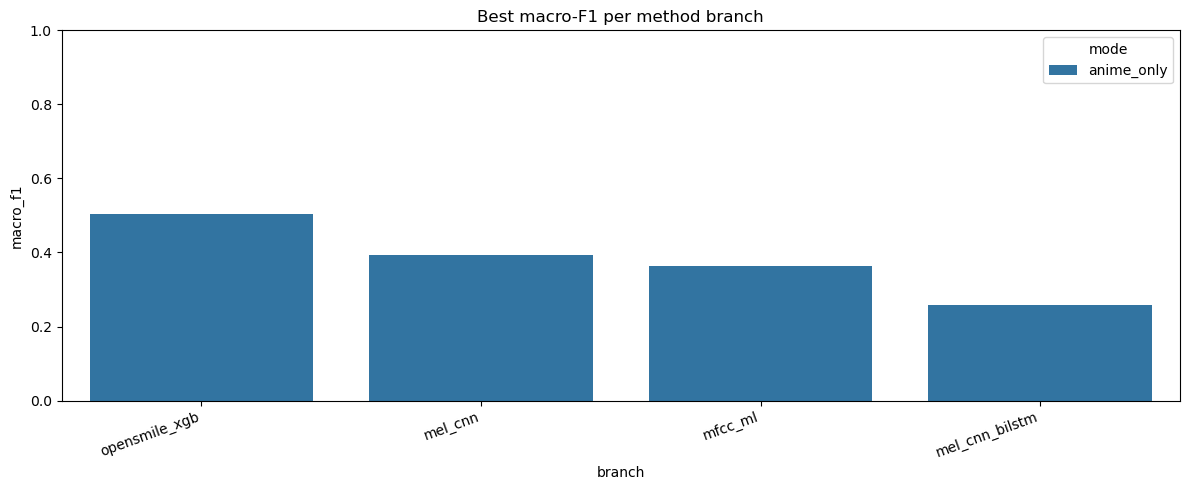

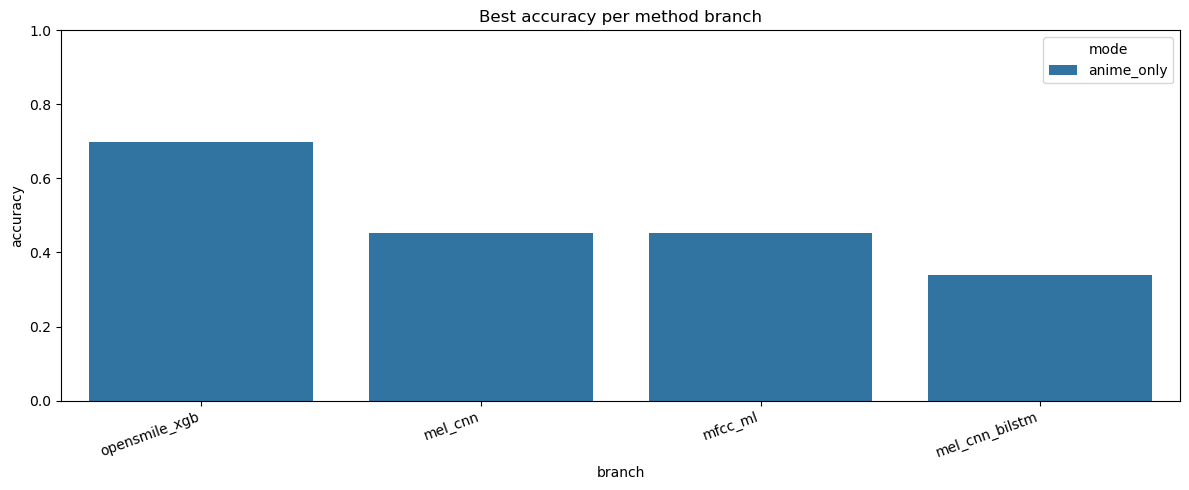

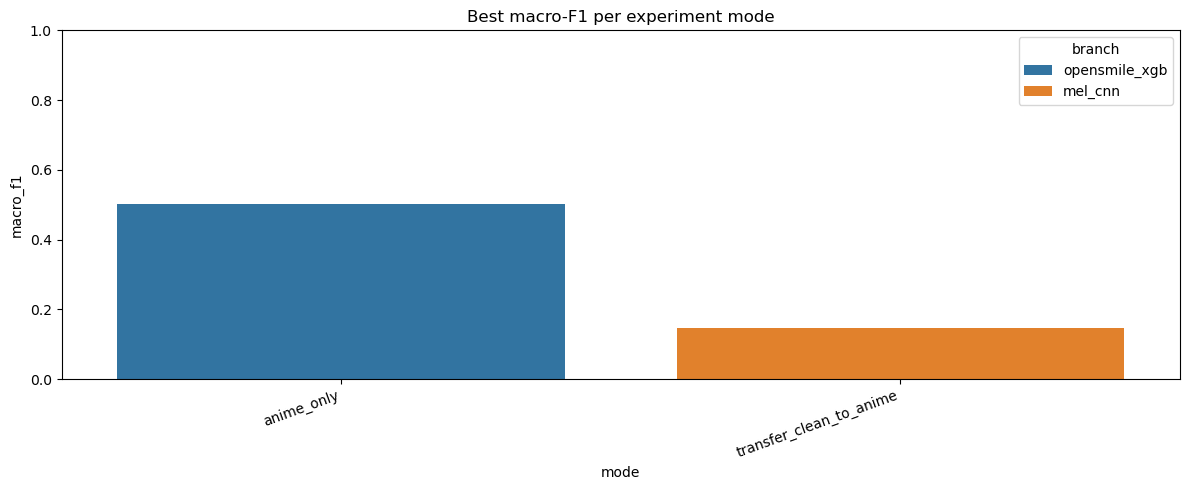

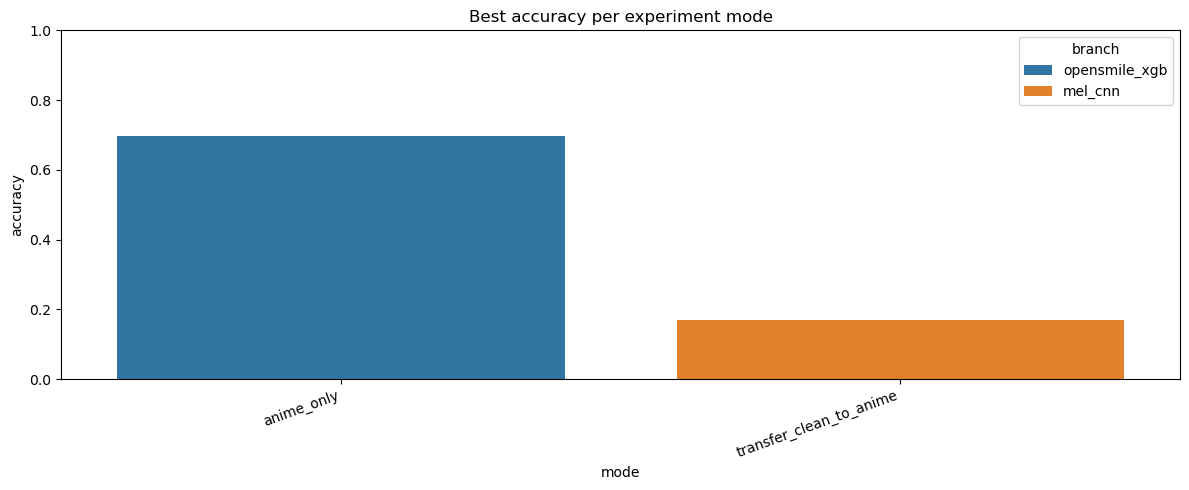

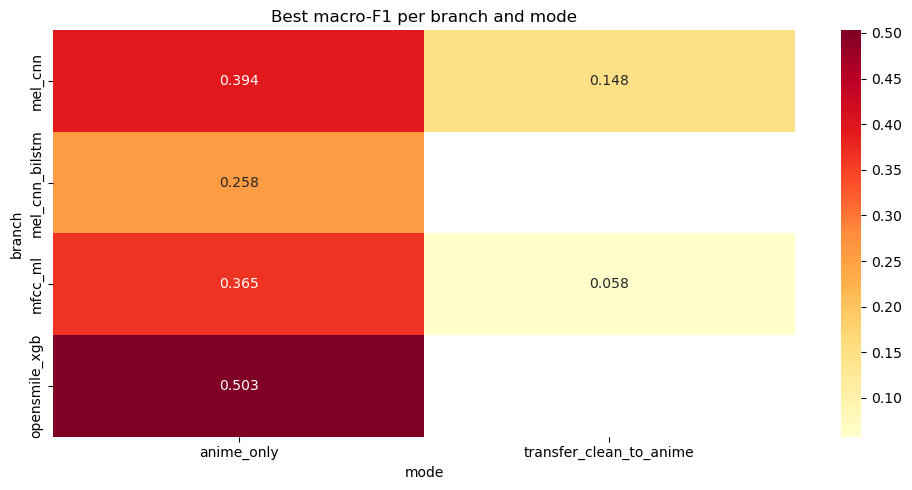

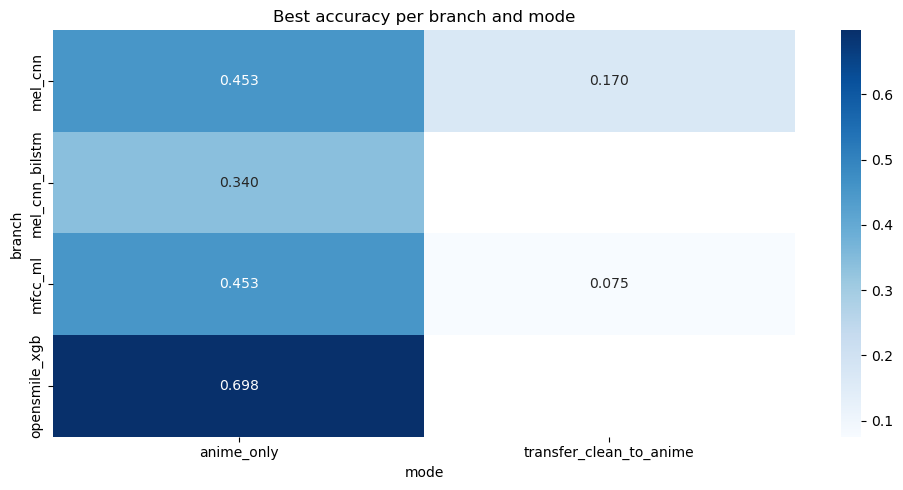

In [40]:
if "experiment_results_df" not in globals() or experiment_results_df.empty:
    raise ValueError("Run all experiments first.")

thesis_results_df = experiment_results_df.sort_values(
    ["macro_f1", "accuracy"], ascending=False
).reset_index(drop=True).copy()
thesis_results_df["run_label"] = thesis_results_df[["branch", "mode", "model_name"]].astype(str).agg(" | ".join, axis=1)

thesis_branch_mode_best_df = get_best_branch_mode_rows()
thesis_best_by_branch_df = (
    thesis_results_df.groupby("branch", as_index=False)
    .first()
    .sort_values(["macro_f1", "accuracy"], ascending=False)
    .reset_index(drop=True)
)
thesis_best_by_mode_df = (
    thesis_results_df.groupby("mode", as_index=False)
    .first()
    .sort_values(["macro_f1", "accuracy"], ascending=False)
    .reset_index(drop=True)
)

print("Best row per branch:")
display(
    thesis_best_by_branch_df[
        ["branch", "mode", "model_name", "accuracy", "macro_precision", "macro_recall", "macro_f1"]
    ]
)

print("Best row per mode:")
display(
    thesis_best_by_mode_df[
        ["mode", "branch", "model_name", "accuracy", "macro_precision", "macro_recall", "macro_f1"]
    ]
)

print("Best row per branch and mode:")
display(
    thesis_branch_mode_best_df[
        ["branch", "mode", "model_name", "accuracy", "macro_precision", "macro_recall", "macro_f1"]
    ]
)

plt.figure(figsize=(12, 5))
sns.barplot(data=thesis_best_by_branch_df, x="branch", y="macro_f1", hue="mode")
plt.title("Best macro-F1 per method branch")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=thesis_best_by_branch_df, x="branch", y="accuracy", hue="mode")
plt.title("Best accuracy per method branch")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=thesis_best_by_mode_df, x="mode", y="macro_f1", hue="branch")
plt.title("Best macro-F1 per experiment mode")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=thesis_best_by_mode_df, x="mode", y="accuracy", hue="branch")
plt.title("Best accuracy per experiment mode")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

macro_f1_heatmap_df = thesis_branch_mode_best_df.pivot(index="branch", columns="mode", values="macro_f1")
plt.figure(figsize=(10, 5))
sns.heatmap(macro_f1_heatmap_df, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Best macro-F1 per branch and mode")
plt.tight_layout()
plt.show()

accuracy_heatmap_df = thesis_branch_mode_best_df.pivot(index="branch", columns="mode", values="accuracy")
plt.figure(figsize=(10, 5))
sns.heatmap(accuracy_heatmap_df, annot=True, fmt=".3f", cmap="Blues")
plt.title("Best accuracy per branch and mode")
plt.tight_layout()
plt.show()

## 21. Save outputs

In [41]:

OUTPUT_DIR = Path("./dual_training_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

meta_tess_df.to_csv(OUTPUT_DIR / "meta_tess.csv", index=False)
meta_anime_df.to_csv(OUTPUT_DIR / "meta_anime.csv", index=False)
meta_all_df.to_csv(OUTPUT_DIR / "meta_all.csv", index=False)
if "meta_limited_df" in globals():
    meta_limited_df.to_csv(OUTPUT_DIR / "meta_limited.csv", index=False)
if "limit_summary_df" in globals() and len(limit_summary_df):
    limit_summary_df.to_csv(OUTPUT_DIR / "dataset_limit_summary.csv", index=False)
if "meta_filtered_df" in globals():
    meta_filtered_df.to_csv(OUTPUT_DIR / "meta_filtered.csv", index=False)
if "test_sample_manifest_df" in globals() and len(test_sample_manifest_df):
    test_sample_manifest_df.to_csv(OUTPUT_DIR / "test_sample_manifest.csv", index=False)

if "experiment_results_df" in globals() and len(experiment_results_df):
    experiment_results_df.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)

    summary = []
    for key, artifacts in all_artifacts.items():
        branch, mode = key
        train_meta = artifacts.get("train_meta")
        test_meta = artifacts.get("test_meta")
        if test_meta is None:
            test_meta = artifacts.get("test_df")
        result_match = experiment_results_df[
            (experiment_results_df["branch"] == branch) & (experiment_results_df["mode"] == mode)
        ]
        summary.append({
            "branch": branch,
            "mode": mode,
            "model_name": result_match["model_name"].iloc[0] if len(result_match) else "",
            "n_train": len(train_meta) if train_meta is not None else 0,
            "n_test": len(test_meta) if test_meta is not None else 0,
        })
    pd.DataFrame(summary).to_csv(OUTPUT_DIR / "experiment_split_summary.csv", index=False)
    if "thesis_results_df" in globals() and len(thesis_results_df):
        thesis_results_df.to_csv(OUTPUT_DIR / "thesis_results_full.csv", index=False)
    if "thesis_best_by_branch_df" in globals() and len(thesis_best_by_branch_df):
        thesis_best_by_branch_df.to_csv(OUTPUT_DIR / "thesis_best_by_branch.csv", index=False)
    if "thesis_best_by_mode_df" in globals() and len(thesis_best_by_mode_df):
        thesis_best_by_mode_df.to_csv(OUTPUT_DIR / "thesis_best_by_mode.csv", index=False)
    if "thesis_branch_mode_best_df" in globals() and len(thesis_branch_mode_best_df):
        thesis_branch_mode_best_df.to_csv(OUTPUT_DIR / "thesis_best_by_branch_mode.csv", index=False)
    if "non_mfcc_tuning_results_df" in globals() and len(non_mfcc_tuning_results_df):
        non_mfcc_tuning_results_df.to_csv(OUTPUT_DIR / "non_mfcc_tuning_results.csv", index=False)
    if "non_mfcc_tuning_comparison_df" in globals() and len(non_mfcc_tuning_comparison_df):
        non_mfcc_tuning_comparison_df.to_csv(OUTPUT_DIR / "non_mfcc_tuning_comparison.csv", index=False)
    if "non_mfcc_selected_params_df" in globals() and len(non_mfcc_selected_params_df):
        non_mfcc_selected_params_df.to_csv(OUTPUT_DIR / "non_mfcc_selected_params.csv", index=False)
    if "all_branch_tuning_results_df" in globals() and len(all_branch_tuning_results_df):
        all_branch_tuning_results_df.to_csv(OUTPUT_DIR / "all_branch_tuning_results.csv", index=False)
    if "all_branch_tuning_comparison_df" in globals() and len(all_branch_tuning_comparison_df):
        all_branch_tuning_comparison_df.to_csv(OUTPUT_DIR / "all_branch_tuning_comparison.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: D:\Telkom University Kuliah\Kuliah S1\Tugas S1\Semester 6\Proposal\Python Notebook\Test\dual_training_outputs


## 22. Recommended experiment set

Use `FULL_EXPERIMENTS` as the main research configuration for this derived notebook. In this version, `FULL_EXPERIMENTS` keeps all branches but only the reduced mode set:

1. `mfcc_ml` across `anime_only` and `transfer_clean_to_anime`.
2. `mel_cnn` across `anime_only` and `transfer_clean_to_anime`.
3. `text_only` as the transcript-based comparison across `anime_only` and `transfer_clean_to_anime`.
4. `audio_text_fusion` as the multimodal comparison across `anime_only` and `transfer_clean_to_anime`.
5. `mel_cnn_bilstm` as the sequence-aware audio model on `anime_only`.
6. `opensmile_xgb` as the advanced classical acoustic baseline on `anime_only`.

This derived notebook intentionally excludes `combined`, `tess_only`, and `tess_then_anime` from the experiment execution list while keeping transfer coverage for the audio, text-only, and audio-text fusion method families.